# Contrôle qualité

###### Equipe pédagogique : P. François, M. Genete, C. Toffano-Nioche, E. Jacquemet, G. Le Corguillé, J. Seiler, D. Puthier, T. Denecker et tout le staff

## Le fichier FastQ

Quelque soit le séquenceur ou l'expérience réalisée, nous obtenons des fichiers FastQ.

Tous se présentent de la même façon :
- Fichier texte contenant les lectures
- 1 lecture/read = 4 lignes
- Chaque lecture est définie par une séquence, un identifiant unique et un score

    @QSEQ32.249996 HWUSI-EAS1691:3:1:17036:13000#0/1 PF=0 length=36
    GGGGGTCATCATCATTTGATCTGGGAAAGGCTACTG
    +
    =.+5:<<<<>AA?0A>;A*A################

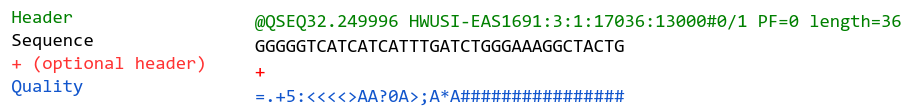

La ligne de header commence toujours par un <code>@</code>.

La ligne de séquence contient le même nombre de caractère que la ligne de qualité mais comment lire cette dernière ?

## Encodage de la qualité

Le score de qualité est encodé au **format ASCII** (American Standard Code for Information Interchange), cela permet qu'une base soit représentée par un caractère unique.

Si nous utilisions des scores qualités directement, il serait impossible de donner la correspondance exacte entre une base et son score.

Par exemple :

    @read1
    ATC
    +
    12523
    
Comment dire si les scores sont de 1, 25 et 23 ou 12, 5 et 23 ?

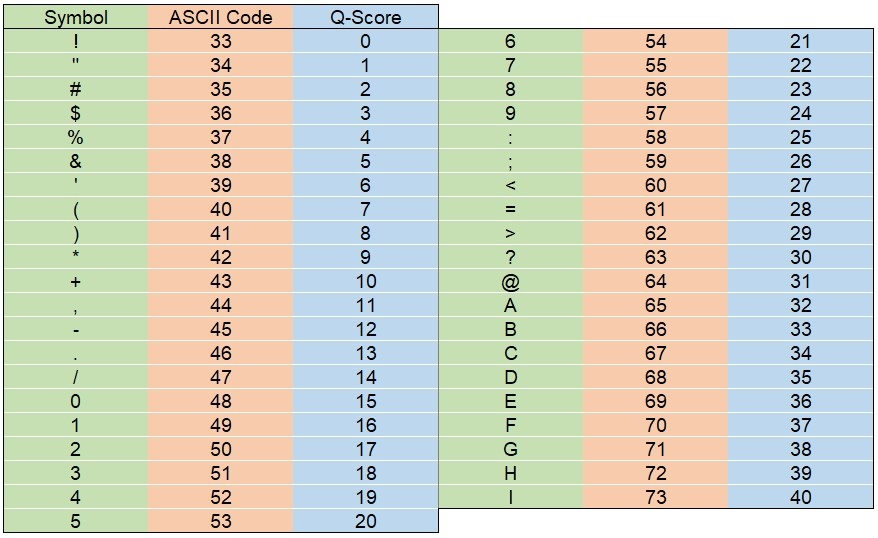

On a donc une correspondance entre chaque symbole et un score qualité, appelé **score Phred**.

Mais comment interpréter ce score ? 

On imagine facilement qu'un score de 40 sera préférable à 0 mais dans quelle mesure ?

Le score Phred peut être converti en probabilité d'erreur, elle même convertible en pourcentage de précision (ou accuracy).

La formule est la suivante :



Où *__Q__* = Le score Phred et *__P__* = La probabilité d'erreur d'identification d'une base.

Voici quelques scores utiles à avoir en tête :
    
| Score de qualité phred | Probabilité d'une identification incorrecte | Précision de l'identification d'une base |
|:---:|:---:|:---:|
| 10 | 1 pour 10 | 90% |
| 20 | 1 pour 100 | 99% |
| 30 | 1 pour 1000 | 99,9% |
| 40 | 1 pour 10000 | 99,99% |

En règle générale, on estime qu'un score doit être supérieur à 20 pour être acceptable.

## L'outil FastQC

Quand nous avons des fichiers avec plus d'un million de lectures, faisant par exemple chacunes 150 paires de bases, cela ferait plus de 150 millions de score qualité à vérifier... Hors de question de le faire à la main, donc.

C'est là que l'outil FastQC nous vient en aide !

Il permet d'obtenir un fichier HTML résumant l'ensemble des informations nécessaires pour estimer si notre run s'est bien passé et si notre échantillon possède des lectures de bonne qualité.

Tentons ensemble d'en saisir le contenu. Vous pouvez cliquer sur ce lien pour visualiser un [rapport complet](https://ifb-elixirfr.github.io/LinuxEBAII/data/siNT_ER_E2_r3_chr21_fastqc.html)

On note tout d'abord que devant chaque section, se trouve un code couleur : 

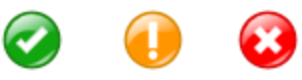

**Attention**: selon le type de séquençage effectué, cette information n'est pas toujours pertinente FastQC étant qualibré pour du DNAseq WGS.

### _Basic Statistics_ :

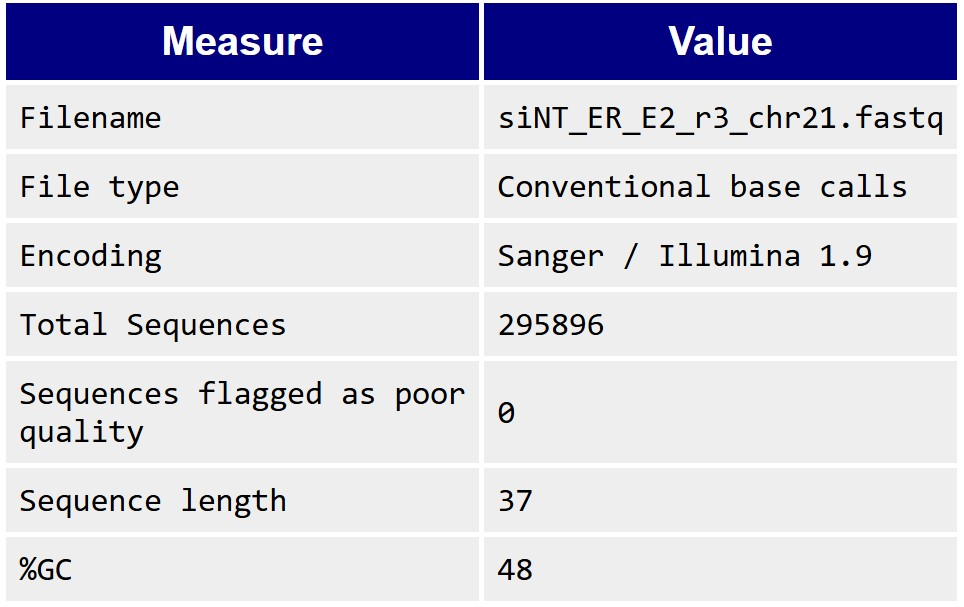

Explication :

Ce tableau récapitule les informations générales de mon échantillon. Ses valeurs dépendent surtout de mon espèce séquencée. Il ne peut jamais être en "erreur" ou en "warning", vous êtes les seuls à pouvoir l'évaluer.

### _Per base Sequence Quality_ :

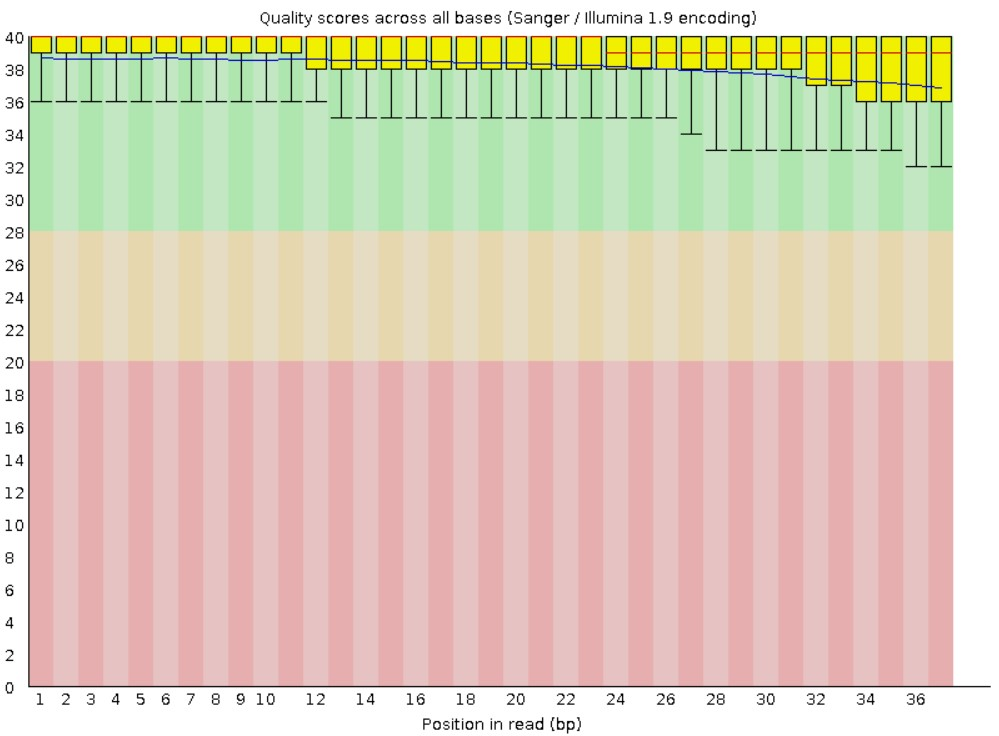

Explication :

Ce graphe montre une vue globale des valeurs de qualité de chacune des bases des lectures. 

Pour chaque position sur le read (axe des abscisses), on obtient une boîte à moustache des qualités. 
- En rouge on trouve la médiane 
- En bleu, la moyenne
- En jaune, l'intervalle inter-quartile (25-75%)
- Les moustaches supérieures et inférieures représentent respectivement 10 et 90%.

L'axe des ordonnées montre les scores de qualité. L'arrière-plan du graphique divise en 3 couleurs comme guide visuel mais reste à prendre avec précaution. La qualité des lectures sur la plupart des plateformes se dégradera à mesure que le séquençage progresse, il est donc courant de voir des qualités passer dans la zone orange vers la fin des lectures.

<div class="alert alert-block alert-warning">
Un avertissement sera émis si le quartile inférieur pour n'importe quelle base est inférieur à 10, ou si la médiane pour n'importe quelle base est inférieure à 25.
</div>

<div class="alert alert-block alert-danger">
Ce module signalera un échec si le quartile inférieur pour n'importe quelle base est inférieur à 5 ou si la médiane pour n'importe quelle base est inférieure à 20.
</div>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAAyAAAAJYCAIAAAAVFBUnAAAp6ElEQVR42u3dTXajyLaAUc1/MjmI
7GgGr/Pa1b4z8LXFTZWSn+DEDxDAPsurlsvp3JYVMvoSEH58GWOMMcaYpvNwFxhjjDHGCCxjjDHG
GIFljDHGGCOwjDHGGGOMwDLGGGOMEVjGGGOMMQLLGGOMMcYILGOMMcYYgWWMMcYYI7CMMcYYY4zA
MsYYY4wRWMYYY4wxAssYY4wxRmAZY4wxxhiBZYwxxhgjsIwxxhhjBJYxxhhjjBFYxhhjjDECyxhj
jDFGYBljjDHGGIFlrv0I/piyv770jonfadM/2vmW1D8S2t6Y5g+t+m8qIRx1vxXfM35IjcAyZvO0
Wvrf4i21bfcZA2spbi4TWM1v3uztPLCP9y9OYwSWMRltNHxwFF6jf6Yv/Wnic6bPnUuflvWRxCcs
fXeJG1P8JXK/aDqwgt9U7n2YjrlE3MTNpcfP6o3MDazI43O6RgXfUfoGz/4rJfLXgw/F1b8b/O5m
l0ZgGYFlzK7//E0HVtaTX2Q/TfCd9G3I/aLFT94132mTzy+75cGvlXg85H6h4Geu5n7xd1r8dyN7
qrICq9WPUu63uepoLCOwjNmqrnIDq6aQVvdV1DwzFfy7/HMnR3C/Tv1xveLASiPFd0hkt+Lql678
4EaBlfunkdUsO0QYvFuCfzfrKGr8p8YYgWXMwXuw0scmsjJidDRn9bk/fWNyj9Ytfd2vwGlJlV+0
LJJWv2jZHRJpwcTtTz/xJ25Sb4E1ezuz7q6l+6HsDkzcpbmBlTi7TmAZgWXMToG1eg5WwZNfeiOe
fnqO/1s86wm74OsGd1zteYgwd+9d8TlYBTtgilvqwMAq3oNV863lPhTLAsseLCOwjNk7sJZiqObk
j9XAWv3rBYE1fS5Jh0ju1018icovmhtkiS9afIfEdxlm3civumOsNScn1eTXIYcIC34EnINlBJYx
J8isxHGl2dfTxZ/z0q+rKngV4ayTlhO3/2v55WbxL5H7RYtfRfgVfjVc8A4p/tJLARF8FWF9YAUP
vOYeIozvwYq8LjJyDxS/kDb+vUf+/WCMwDLmZPXmTrjJAnnmPsUqu0yDEVjGeP42JwusYy8Eb7KW
xjIZgWWMJ29jjDECyxhjjDHGCCxjjDHGmN4Da/VVSMYYY4wxJiOwEhfc01jGGGOMMS0D68s5v8YY
Y4wxBYGV+6s2jDHGGGNMKrD86nJjjDHGmIMD6/t/f/3z6xGY70/7/c/v77fIJ39/2vfnk+8mB98G
OfhGJpPJZHLibY/Amj7zBQNr9Db7waVveHgyDt6V5LiclUF93hs2DWQymUy+QmCNyml2t5bAOlFg
/ec/qTeBRSaTyWTykYH1tXwdLIElsAQWmUwmkwVWNLCif1NgCSyBRSaTyWSBJbAEVreBVXPemI0O
mUwmkwWWDBJYjWUbHTKZTCYLLBkksAQWmUwmkwWWwBJYAotMJpPJAktg3Vx+Ph6rbwKLTCaTyQJL
YJHtwbJpIJPJZLLAkkECS2CRyWQyWWAJLIElsMhkMpkssLoILL/euE85Hlg1v5JZYJHJZDJZYG0V
WKvP5cVP/OTeZIFFJpPJZIElsMgCy0aHTCaTyQJLBgksgUUmk8lkgSVWBJbAIpPJZLLAElhkgUUm
k8lkssAiC6y/5ZpXPtrokMlkMllgkQVWY9lGh0wmk8m7Btbnv/5HITX9oMASWAKLTCaTyQIrFFif
RZX4oMASWAKLTCaTyQIrL7BGXTX7CQJLYAksMplMJgusjHOw7MEiCyybMzKZTBZYLQPLOVhkgWWj
QyaTyQJrk1cROkRIFlg2Z2QymSywagNrGk/TvVkCiyywyGQymSywnOROFlg2OmQymUx2HSwZJLAE
FplMJpNdyV2sCCyBRSaTyWSBJbDIAstGh0wmk8kCiyywBBaZTCaTBZZYubC8OgKLTCaTyQJLYJG3
kgUWmUwmkwWWwCILLBsdMplMFlgCiyywBBaZTCaTBZZYEVgCi0wmk8kCS2BdX34+HqtvAotMJpPJ
AmvXwMp6eo58ctkTP/m5S7pl3ebISw4FFplMJpMF1kxg9bmX4uayK2zZ6JDJZDJZYAksgbXfFbZs
dMhkMpkssMg3Cqx9zu6y0SGTyWSywCILLIFFJpPJZIElgwSWwCKTyWSywGodWD+vJJNBhwfW3/NM
nM8ksGx0yGQyWWCdYw/W+zX7MuhY+c9C/DTWkiywbHTIZDJZYG0YWJ+7N0YhNf1g8BDhu7Rk0P7y
+24XWDY6ZDKZTD4ysD6LavTB0fu552DNlpYM2uwQ4V939SBPG0tg2eiQyWSywNovsEax1fYk98/S
ElhbyNOQElg2OmQymUw+/hys0R6smkOEiW949BtWBFa9vHQ09i3P3s8Cy0aHTCaTBdbmgTVqqVaH
CFeTYulX2wmsoDzcV2lZYNnokMlkMvnIVxE2PwerOClWf7mwwPos0UjICiwbHTKZTCbvFFjTeOok
sOKnz5/oreG9MbrqWER+3wCBZaNDJpPJAuv4k9z7DKwzylk1tiTP/qnAstEhk8lk8vWvgyWw6uWs
8ArKQ2PdJLAegbHRIZPJZIHldxGSa+VbBVbN/WxzRiaTyQJLYJEz5Pc+sO0yKHIEVGCRyWQyWWAJ
rKsdfLQHy0aHTCaTBZbAIgssgUUmk8lkgSWD+pZfh+kElo0OmUwmCyyBRRZYAotMJpPJAksG9Sx/
N5bAstEhk8lkgSWwyAJLYJHJZDJZYMmgrgPrkW4sgWVzRiaTyQJLYJGzA+uVL0+BZaNDJpPJAktg
kQWWwCKTyWSywJJBHQdWorEEls0ZmUwmCyyBRRZYAotMJpPJAksG9RFYS40lsGzOyGQyWWAJLLLA
ElhkMplMFlgyqJvAmm0sgWVzRiaTyQJLYJGrAmvaWALL5oxMJpMFVnlgPT5mNqcE1k0Ca9RYAsvm
jEwmkwVWVWB9ltaopQTWrQLrs7EEls0ZmUwmC6wGgTXdXyWwbhhY78YSWDZnZDKZLLAanIM1yqnh
fYElsPoJrEdgBBaZTCaTOwqs2boSWPcMrKGx+gysuCywyGQymdzLqwinXSWw7hlYQ2MJLJszMplM
FlglgTU96Wr0usLZM9/Fyj0C66exBJbNGZlMJgusxie524N188B6fdpTYNmckclkssByHSxyy8B6
OU+BZXNGJpPJAsuV3MktA2toLIFlc0Ymk8kCS2CR2wbWI91YAotMJpPJAktgkQWWjQ6ZTCYLLIFF
3iCw4hftHMom0VgCi0wmk8kCS2CR8+R32Sw1lsAik8lkssASWOTCwFpqLIFFJpPJZIElsMjlgTXb
WAKLTCaTyQJLYJGrAmvaWAKLTCaTyQJLYJFrA2vUWAKLTCaTyQKrQWBlvQZNrAgsgUUmk8lkgZW9
ByvrG5ZB1wisz8YSWGQymUwWWAKL3Caw3o0lsMhkMpkssAQWuVlgDY0lsMhkMpkssAQWWWDZ6JDJ
ZLLAEljkjgNraCyBRSaTyWSBJbDIbQPrp7EEFplMJpMFlsAitwys16c9BRaZTCaTBdb/guk9o5Ca
flBgCSyBZXNGJpPJAisUWJ9FNfrg6H2BJbDSGTSc8C6wyGQymSyw5mNLYJFLM+gpsMhkMpnsHKyv
6R6s0ccFlsDKyqB0YwksMplMJt8lsIJ1JbAElsCyOSOTyWSBlfcqwtGRwaXkElgCazWDEo0lsMhk
Mpl88cCaHv5L15XAEljxDFpqLIFFJpPJZCe5CyxyeQbNNpbAIpPJZPIdr4P1mIzAEljXDqxHYGzO
yGQyWWC5kju5i8Cabaz+92Bl3c82Z2QymSywBBZZYAksMplMFlgCSwadPLCmjSWwyGQymSywBBZZ
YNmckclkssASWOTOAmvUWJ8Z9Hz98sL0m8Aik8lkssASKwIrI7DswSKTyWSywBJYAqs8g96NJbDI
ZDKZLLAEFllg2ZyRyWSywBJY5C4D691YAotMJpPJAqtBYEUuky2DBJbAIpPJZLLA2umulEFXCqyh
sfYJrN2y3uaMTCaTBZbAIhcGVjxW+gmsuCywyGQyWWAJLBnUtRwom6fAIpPJZLLAElhkgWVzRiaT
yQJLYJG7DqyfxhJYZDKZTBZYAosssGzOyGQyWWAJLHLHgfX6tKfAIpPJZPJlA+vzhWCjkJp+UGCR
BZbNGZlMJgusUGB9FlXigwKL3DCwXs5TYJHJZDL54oE16qrZTxBYZIFlc0Ymk8kCK+McrNk9WAKL
vF1gDY0lsMhkMpl82cAaHQoUWGSBZXNGJpPJAqvNqwh72IMV+a0sxb/C5XTyDQLrkW4sgUUmk8nk
8wXWNJ5624NFFlgCi0wmk8lXO8n98FcRki8fWMMvzxFYZDKZTHYdLIsksASWxzOZTCYLrNNeyZ18
h8BKNJbAIpPJZLLAsvwCS2B5PJPJZLLAElgCq4/AWmosgUUmk8lkgWX5BZbA8ngmk8lkgSWwBFY3
gTXbWAKLTCaTyQLL8gssgeXxTCaTyQJLYAksgSWwyGQyWWAJLIF14cCaNpbAIpPJZLLAsvwCS2B5
PJPJZLLAElh9y1m/RvoagTVqLIFFJpPJZIFl+TuSBZbAIpPJZLLAsvwCa6axBBaZTCaTBZblF1gC
y+OZTCaTBZbAElhdBta7sQQWmUwmkwWW5RdYAsvjmUwmkwWWwBJYvQbW0FgCi0wmk8kCy/ILLIHl
8Uwmk8kC608zDbP6QYElsPYMrKGxBBaZTCaTzxdYnwn1fv/znWl4WSSBJbA86shkMllglQfW6H2B
JbB2D6yfxhJYZDKZTD7xOVj2YAksgSWwyGQyWWC1DCznYAmsPgPr9WlPgUUmk8nkU57kvhRb0z/6
5/9+Rd/+/3fGW5wlB+SflQrLi8uaL0fK5i2HPvnn054byfX3hkcdmUwmn0ve7xys2X1XAktgCSyP
OjKZTBZYDU5ytwdLYPUZWC/2KbDIZDKZfI7Aekwmcg6WRepTfgTm1IH1fEVW+k1gkclkMrmLPVgF
V3K3SNeT+w+sobHswSKTyWSywLL8AktgedSRyWSywBJYAqvrwHqkG0tgkclkMllgWX6BJbDIZDKZ
LLAElsCKBdb6ufalgTX8dkKBRSaTyWSBZfnvFVhZssAik8lkssASWALr+MBKNJbAIpPJZLLAsvwC
S2CRyWQyWWAJLIHVR2AtNZbAIpPJZLLAsvwCS2CRyWQyWWAJLIHVTWDNNpbAIpPJZLLAsvwCS2CR
yWQyWWAJLIElsDzqyGQyWWAJLPKFA2vaWAKLTCaTyQLL8gssgUUmk8lkgSWwBFZngTVqLIFFJpPJ
ZIFl+QWWwCKTyWTydQPr/St4Vz8osARWb4H12VgCi0wmk8m9BNZnQr3fn/2gwBJYAsujjkwmkwVW
m8CyB0tgCSyPOjKZTBZY5edgfQaWQ4QC6yyB9W4sgUUmk8nk7gJr6bCgQ4QCS2B51JHJZLLAKjzJ
PRJbAktg9RlYQ2MVB9YjMB51ZDKZLLDyzsGaPQ4osATWrQJr/ZM96shkMllglZ3kLrAE1nkDa2gs
gUUmk8nk4wNrehzEdbAElsASWGQymSywXMmdLLAEFplMJpMFluUXWJtl0E9jCSwymUwmCyzLL7AE
FplMJpMFlsASWP0G1uvTngKLTCaTyQLL8gssgUUmk8lkgWWRBFbHgfVin9sFVuiqpB51ZDKZLLAE
FllgFe/Byro3POrIZDJZYAksgSWwBBaZTCYLLIFFFlj/yk+BRSaTyWSBZfkFlsDyeCaTyWSBZZEE
VteB9Ug3lsAik8lkgSWwyAJLYJHJZDJZYFl+gXV0YA2/nVBgkclkMllgkQWWwPJ4JpPJZIFl+QWW
wPKoI5PJZIElsMj3CaxEYwksMplMFlgCiyywBBaZTCaTTxVY71+gNptTAktgnTqwlhpLYJHJZLLA
2jCwPhNqlFOz1SWwriGHfmOxwBJYZDKZLLAEFnkf+XSBNdtYAotMJpMF1k7nYE1jS2CRBZbAIpPJ
ZIFVHlizu7IEFvmkgfX8TqqPt+//jD7yFFhkMpkssHY4yX02tgQW+Rp7sKY7sezBIpPJZIG17TlY
s6defY7AIgssgUUmk8kCq/Akd5dpIAssgUUmk8kCqzaw0jurBBb5SoE1aiyBRSaTyQLLldzJAktg
kclkMllgWX6BJbA86shkMllgCSzy5QPrs7EEFplMJgssgUUWWAKLTCaTyQLL8gssgeVRRyaTyQJL
YJHvEFjvxhJYZDKZLLAEFllgCSwymUwmCyzLL7AElkcdmUwmCyyBRb5JYA2NJbDIZDJZYAks8mUD
a3UEFplMJpMFluUXWBmBlSULLDKZTCYLLMsvsPoNrKGxBBaZTCYLLIFFFlgCi0wmk8kCy/ILLIHl
UUcmk8kCS2CR7xRYr8YSWGQymSywBBZZYAksMplMJgssyy+wBJZHHZlMJt8ysN4XHFr9oMAiXymw
Xp/2FFhkMpkssNoH1mdCvd+f/aDAIgssgUUmk8kCS2CRBZbAIpPJZPLR52BNDwgKLLLAElhkMpks
sMoDK1JXAot8scB6sU+BRSaTyQJrq5PcpyG1lFwWSWAJLIFFJpPJAmvlHKx4XQksssASWGQymSyw
8k5yT39QYJEvGVhDYwksMplMFljNAusxmaUPCiyywBJYZDKZLLBcyZ0ssAQWmUwmkwWW5RdYhwXW
I91YAotMJpMFlsAiCyyBRSaTyWSBZfkFlsDyqCOTyWSBZZEE1sUC6/WRp8Aik8lkgSWwyAJLYJHJ
ZDJZYFl+gXWzwHoExqOOTCaTBZbAIl82sBKN1WoPVta94VFHJpPJAsvyCyyBJbDIZDJZYAksssAS
WGQymSywBBZZYG0dWEuNJbDIZDJZYAksssASWGQymUwWWJZfYAksjzoymUwWWBZJYF01sGYbS2CR
yWSywBJYZIElsMhkMpkssCx/33LoapkCS2CRyWSywBJY5H3kMwbWtLEEFplMJgus7MB674RY/aDA
Igus3fbnedSRyWTyiQPrM6He73++Mw0vi0S+eWDFZYFFJpPJAmsmsEbvCyzyTQJr1FgCi0wmkwVW
+TlYAosssAQWmUwmC6yWgbUUVQKLLLAEFplMJguswpPcI7H1v8D69Sv69vt3xlucJZ9HXnzAzAk/
n7wsh8rmjxz65KQ8Dqwiuebe8Kgjk8nkLeT9zsGafamgwCLfPLA+G0tgkclkssAqP8l99mQsgUUW
WAKLTCaTBVZGYE2v3xO6DpZFIgssgUUmk8kCq/GV3C0S+R6B9W4sgUUmk8kCS2CRLxtY65dQL8qg
53dGLbx9/2d4R2CRyWSywBJY5AsGVpZsDxaZTCaTBZblF1idBtbQWAKLTCaTBZbAIgssgUUmk8lk
gWX5BZbA8qgjk8lkgWWRyAJLYJHJZLLAElhkgVUYWENjCSwymUwWWAKLLLAEFplMJpMFluUXWALL
o45MJpMFlkUi3ymwXo0lsMhkMllgCSyywBJYZDKZTBZYll9gCSyPOjKZTBZYlp98m8B6fdpTYJHJ
ZLLAElhkgXWmwAr9NmuPOjKZTBZYlp8ssPa5NzzqyGQyWWBZfoElsAQWmUwm3yCwvjfl048MI7DI
Auv9q3KGX5sjsMhkMllglQTW+3+njSWwyAJLYJHJZLLAWgms2T1Vn/8rsMgCS2CRyWSywLIHiyyw
tgqsobEEFplMJgss52CRBZbA8ngmk8nknvZgOURIzpVDF3MSWAKLTCaT7xZYox1XAou8m3ySwHqk
G0tgkclkssCyB4sssAQWmUwmCyznYJEFlsDyqCOTyWRXcrf8ZIElsMhkMllgCSyywEoF1usjT4FF
JpPJAktgkQWWwPKoI5PJZIFFFlgCy2ODTCaTBZblJ98nsBKNJbDIZDJZYAksssASWGQymSywBBZZ
YMUCa/2C8gKLTCaTBZbAIgusjWKlLLCWGktgkclkssASWGSBtWFgbfebGWtkjzoymSywBBZZYJ07
sOJyPwdM4+mWJftJIZPJAktgkQXWdQKrT9lPCplMFlgCiyyw5l+fOG0sgeXxTCaTBZbAIgssgbXf
/ey8MTKZLLAEFllgrQfWtLEE1v7njfkZJJPJAsvykwWWwHLwkUwmCyyBRRZYycAaNZbAElhkMllg
CSyywBJYAotMJgusbQLre+M1/cgwAosssFYD67OxBJbAIpPJAms+sD7/d/pHFokssASWwCKTyQIr
FVize6qmO64EFllgpQPr3VgCS2CRyWSBtbibyiFCssASWK6w5aebTBZYDhGSBdYegfX8zqjlt+//
PAWWK2z56SaTBZbAIgusVnuwhp1Y9mDd9uDjdr9U23aDTBZYlp9868AaGktgOfi46W223SCTBZbl
JwssgUUWWGSywHIdLLLAqg2sV2MJLLLAIpMFliu5kw+Ra043FlhiRWDZIpHJAsvykxvLPQfW69Oe
AovslY9kssASWGSBJbDIXvko3cgCS2CRBVbHgfVinwKLfK7r2rtiPllgCSyywBJYkoIssMhkgWX5
yTcLrKGxBBb5noHl4CNZYAksssDqIrA6eU0l2cVR7RsjCyyBRRZYnQfWI91YxbKkIDv4aCtKFliW
nyywBBbZvjHbOrLAElhkgdUosIZfniOwyGTbOrLAElhkgSWwyGSBRRZYAosssDoOrERjCSwy2baO
LLAEFllgCSwyua+zu2xFyQLL8pPvG1hLjSWwyORK2VaULLAsP1lgCSwyWWCRBZbAIgusdoE121gC
i0wWWGSBJbDIAqsqsKaNJbDI5FzZL+Ehnymwvh+OSzklsMgCq2FgjRpLYJHJXp9Ivl1gDf8OEFhk
gdU2sD4bS2CRyQKLfM3Aeu9QFVjkOwdW/CXiAotMFlhkgVW+B2v4iMAi3yGwcs//qA+sd2MJLDJZ
YJFvFFjv/xVYZIG1UWANjSWwyGSBRRZYAosssFoG1tBYAotMFljkWwTW9OwTgUUWWJsF1quxBBaZ
LLDILtNgkcgCq2FgvT7tKbDIZIFFFlgWiSywBBaZLLDIAsuV3MkCq+PAerFPgUUmCyyywLJIZIHV
MrCGxhJYZLLAIgssi0QWWG0D65FuLIFFJgssssCy/GSBVfJLeBKNJbDIZIFFFliWn9xYzvqFNucN
rERjCSwyWWCRBZblJ3ckXy+wOslNMllgkQWWwCILrHME1lJjFcuenslkW1GywCKTrxNYz9fVF9Jv
S/K0sQQWmSywyALL8pMFVvkerI/fBv0UWGSywCILLMtPFljNAmuUWXUXgFg7Yavo7K4zymJFYNmK
CiyBRSYLrM/M2kTe7jb3KYsVgWUrKrAEFpkssMa7sgSWwCILLLLAsvxkgdU4Kf6cHC+w9jhgKlYE
FllgCSwy+RaB9Ud+CqwdZLEisMgCS2CRybcKrPFrDAWWwCLb1pEFluUnC6w2SbGUWQKrXch6faLA
IgssgUUm3yywPjNr+iawuj19XroJLPItAuv7ATr9yDACiyyw+g+sJTlwJflN3pw+H7l2l1c+Cizy
7QLr83+nf2SRyALLPpvIxVH/3ZFm35hLSwgs8t0Ca3ZPlcAiCyyBtcGlJZ5OzBdYAot890OEAoss
sATWpifmO2/MtbsEFvm+geUcLPJJ5e2ekDzxH37emPu54aUlNv1J6TAKbUXJvZzk7lWE5BvKAqtz
efXMevdz1i/VPp0ssMjnPsk9sU/LIpEFlgzqUF7Z3eV+dsDUto7c1asIBRZZYAms88qFu7vczxc9
YGpbRz4ysKb/FBBYZIHlqe5i8uqZXu5ngWUrKrBcyZ1MFljkbS8t4eCjwLIVFVgCi0w+ZWBFLpHu
SdTBR7LAIgssy08WWJ7qHHysenM/CyyywLL8ZIHlqY7sqmACiyywBBaZvPHlEz3VkV0V7NhfBG5b
RxZYlp98jsDKusihpCB3dVWwrLdWe92O/UXgtnVkgWX5yQJLUpBPuW+s5ryxrX8RuG1dclv3FFgC
i0wWWJ74yZ3uG+v5F4Hb1s3K792Hn/sRBZbAIpMby9v9HjRPz2Tynqf8Tw8+2tZN5emdM77HBJbA
IpP3l3NPcs/65bhxOXTRrKIrbJHJ15DbXinjKv+YTKXnv38qsAQWmUzuSk7vz9vuUOymB3mzEtl+
putdpmEms8750x3cq7eYlQJLYJHJZIF1iOwSHhe+DtZfO7TO9tOdfcx0NisFlsAik8kC6xT7xmTQ
Ga+DVRArx/5010RhKLMElsAik8kCS2AJrFaH26KlddxP9195VCGvZJbAElhkMllgCSyB1fwVeenM
yjuJvt1tbi5f6dWaAotMJgssgSWwTnCh0bwXIbYKl/hZ+VveG3nXyxBYAotMJgssr08UWMderarZ
dSUOvTd2Ss9uA+v74Tj9yDACi0wmC6zDX58osPyqnIvJxZeKrb/6/JGB9f7faWMJLDKZLIMElsAi
HyvXXH1+p8Ca3VP1+b8Ci0wmyyBX2BJYthsdymVXn+9iD5bAIpPJMsjp8wLLT3fPcu7V5wUWmUwW
WGSBJbDIja8+L7DIZLLAIgssgUVufPV5gUUmkwUW2QUgBBa58dXnvYqQTCYLLLLXJwoscvnV510H
ywOLTBZYZIElsMiu5G6RyGSyWBFYAosssAQWmUwWWGSB5aebLLDIZLLAIgssgUUWWJafTBZYMkhg
CSyywBJYZDJZYAksgeWnW2AJLDKZLLDIfsuhwCILLMtPJl9Xznp6lkGuES+wyAJLYJHJ5G1lGSSw
BBZZYAksMpkssASWwPLTLbAEFplMFlhkgeVnkCywLD+ZLLBkkMASWGSBZZHIZLLAElgHBFbxSyv8
DJIFFplMFlgySGDNyDX3hp9BssAik8kCSwYJLIFFFliWn0wmCyyBVXoJ0/VPFlhkgWX5yWSyWLl5
YPV5b/gZJAssMpkssGRQd4G1z34mgUW+SGC9fzAEFplMFljkC8t+Bsn7Bda7q4KNJbDIZLLAIgss
ssCKBtbofYFFJpPbyhc4wEQWWGSBZQ8WmUy+jiwpyAKL7Bwsy08mkwUWWWCR7cFyiJBMJncmb3cV
pU7krKTYThZYfgYF1iaBNdpxJbDIZDK5/1P+vZhAYJHtwbL8ZDKZ3PiUf4ElsMjOwbL8ZDKZ7NWa
AovsSu4Ci0wmk72YoDqD+jxvzGODLLDIZDKZfOIXE/R5WNNjgyywyGQymeyUf4FFFliWn0wmk8kC
iyywBBaZTCaTb3VivhUkCywymUwmkxufPu9+JgssMplMJpPJZIFl+clkMplMJgssgUUmk8lkMllg
CSwymUwmk8lkgWX5yWQymUwmCyyBRSaTyWQyWWAJLDKZTCaTyWSBZfnJZDKZTCYLLIFFJpPJZDJZ
YAksMplMJpPJZIFl+clkMplMJl8psN6/vElgkclkMplMFlgNAuuzqyKNJbDIZDKZTCYLrIzAsgeL
TCaTyWSywGoTWA4RkslkMplMFlgOEZLJZDKZTCYLLMtPJpPJZDJZYAksMplMJpPJAktgkclkMplM
JrsOluUnk8lkMpnsSu4Ci0wmk8lkssASWGQymUwmk8kCi0wmk8lkMllgWX4ymUwmk8kCS2CRyWQy
mUwWWAKLTCaTyWQyWWBZfjKZTCaTyQJLYJHJZDKZTBZYAotMJpPJZDJZYFl+MplMJpPJAktgkclk
MplMFlgCi0wmk8lkMllgWX4ymUwmk8kCS2CRyWQymUwWWAKLTCaTyWQyWWCRyWQymUwmCyzLTyaT
yWQyWWDNlZPAIpPJZDKZLLCaBdbjNQKLTCaTyWSywBJYZDKZTCaTyV0G1pBWAotMJpPJZLLAahNY
764SWGQymUwmkwWWwCKTyWQymUzuL7AekxFYZDKZTCaTBZbLNJDJZDKZTCYLLMtPJpPJZDLZldwF
FplMJpPJZIElsMhkMplMJpMFluUnk8lkMpkssCwSmUwmk8lkgSWwyGQymUwmCyyBRSaTyWQymSyw
LD+ZTCaTyWSBJbDIZDKZTCYLLIFFJpPJZDKZLLAsP5lMJpPJZIElsMhkMplMJgssgUUmk8lkMpks
sCw/mUwmk8lkgSWwyGQymUwmCyyBRSaTyWQymSywyGQymUwmkwWW5SeTyWQymSyw5gLr8WcEFplM
JpPJZIHVILA+uyrSWAKLTCaTyWSywBJYZDKZTCaTycedgyWwyGQymUwmC6yWgeUcLDKZTCaTyQKr
8UnuXkVIJpPJZDJZYDU7ByteVwKLTCaTyWSywMo7yV1gkclkMplMFli1gfWYjMAik8lkMpkssFzJ
nUwmk8lkMllgWX4ymUwmk8kCS2CRyWQymUwWWAKLTCaTyWQyWWBZfjKZTCaTyQLLIpHJZDKZTBZY
AotMJpPJZLLAElhkMplMJpPJAsvyk8lkMplMFlgCi0wmk8lkssASWGQymUwmk8kCy/KTyWQymUwW
WAKLTCaTyWSywBJYZDKZTCaTyQLL8pPJZDKZTBZYAotMJpPJZLLAElhkMplMJpPJRwXW488ILDKZ
TCaTyQKrQWC9uyrYWAKLTCaTyWSywIoG1uh9gUUmk8lkMllgCSwymUwmk8lkgWX5yWQymUwmC6zP
M+KNMcaYzucZePPJ9/zkmtkksIwxxhhjTONXERpjjDHGmJXA+sq8DpYxxhhjjFkPLGOMMcYYI7CM
McYYY64eWPHDi/HDkcHT9QtuSfy1ADW3ua38lX8kd+nGrDqznxD86vG/W3YzZle5yTHuJrc58SBs
e5vPeD/3f5unn9bwNsf93R7ks2zxdmOHO7D4pzjyvRR8g+kN/lHfYMMVbH4HbrqJaP7UVvwNHhNY
Wa9YLDj7Pp41Zd9a29TL+gbL7o0CZ/YTgl999r4qAxN3+/RHPfeeWX3kVN4JS08zrW7zGe/n+M0r
e4g2uc1TrdVtjvvbPcgTN2D2gVSw/cnyC+7Amm+w+SYuvZHfZwWXvq9WK5j2265g5aOlbFtX8DMY
enJvmFZlT/lZuwE6CazmO9KCn59Y6Zr9KMEOiH/11e11+oMFT/xl90zWPRy/zcHAqr/NBZuP4H61
fW5zh4+NpX/aNrzNQX+jB3nZNxjfWAX9yi1MzTdY/5MS9PdcwawFKvgGV/us7QrW/LiV3QMF/8Lc
NbDaPknUZ1Pzg4+bHqkMfoPFgTW7a3e7wFr951RurCQ20223XImblHWbZx+EzW9zfGXjW9UdbnPi
H51lG8qlh2vxbd4usOL+Rg/yrP0TuduN+B9t9/SceI5s+8+nQ358glue7VZwh8CqfPooPj4W+RnM
fX4/OLA2qqvmu46Kd6Q13/9XeYiw8tmr5lBL5Q9D1g9Y5RN/w7tun9u89b/q2h7jaPhUl6C2OES4
Z2BtdOdnPT23+gZXzT0PEV54BYu/60p/ixUsfjRWPqesrmDeP9WOCqz6Z5T6wCqTmwdW2S8pqt9/
EPlHyexOnchXrzzOMvsVV1d5u3sm6zbHf/5b3eb6qsvavlz+Nrd9el49orTbnR/faV2z3Yj7NVuY
JrvoGn6Dh69g5Xede1B10xVsfpg+/pyStYKdBlbxCdrB8ye2OJZXeZQheFdsfVpY/bG54A9z+qU0
uYeucle5IK+XXoaTe5tnqS1u89Z7sLa7n5vc5sQRivrbfPj+j40eMIkbEPy3fs0RtIZbmJ0Dq8Df
eQXje2uKv8HdVrDy6aPgOSXrZzDvJfxHBVb9fsL6L7HpIcKym7r1qwgrX6JV8wqU+ld8xL+1Vluu
yn3gWQfjun0V4Q1vcz+vIvza5QBTkxdbFfuHHyJs+yrCQ1Yw6+uWbcMTH9nuVYRb/AwWvLiyfCfI
/oGVu59pn+tgZe3n2CIi97kOVpZT+bfqL5qy+lBxHSzXwXIdrPp/RaxeRanmG2y4Qaj/Kd5oBbP2
VG13JbNWW/74HqzmK9jk0VL2nBJZwex6+TLGGGOMMW13ObkLjDHGGGMEljHGGGOMwDLGGGOMEVjG
GGOMMUZgGWOMMcYILGOMMcYYgWWMMcYYYwSWMcYYY4zAMsYYY4wRWMYYY4wxRmAZYxY2Bzm/Zmv2
ry+9U3ZjdvuuI99LJ7fWGCOwjDHnC6wm0XCu2mgSWBrLGCOwjDHZgZX45fOjFvn8YK6wlDjpTxvd
hshXSe+ry/rrAssYI7CMMSWBNcqXxJ9G3pndOZSonOCnLb2f/mAksOI3SWMZYwSWMWYmsGZ37axG
RjywCsqpMrCmn7x6JFRgGWMEljGmZWCtfjBx5G7pndUdY00CK1GHow8KLGOMwDLGHBxYBSXUwx6s
xCcILGOMwDLG9BhYxSdjfe1+iHD1BDKBZYwRWMaYAwLrK+dVhJ/VsvoqwraBlb6dX8vHE9OBFX/9
o8AyxggsY4wpac2v2MlqxhiBZYwxRmAZYwSWMcYYY4zAMsYYY4wRWMYYY4wxpnD+CwR7QSQIeji5
AAAAAElFTkSuQmCC
" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAFlUlEQVR42s2XCUzTVxzHybIs0IgC
LYqyQ9RtmhjCNKKbikajYVc22NThNjYjeC0yWBESxAV1Ckw8QEUF5ChnS4FyFETucwWU+7ClHKKi
ImLI4nCz9bv3/pS7ra1HtM1Lm/b/fp/ve+93PQMABq9y6D/Bz+ANNvethWxPw3Xs3wx/YAb9Tn6j
/700AeZc1qccrhGPw2UNkk8Fx9voIceX9Tcz6Hf62/B/PPrsCxNgzjW043iyGjheRkOWQRzFt2IH
/Nl4DDFyHjJ6siDoSoZ/YwB2VuyEffpGzA5iK+izdA6d+8wCyHa+SYyEsj2N/jU/aaL0vbIf0sF2
tA92oOVBG+ruN6CqrwZldypR0FuMnBuXkX49C5GyaGwq3ASLU2ZKOpfaoLb0EmDibmLC8TQq5/iw
/vlIaA1xjxiyQTmaH7Sitr8ekr5qlN6pQP6tImTfyIXoeiYEnSmIlSfiooyHc20R8G84htUZq0Ft
UFvUpk4ChldO4H6sRzvKXdEw0ISmgRZc7a/DXwRccrscebcKIb5xCWndGeB3CsGTJyBCGoPQtnCc
ajlLjugk/qgPxO+1h7Eqyw7UFrWpbiemCKBbRlW7lrmgcaAZV/prUXm3CsW3y3D5VgGyenKQ2p2O
pM5k8NoTEC6Nxtm2MJxsPoPAxhM4XB+AA1cPwbvmADyqvPFLpQdsM1aodoIVqlUAdRp6bgv5HzBb
XHFXgqLbpci9mY/MnmykdIuQ2CFATHs8wqRRONN6ASeaTyOg8TgO1fnDl4C9anzhLvHCnkp3uJTv
gXOJC7YUOWN+0nww/jTJMSevvsHs+DRlSOsZFPaW4NLNPOLpYgi70pBAwFHtcbhwLRKnW8/jeHMI
OecgHKw7iv1XD2Jf9X78KtmHyNZoiOQi/FiyHZsJ+Ov87/DZZUesEq8H+4SxkjLUCmDinISPY74j
cm4Oe3RyVyriO/iIksUS8EWEtJ5DUFMwjhIH86s7Ap8rfvCs9oGbxBO7KtwQ3hKBrgdd6H94D3yp
gIAdsD7nc6wWb8DyzDWYy58HyhifJ8ZWT5NMoLGCJ48jsZ2COHkSCSkezl+LQHBLKI40BGJLsRPW
5qzDskxbLE5bDBuRDWwzV5DV2SGwNhCdAx0Yed172AdeWyyWpa/ColQbzE1+H7MTLcEOmKagrAkC
aAqlWWwZf6kqlMY8+gDZ3jXZazEz0Rym8TPUDg+yetl9Kca/HikeIUUmgEXizAnPml2YDsoaSduM
AJrHaSrdWvw9AYcR8LBHu0m4eJtvqRGsDS4k8DlJFlPnxM0AZVHmmABSTGg+31GxW+XRAfi51AWz
tKxaI/zxELNytXDVoCzKHBNAKhotKrsr9zIe7Vq+G5wEs9EJi1I+hFDKx7zkuTrAk7XCGQGERZlT
BLiSuN1Ltn2BcMEEeGF3PoaI8dzObFgJ3nsuuHoBqiNwLNgMu+x1ow9SByrsyoNC+ZiBPFb8h5Lr
hWrhqTKhTnD1R6BywuWZn0zYejq2FTuj/k7tKEz5RPlccLVOOBKG7DATtZO+yXNATW81npD3ZHha
ux5wTWE4kohoktA0cWPOelT3SkZFDMNT9ICbwCJplvpEND4Vm8ZqNrJBJWJIT7h5Ioek5a+wRLRU
cyoeX4y0GaMiaEjqCn9X8A62le0ADXGLYLbmYjS+HJtGTdf5TLUNa5E1Kc8+8K09iPkJVk8vx+Mb
Em1H8bTBTjDFF3lfMlmVNipLREt0a0gmt2TPIsKKZEv3Ki5TU2gZt8+1168lm9yU6noc1MO3FDkx
YNojhpH+YW2Gnf5Nqbq2nHHMWPVbbZNuA6firQghpZt2TRHSSGwn/eScYPNnb8s1XUxoDFtGWpD6
sAgrxSvhSi4juypJ31f6ExwLSNsl/BicAOMXczF5ba5mr83l9GWN/wE1f784zfWjGwAAAABJRU5E
rkJg" alt="Drawing" style="width: 50px;"/>
 pour séquençage Roche 454

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAAyAAAAJYCAIAAAAVFBUnAAAmFUlEQVR42u3dSXbbShJAUe5/M16E
J9pBTWr8x38HLJ+iTcFoMiM7EM2No4EsW7oiQBLPAAg+nsYYY4wxpus8LAJjjDHGGIFljDHGGCOw
jDHGGGMEljHGGGOMEVjGGGOMMQLLGGOMMUZgGWOMMcYYgWWMMcYYI7CMMcYYYwSWMcYYY4wRWMYY
Y4wxAssYY4wxRmAZY4wxxggsY4wxxhgjsIwxxhhjBJYxxhhjjMAyxhhjjDECyxhjjDFGYBljjDHG
CCxjjDHGGCOwzLXvwZOp+/atT0x8oS3/auffpP2e0PeX6X7Xar9RiZ/wqeVWvWQ8SI3AMmZ4Wm39
sfqZ2nP3GQNrK24uE1jdf73V3/ODfbx/cRojsIwpaKPXF2fhNftv+tbfJv7Nctu59c+KvpL4B1u3
LvHLVBOlaDqwgjeqdBmmYy4RN/GfuXX/yf6SpYEVuX8u11HFLUr/wqv/S4l8e/CumP3e4K1bXTUC
ywgsY3b97286sIo2fpH9NMFP0r9DKVq98W65pV3+fd1vHrQS94dSKPgvs7lffUurvzeyp6oosHo9
lEpvZvbnaCwjsIwZVVelgdVSSNl9FS1bpor/l093cgT367Qf16sOrPQPqV4gkd2KWbrxi4MCq/Rv
I2uz7hBhcLEEv7foKGr8UWOMwDLmw3uw0scmijJidjQnu+1P/zKlR+u23GfgtKRGtC6SsmjdAom0
YOL3T2/4E7/S0QJr9fcsWlxby6FuASYWaWlgJc6uE1hGYBmzU2Blz8Gq2Piln8TTm+f4/8WLNtgV
bnDH1Z6HCEv33lWfg1WxA6a6pT4YWNV7sFpuWuldsS6w7MEyAsuYvQNrK4ZaTv7IBlb22ysCa7kt
SYdIqZsgGtHSIEug1Qskvsuw6Jd8th1jbTk5qSW/PnKIsOIh4BwsI7CMOUFmJY4rrb6eLr7NS7+u
quJVhKs/J/2TE7//c/vlZnGiFK1+FeEz/Gq44AKpprcCIvgqwvbACh54LT1EGN+DFXldZGQJVL+Q
Nn7bI/9/MEZgGXOyerMQbrKCbLlPsZZdpsEILGNsv83JAuuzF4I3RavGajICyxgbb2OMMQLLGGOM
McYILGOMMcYYgWWMMcYYI7CMMcYYY4zAMsYYY4wRWMYYY4wxAssYY4wxxvQNrMfj8eOfH0UfP//5
WfpRSlAoFAqFQqGkPwSWOw2FQqFQKBSBZXVSKBQKhUIRWAKLQqFQKBSKwBJYFAqFQqFQKALL6qRQ
KBQKhSKwBBaFQqFQKBSBJbAoFAqFQqFQBJY7DYVCoVAoFIElsCgUCoVCoQisssB6TGY1pwQWhUKh
UCgUgVUcWNPSmrWUwKJQKBQKhSKw6gNrub9KYFEoFAqFQhFYTedgzXLq9bnAolAoFAqFIrAqA2u1
rgQWhUKhUCgUgdX6KsJlVwksCoVCoVAoAqsssJYnXc1eV7h65rvVSaFQKBQKRWBVnuRuDxaFQqFQ
KBSB5TpYFAqFQqFQKK7k7k5DoVAoFApFYAksCoVCoVAoAktgUSgUCoVCoQgsdxoKhUKhUCgCy+qk
UCgUCoUisAQWhUKhUCgUgSWwKBQKhUKhUASW1UmhUCgUCkVgCSwKhUKhUCgCS2BRKBQKhUKhCCx3
GgqFQqFQKAJLYFEoFAqFQhFYAotCoVAoFApFYLnTUCgUCoVCEVhWJ4VCoVAoFIElsCgUCoVCoQgs
gUWhUCgUCoUisKxOCoVCoVAoAktgUSgUCoVCEVgCi0KhUCgUCkVgWZ0UCoVCoVDuF1iPycxCavlF
gUWhUCgUCkVghQJrWlSzL84+F1gUCoVCoVAEVkFgzWJLYFEoFAqFQhFYredgrR4QFFgUCoVCoVAE
VmVgBetKYFEoFAqFQhFYZa8inB0Z3Eouq5NCoVAoFIrA2gys5eG/dF0JLAqFQqFQKAKrw0nuAotC
oVAoFIrAar0O1mMxAotCoVAoFIrAciV3CoVCoVAoFIHlTkOhUCgUCkVgWZ0UCoVCoVAElsCiUCgU
CoUisAQWhUKhUCgUisCyOikUCoVCoQgsgUWhUCgUCkVgCSwKhUKhUCgUgeVOQ6FQKBQKRWAJLAqF
QqFQKAJLYFEoFAqFQqEILHcaCoVCoVAoAktgUSgUCoVCEVgCi0KhUCgUCkVgudNQKBQKhUIRWFYn
hUKhUCgUgSWwKBQKhUKhCCyBRaFQKBQKhSKwrE4KhUKhUCgCS2BRKBQKhUIRWAKLQqFQKBQK5biB
9ZjMLKSWXxRYFAqFQqFQBFYosKZFlfiiwKJQKBQKhSKwygJr1lWr/0BgUSgUCoVCEVgF52Ct7sES
WBQKhUKhUARWZWDNDgUKLAqFQqFQKAKrz6sI7cGiUCgUCoUisFoDaxlPAotCoVAoFIrAGnuSu1cR
UigUCoVCEViug0WhUCgUCoXiSu7uNBQKhUKhUASW1UmhUCgUCkVgCSwKhUKhUCgCS2C501AoFAqF
QhFYVieFQqFQKBSBJbAoFAqFQqEILIFFoVAoFAqFIrCsTgqFQqFQKAJLYFEoFAqFQhFYAotCoVAo
FApFYLnTUCgUCoVCEVgCi0KhUCgUisASWBQKhUKhUCgCy52GQqFQKBSKwLI6KRQKhUKhCCyBRaFQ
KBQKRWAJLAqFQqFQKBSBZXVSKBQKhUIRWAKLQqFQKBSKwBJYFAqFQqFQKCcIrMefyX5RYFEoFAqF
QhFY+cCaJtT78+kny/CyOikUCoVCoQis+sCafS6wKBQKhUKhCKyyc7DswaJQKBQKhSKwegaWc7Ao
FAqFQqEIrM4nuW/F1vKv/vnPj7KP//4s/iglKBQKhUKhUJIfe5+DtbrvSmBRKBQKhUIRWB1OcrcH
i0KhUCgUisBqDazHYiLnYFmdFAqFQqFQBFbnK7lbnRQKhUKhUASWwKJQKBQKhSKwBJY7DYVCoVAo
FIFldVIoFAqFQhFYAotCoVAoFIrAElgUCoVCoVAoAsvqpFAoFAqFIrAEFoVCoVAoFIElsCgUCoVC
oVAEljsNhUKhUCgUgSWwKBQKhUKhCCyBRaFQKBQKhSKw3GkoFAqFQqEILKuTQqFQKBSKwBJYFAqF
QqFQBJbAolAoFAqFQhFYVieFQqFQKBSBJbAoFAqFQqEILIFFoVAoFAqFIrDcaSgUCoVCoQgsgUWh
UCgUCkVgNQbW489kvyiwKBQKhUKhCKx8YE0T6v356hcFFoVCoVAoFIHVJ7DswaJQKBQKhSKw6s/B
mgaWQ4QUCoVCoVAEVmtgbR0WdIiQQqFQKBSKwKo8yT0SWwKLQqFQKBSKwAqdg7V6HFBgUSgUCoVC
EVgdTnIXWBQKhUKhUARWa2A9FuM6WBQKhUKhUASWK7lTKBQKhUKhCCx3GgqFQqFQKAJLYFEoFAqF
QhFYAotCoVAoFApFYLnTUCgUCoVCEVhWJ4VCoVAoFIElsCgUCoVCoQgsgUWhUCgUCoUisKxOCoVC
oVAoAktgUSgUCoVCEVgCi0KhUCgUCkVgudNQKBQKhUIRWAKLQqFQKBSKwBJYFAqFQqFQKALLnYZC
oVAoFIrAElgUCoVCoVAElsCiUCgUCoVCEVjuNBQKhUKhUASW1UmhUCgUCkVgCSwKhUKhUCgCS2BR
KBQKhUKhnC+wHn9mNacEFoVCoVAoFIFVFljThJrl1Gp1CSwKhUKhUCgCS2BRKBQKhUKhfO4crGVs
CSwKhUKhUCgCqz6wVndlCSwKhUKhUCgCq/4k99XYElgUCoVCoVAEVs05WKunXk1HYFEoFAqFQhFY
lSe5u0wDhUKhUCgUgdUaWOmdVQKLQqFQKBSKwHIldwqFQqFQKBSB5U5DoVAoFApFYAksCoVCoVAo
AktgUSgUCoVCoQgsdxoKhUKhUCgCy+qkUCgUCoUisAQWhUKhUCgUgSWwKBQKhUKhUASW1UmhUCgU
CkVgCSwKhUKhUCgCS2BRKBQKhUKhCCx3GgqFQqFQKAJLYFEoFAqFQhFYAotCoVAoFApFYLnTUCgU
CoVCEVhWJ4VCoVAoFIElsCgUCoVCoQgsgUWhUCgUCoUisKxOCoVCoVAoAktgUSgUCoVCEVgCi0Kh
UCgUCuUcgfX4M9kvCiwKhUKhUCgCKx9Y04R6f776RYFFoVAoFApFYAksCoVCoVAolE+fg7U8ICiw
KBQKhUKhCKz6wIrUlcCiUCgUCoUisApOcl+G1FZyWZ0UCoVCoVAEVuYcrHhdCSwKhUKhUCgCq+wk
9/QXBRaFQqFQKBSBlQ+sx2K2viiwKBQKhUKhCCxXcqdQKBQKhUIRWO40FAqFQqFQBJbVSaFQKBQK
RWAJLAqFQqFQKAJLYFEoFAqFQqEILKuTQqFQKBSKwBJYFAqFQqFQBJbAolAoFAqFQhFY7jQUCoVC
oVAElsCiUCgUCoUisAQWhUKhUCgUisByp6FQKBQKhSKwBBaFQqFQKBSBJbAoFAqFQqFQBJY7DYVC
oVAoFIFldVIoFAqFQhFYAotCoVAoFIrAElgUCoVCoVAoAsvqpFAoFAqFIrAEFoVCoVAoFIHVMbAe
fyb7RYFFoVAoFApFYOUDa5pQ78+nnyzDy+qkUCgUCoUisOoDa/a5wKJQKBQKhSKwys7BElgUCoVC
oVAEVs/A2ooqgUWhUCgUCkVgVZ7kHomt34H140fZx8+fxR+lBIVCoVAoFEryY+9zsFZfKiiwKBQK
hUKhCKwOJ7mvnowlsCgUCoVCoQisgsB6LCZ0HSyrk0KhUCgUisDqfCV3q5NCoVAoFIrAElgUCoVC
oVAElsByp6FQKBQKhSKwrE4KhUKhUCgCS2BRKBQKhUIRWAKLQqFQKBQKRWBZnRQKhUKhUASWwKJQ
KBQKhSKwBBaFQqFQKBSKwHKnoVAoFAqFIrAEFoVCoVAoFIElsCgUCoVCoVAEljsNhUKhUCgUgWV1
UigUCoVCEVgCi0KhUCgUisASWBQKhUKhUCgCy+qkUCgUCoUisAQWhUKhUCgUgSWwKBQKhUKhUASW
Ow2FQqFQKBSBJbAoFAqFQqEIrObA+pVNy6+8RmBRKBQKhUIRWB0C6/3HZWMJLAqFQqFQKAIrE1ir
e6qmfxRYFAqFQqFQBJY9WBQKhUKhUCjOwXKnoVAoFAqFcp89WA4RUigUCoVCEVgdAmu240pgUSgU
CoVCEVj2YFEoFAqFQqE4B8udhkKhUCgUiiu5W50UCoVCoVAElsCiUCgUCoUisAQWhUKhUCgUisCy
OikUCoVCoQgsgUWhUCgUCkVgCSwKhUKhUCgUgWV1UigUCoVCEVgCi0KhUCgUisASWBQKhUKhUCgC
y52GQqFQKBSKwBJYFAqFQqFQBJbAolDGKI/wvJWCb6HUKu7JFApFYLnTUI6idNmQ/y6DktuSehxR
qpSKjPN4oVAElsCiUHZSpM+dFY8XCkVgCSwKRWBRmpR9Dnd6VFIoAktgUSiihGI/GYUisAQWhSKw
KJfbT+ZRSaEILKuTIrBECWW44rFPoQgsq5MisCgUgUWhCCyBRaHYkFNccsIzDEVgCSwKRWBRKB77
FMoJAuvXo3f5ldcILMqFr7FuQ05xyQn7ySgCa7/Amv5x+VdWJ+Usig05hWI/GYXymcBa3VO13HEl
sCgCi0KheIahCKzWPVgOEVIEFoVC8QxDEVgOEVIoNn4UisCiUASWO43Tz7dPp+1y/WubWArFVekp
FIHlTmPfko0fheKiqZ4tKQLL6qQILAqF4tmSIrBcB4sisCgUisCiCCxXcqcILJslCkVgUSgCy+qk
2CxRKBTPlhSBJbAoAotCoQgsisASWBSBRaFQBBaFIrDcaSg2SxQKxbMlRWAJLIrAolAoAosisAQW
RWBRKBSBRaEILHcagWWzRKEILM+WFIElsCgCi0KhCCyKwBJYlP6Kt2GmUCgCiyKwBBZluGKzRKFQ
PFtSBJbAoggsCoUisCgCS2BRBBaFQhFYFIrAsjoFls0ShULxbEkRWAKLIrAoFIrAoggsgUXpoRS8
JNAGg0KhCCyKwBJYFFeoolAoAotCEVjuNAKLQqEILM/JFIFldQosGwwKheI5mSKwBBbFBoNCoQgs
isDaKbB+PUi2ckpgCSwbDAqFIrAoAqtbYL1eOyawBJYNBoVCEVgUgVUWWO8X4Qssig0GhUIRWBSB
NXYP1usrAktg2WBQKBSBRRFYfQLr/UeBJbBsMCj7KwXXv7XEBBaFIrCOuTornsorrn5+WMWG/M5r
/8jKv//mPxoV6SOwKAJr18BaPh/dbQ+WJ9lbBVbFhjz6LZTDKzvEokelXKAILJdp8PR3bmW3PSXS
hxJXPPblAkVgCSxPf6cPLLlAucB+MoElFyiu5C6wpI/AolA6KwJLLlAElsCSPgKLQhFYNuQUgSWw
RInAsiGnHF658Kn0coEisASW9BFYcoHiVHqBRRFYAktgCSwbcorAElgUisASWBSBRaHc6rWKcoEi
sASW9BFYNuQUZ3o9BBZFYAksgSWwbGIplEMfiJQLFIElsKSPwLKJpVAEFkVgCSyBJbBsYikUgUWh
CCyBRRFYFIrAkgsUgbVrYHmv+zsrdWvfJpZCEVgUisCyb4mSCiwbPwpFYMkFisASWBSBRaG42lbm
altygSKwBBZFYFEolM5vXC0XKAJLYFEEFoVCEVgUgSWwpI/AsvGjUAQWhSKwRAlFYFEoAksuUASW
wKIILAqFIrAoAktgSR+BZeNHoQgsCkVgiRKKzRKFIrDkAuUKgfXr8bD8ymsEFkVgUSgUgUURWB0C
a/rH5V8JLErFuwSWvoWRjR+FIrDkAuXEgbW6p0pgUbwNM4VCEVgUgdX/EKHAoggsCoUisCgCa0hg
OQeLIrAoFIrAogiszie5exUhRWBRKBSBRRFY3U5yT+zTElgUgUWhUAQWRWA1vYpQYFEEFoVCEVgU
gdUaWMtXzgssisCiUCgCiyKwXMld+ggsCoUisCgUgSVKBJbNEoUisOQCRWAJLIrAolAoAosisAQW
RWBRKBSBRRFYAkv6CCwbPwpFYMkFisASWBSBRaFQbMgpAktgUQQWhUIRWBSBJbCkj8Cy8aNQBJZc
oAgsgUWxWaJQBJZcoAgsgUURWBQKRWBRBJbAkj4Ci0KhCCwK5YaB9QiPKBFYNksUisCSCxSBVbkI
RInAslmiUASWXKAILIFFEVgUCkVgUQSWwKIILAqFIrAoFIElSgSWzRKFIrDkAkVgCSyKwKJQKAKL
IrAEFkVgUSgUgUURWAJL+ggsGz8KRWDJBYrAEiUUgUWhUOQCRWAJLIrAolAoAosisPoG1q/Hw/Ir
rxFYFIFFoVAEFkVgdQis9x+XjSWwKAKLQqEILIrAygTW6p6q6R8FFkVgUSgUgUURWD33YAksisCi
UCgCiyKwBBZFYFEoFIFFoQgsUSKwbJYoFIElFygCS2DdXHmEx2aJQhFYcoEisLyKkBINLJslCoUi
sCgCy3WwKAKLQqEILIrAciV36SOwKBSKwJILFIElsASWzRKFQhFYFIElsCgCi0KhCCyKwBJY0kdg
USgUgSUXKAJLlAgsmyUKRWDJBYrAElgUgUWhUAQWRWAJLIrAolAoAotCEVjSR2DZLFEoAksuUASW
wKIILAqFIrAoAktgUQQWhUIRWBSKwJI+AstmiUIRWHKBcvfAeoRHlAgsmyUKRWDJBYrAqtyDJUoE
ls3SZ5WvxyP4YYlRBBZFYAksisCijFIKmkzGUQQWRWAJLIrAumH6yDj3MYFFoQgs6SOwbJYoFIEl
FygCS2BRbDAo45Xwrqvvj+vt8xNYcoEisESJwLJZOmWUHPajYokFf7L7mMCiUASW9BFYlNdXRkXJ
DddLOrx6ZZz1IrAoAktgUQTWUZSmbb/10nZhi6IDkSP2LF77hH25QBFYAosisD528M4Sk9dXzWu5
QLl1YL2vui6wKAKrSAkeJHLRAUqvA8QCSy5QThNY764KNpbAuphS8K5Ht9/4Fe1jsMQoI5TTnekl
FygCa/65wLpPYNn4RbdklhjleJdmLe5+gUURWPZgUQTWnkrmWMwVr7FOucM9+bP/VZALFOdgOQdL
YN1zs3TQ//dTKHse7B53ppdcoNiD5RDh8BPDo6c6tZ0dVaHcb7O08gp5p59TKBv7wAQWRWCVB9Zs
x5XA8so7GwxLjHLea3qN+a/CX48dgUURWPZgCay7K6d+cTuFco1D6nKB4hws52AJrOso6Q2AJUah
tL9cI3gqvVyguJK7K7kLrAso0TOrLDEK5bOn0ssFisASWALrRE/llhiFco4Lja5nllygCCyBJbAO
o7gEKIVy1iu5zzNLLlAElsASWJ9V/npJoCVGoZz5rXK+M0suUASWwBJYn1JmJ7BbYhTKkS8GUZxZ
coEisASWwNpZWX1toCVGoVzpzZ6LM0uUUASWwPJU3vjeapYYhXL5wJpecEsuUASWwBJYAxXvEkih
3C2wCjJLlFAElsDyVF6hpOvKEqNQLhxYy8vHV3wM2pDnr6cqfQSWwBJYR35TDkuMQrl5YDVuYldi
q1ZZ7bahGSewBNaB0ucRnulTRvRb2hRP5XGl7m1lbfwoFIEVja3Yzw+++Y+LpgqsWwSWp79TK+/n
PkuMQhFY4zbkidha+SsXTRVYAsvT38mVL0uMQhFYO2/I56dtNSjtByIFlsASWJSeyvdl2S0xCkVg
nXlDXnnFVIElsAQWpbvyPpm98ZrR1guFIrAOotRklsASWAKL0lGZv++NJUahCKyr5IKr0gssgeVJ
9gPK8kIMlhiFIrAulguuSi+wBJYn2V2V1WtcWWIUisC6ZC6EGssSE1gCi9KopN5Y0BKjUATWFXMh
vyvLEhNYAovSoiSuz26JUSgC69q5kGosS+x6gfW+7LjA8iQ7Wsm/c7MlRqEILIFliV0gsKZdFWks
gUURWBQKRWBVK5uNZYldOLDswfIkO1TJvnmzJUahCCyBZYldJ7AcIvQku4OSrStLjEIRWDfJhcY3
5BFYDhEKLMpb+bLEKBSBJRcElsDKBNYjPC2BVaF4+jug8nqTQUuMQhFYciHVWJaYwOr1MIsElqe/
syuv95a3xCgUgSUXBJbAElgUgUWhUATWWGXeWJaY62AJLErwW151ZYlRKAJLLggsV3IXWJReypcl
RqEILLkQbSxLTGAJLEqkriwxCoUiFwSWwBJYlG7K66IMlhiFQpELBY1liQksgUXJ1pUlRqFQ5ILA
ElgCi9JHmV5Q1BKjUChyoaCxLDGBJbAoAotCoQgsgSWwBJanvz2U2fvhWGIUCkUuFDSWJSawBBYl
W1eWGIVCkQsCS2AJLEqTsvpezlPl6/+XbYh8WC8UisC6Zy7UNJbAElgC66rKq4ssMQqFIrAElsAS
WJ7+OiiJtLLEKBSKwKpQihtLYAms14M5OJ6Yjq+k08oSo1AoAktgCaz9AssT0wWU7I4rS4xCodiQ
VytljWWJCSxPTBdQXmlliVEoFIElsASWwKJ0UH6nlSVGoVAE1niloLEsMYHliem8yvc7N1tiFApF
YAksgSWwKI3K9HQrS4xCoQis3ZRoY1liAssT07mU5ZnslhiFQhFYAktgCSxKjfK+oLolRqFQBNZn
lVBjWWICyxPTAZXlG9VYYhQKRWAJLIElsCgFyjKnLDEKhSKwjqzkG8sSO0Vg/XpICKzzKtm3UbbE
KBSKwBJYAmvvwHpdR1JgHfbgXfbDUzmFQhFY11MyjWWJCSz7lspqyVM5hUIRWHJBYJ09sF5pJbDs
W6JQKBSBdTQl1ViW2JED691VNw8s+5YoFApFYAksgSWw6t/4JXsOuCdZCoVCEVjHUTYbyxI7bGA9
FnOlwEqElKc/CoVCEVgnUtYbyxJzmYYdnzJcNpNCoVAE1gWVlcayxATW4AfzdB+Vpz8KhUIRWNdU
pmcDW2Ku5L7Ddck9/VEoFIrAuovy3ViWmMDq9WB2XXIKhUIRWHLhd2NZYgKr/cGcOK3K0x+FQqEI
rLsp7+ssWmICq+kKVZ7+KBQKRWDJhdbGElgC633ZdE9/FAqFIrDkwqpS3FgC6+aBVfySQE9/FAqF
IrBuqZQ1lsA6XWD1O/3c+/dRKBSKwJILBcp002mJXXYPVvUFFL6/xRMThUKhCCy5UKiEGktgXeUQ
YegSoN7EhkKhUASWwGpX8o0lsK54DtbKm9isH1X0xEShUCgCS2BVKenGWn2X3umHwDr3Se6Jtwv0
xEShUCgCS2C1KGX9tPZuPH/9Y4F1q7fKoVAoFIrAooy+Xvx3bAksgUWhUCgUgUXpfjGIgtgSWAKL
QqGUKsGZKtFvaVOsfYFF2e1U+kxpCSyBRaHcXClNn7Wn2kfp09/vH1h2TklGqcs49zGBRWlRNjNL
YAksCsXGb3T6HFbZJ0ndx0TJ5ZWVxhJYAotCufPBO4G1wxK7+eFOUXITZd5YH70tiRdLCiyb2EMr
X9nrqPz5sMT2VK6UPjdXBJb0OaPy1+HCz92W9KUoBJZNLIUisG4dWJc5EClK7qb8bqwP3Zbshb4E
lk0shSKwKMPPJxNYlBFK8Iqm3W9LBBVYNrEUisCiCCzpc2KluLHabkuQ2zuw3nubBRaF4gIK0kdg
CSxKF6VsV1bDbYkruwbWtKsijSWwKBQXUKBc4BWRAotyqH1LLRl30Ms0CCwKRWBRvFZRYFE+e3bU
PgciP3YOlsCiUAQWxWsVO75WUZRQoocLy5WKU+k/E1jOwaJQXAKUQul7ppcooUQza3xdfewk96JX
EbrUJMXp504/pwgsgUWpUNYza5erbe19Dla8ruzBolBsyClOpW/ZFytKKOuZVVpXpwgs18GiOHjn
4B2Fso8iSijrmVVaVwcPrOVWRGBRXJzTJpZCEViUPZW/3sdw5FtKu5K7XKAILApFYImSeynpzFr5
K4FlQ04RWBQKRZRQIspqZq2Hl8CyIacILAqFIkoocWWaWZu7tQSWDTlFYFEoFFFCKVUy52YJLBty
isCiUChygfJxRWDJBYrAolAEllygCCwbcorAsomlUGzIKQJLYFEoNn4UisCiCCyBRaEILApFYFEo
AsuGnOJtmCkUilygCCyBRfE2zDaxFIrAoggsgdVB+XpdZyPw8VYKvuWKisCiUCgCiyKwBBbFHiwb
PwpFYFEoAksuUAQWhSKw5AJFYMkFisCiUCg25BSBJbAoAsvGj0IRWBSBJbAoFIFFoQgsCkVgyQWK
wKJQKHKBIrAEFkVg2cRSKAKLIrAEFuXSSvSy7DZ+FIrAolAOGFjvDZXAoniXQAqFIrAoAqtDYL27
KthYAosisCgUisCiCKxoYM0+F1gUgUWhUAQWRWAJLIrAsvGjUAQWhSKwRAlFYFEoAksuUATW9Iz4
0vkKf+z8LcYYYwbNYZ/5fcudv6V9hgSWMcYYY4zp/CpCY4wxxhiTCaxn4XWwjDHGGGNMPrCMMcYY
Y4zAMsYYY4y5QWCVHmEsPS4ZPHu/8XeLv0yg120ZpxR9y+q/jH8xu5oqflT1yu37C6z+bQt6qNsy
aGU1/tistfwHW4+pxtuSfpwOerwMui3tv3bQ2rotHe9j7Ysovl6W39j3sf+p2+Kxf9nAqnjpYvXJ
+I1buBG3pUKsuPnxb1m9Cavfnv2Z8e/q9eqKrae/Xr9AcMva5QbufFsGraz03anjfSy7djrelq1n
6sb7QPq7Bt3HthZgr/tY3WKpvo+NsEY8iA51Wzz2hzZWzx/d+F+oim3PYQNr6K61ou9KPI12eVRE
yuP1+epvUvTrlf5XqeNtifwHqMsN3P+2xH/tituS/g0rbmD8sbD1HNrxtlSUSvUS6HhbGn/toJX9
+d3Xy+jnsR0e+zvfln0e+71uYHyL2fexf+I9WC3fWBFMQw9E7nbssujmV9+ZujzJTn+B0ff1cVES
f3bouPEr2r3RclvGPckmbkKXKMluPEY8yW79tF63ZbaKZ8uq121JPx+238cSP7/vE0Lj3Sn+H5LE
HWyf29L+2G+5O/W6Lb0e+8FD9gJrv7oauqOocdfa0D2FjYeoRvwvds9DhLsF1nPYIcKt/zT3ui2j
j+cO3VOSrqvu66XoV+2+1+fZ+3DniMd+6R64576HonrtJR16iDB9CtGIvaQfP0R42PVy7sBquYUV
JyHtoAwNrMb/dgf/51H9UInv5sl+8bOBFTmnNb0JabmB+9+W+K9ddFu6H+5MH5oZvV4SG6dBj5cR
D6Kt58Nej/3s8+2gJ4ReG/L4Sxn2vI+Nuy0jHvsjAiu7D2+H9XKywGp/2Ut8f8/o43eNR+Ja/gPd
67ZE9oRHbmxdmjxPfoiw4w3MHn0YcVu6r6zGu1PwMEHFnbzxW6YHGlYPu3z28RJ5jGePFrXcluXP
3+cJYcSekrqtT6/bMuKxv8N97IN7sLo/9k8fWC0/v2Jv2Thlh8B6Dn7dZcdXLQ06ulHx9HelVxE+
+73Ca+iyKn1m7PsKr+D5WF0O31Ts1Ol1LvO4Q7e9ltuehzufYw57ffwQ4ehX3l3sVYQjHvtnDay6
fUv7XwerdA/TDok54hdLrA7XwXq6Dlbhbelyd0qfx5r4+cGHwImugzXiQbR6Nn3HawjtfB2sEffn
4Enup74tl7kO1qDH/rECyxhjjDHm5iOwjDHGGGMEljHGGGOMwDLGGGOMEVjGGGOMMUZgGWOMMcYI
LGOMMcYYgWWMMcYYYwSWMcYYY4zAMsYYY4wRWMYYY4wxRmAZY7aeDsrfG3T27Vuf1P0yu93qyG05
yG9rjBFYxpjzBVaXaDhXbXQJLI1ljBFYxpjiwFru1lru63p9Mv1i6U/YSpz0P5v9DhElva+u6NsF
ljFGYBljagJrli+Jv418srpzKFE5wX+29Xn6i5HAiv9KGssYI7CMMSuBtbprJxsZ8cCqKKfGwFr+
4+yRUIFljBFYxpiegZX9YuLI3dYn2R1jXQIrUYezLwosY4zAMsZ8OLAqSugIe7AS/0BgGWMEljHm
iIFVfTLWc/dDhNkTyASWMUZgGWM+EFjPklcRTqsl+yrCvoGV/j2f28cT04EVf/2jwDLGCCxjjKlp
zWfsZDVjjMAyxhgjsIwxAssYY4wxRmAZY4wxxggsY4wxxhhTOf8Dg7kBeQ8yj7oAAAAASUVORK5C
" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAFlUlEQVR42s2XCUzTVxzHybIs0IgC
LYqyQ9RtmhjCNKKbikajYVc22NThNjYjeC0yWBESxAV1Ckw8QEUF5ChnS4FyFETucwWU+7ClHKKi
ImLI4nCz9bv3/pS7ra1HtM1Lm/b/fp/ve+93PQMABq9y6D/Bz+ANNvethWxPw3Xs3wx/YAb9Tn6j
/700AeZc1qccrhGPw2UNkk8Fx9voIceX9Tcz6Hf62/B/PPrsCxNgzjW043iyGjheRkOWQRzFt2IH
/Nl4DDFyHjJ6siDoSoZ/YwB2VuyEffpGzA5iK+izdA6d+8wCyHa+SYyEsj2N/jU/aaL0vbIf0sF2
tA92oOVBG+ruN6CqrwZldypR0FuMnBuXkX49C5GyaGwq3ASLU2ZKOpfaoLb0EmDibmLC8TQq5/iw
/vlIaA1xjxiyQTmaH7Sitr8ekr5qlN6pQP6tImTfyIXoeiYEnSmIlSfiooyHc20R8G84htUZq0Ft
UFvUpk4ChldO4H6sRzvKXdEw0ISmgRZc7a/DXwRccrscebcKIb5xCWndGeB3CsGTJyBCGoPQtnCc
ajlLjugk/qgPxO+1h7Eqyw7UFrWpbiemCKBbRlW7lrmgcaAZV/prUXm3CsW3y3D5VgGyenKQ2p2O
pM5k8NoTEC6Nxtm2MJxsPoPAxhM4XB+AA1cPwbvmADyqvPFLpQdsM1aodoIVqlUAdRp6bgv5HzBb
XHFXgqLbpci9mY/MnmykdIuQ2CFATHs8wqRRONN6ASeaTyOg8TgO1fnDl4C9anzhLvHCnkp3uJTv
gXOJC7YUOWN+0nww/jTJMSevvsHs+DRlSOsZFPaW4NLNPOLpYgi70pBAwFHtcbhwLRKnW8/jeHMI
OecgHKw7iv1XD2Jf9X78KtmHyNZoiOQi/FiyHZsJ+Ov87/DZZUesEq8H+4SxkjLUCmDinISPY74j
cm4Oe3RyVyriO/iIksUS8EWEtJ5DUFMwjhIH86s7Ap8rfvCs9oGbxBO7KtwQ3hKBrgdd6H94D3yp
gIAdsD7nc6wWb8DyzDWYy58HyhifJ8ZWT5NMoLGCJ48jsZ2COHkSCSkezl+LQHBLKI40BGJLsRPW
5qzDskxbLE5bDBuRDWwzV5DV2SGwNhCdAx0Yed172AdeWyyWpa/ColQbzE1+H7MTLcEOmKagrAkC
aAqlWWwZf6kqlMY8+gDZ3jXZazEz0Rym8TPUDg+yetl9Kca/HikeIUUmgEXizAnPml2YDsoaSduM
AJrHaSrdWvw9AYcR8LBHu0m4eJtvqRGsDS4k8DlJFlPnxM0AZVHmmABSTGg+31GxW+XRAfi51AWz
tKxaI/zxELNytXDVoCzKHBNAKhotKrsr9zIe7Vq+G5wEs9EJi1I+hFDKx7zkuTrAk7XCGQGERZlT
BLiSuN1Ltn2BcMEEeGF3PoaI8dzObFgJ3nsuuHoBqiNwLNgMu+x1ow9SByrsyoNC+ZiBPFb8h5Lr
hWrhqTKhTnD1R6BywuWZn0zYejq2FTuj/k7tKEz5RPlccLVOOBKG7DATtZO+yXNATW81npD3ZHha
ux5wTWE4kohoktA0cWPOelT3SkZFDMNT9ICbwCJplvpEND4Vm8ZqNrJBJWJIT7h5Ioek5a+wRLRU
cyoeX4y0GaMiaEjqCn9X8A62le0ADXGLYLbmYjS+HJtGTdf5TLUNa5E1Kc8+8K09iPkJVk8vx+Mb
Em1H8bTBTjDFF3lfMlmVNipLREt0a0gmt2TPIsKKZEv3Ki5TU2gZt8+1168lm9yU6noc1MO3FDkx
YNojhpH+YW2Gnf5Nqbq2nHHMWPVbbZNuA6firQghpZt2TRHSSGwn/eScYPNnb8s1XUxoDFtGWpD6
sAgrxSvhSi4juypJ31f6ExwLSNsl/BicAOMXczF5ba5mr83l9GWN/wE1f784zfWjGwAAAABJRU5E
rkJg" alt="Drawing" style="width: 50px;"/> pour séquençage PacBio

### _Per Tile Sequence Quality_

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAAyAAAAJYCAIAAAAVFBUnAAAOnklEQVR42u3dXVKkSBiGUfa/st4V
fWF0BxZkkuTPlxScN86F46go1ugjVTrLamZmZmZdtzgFZmZmZgLLzMzMTGCZmZmZCSwzMzMzE1hm
ZmZmAsvMzMxMYJmZmZmZwDIzMzMTWGZmZmYCy8zMzMwElpmZmZnAMjMzMxNYZmZmZgLLzMzMzASW
mZmZmcAyMzMzE1hmZmZmJrDMzMzMBJaZmZmZwDIzMzMzgWVmo7+ObFb36qknhr7P8Qc1M4FlZlaa
Vql/vNo6meeMC6zIg5qZwDIzq8yUn2d+hNf23+6zbPtE6mU+jpW6bJZ63dRzDq9gtVyQMzMTWGbW
ObC2nZRKqNQzS544PHTh2z989fyxNJaZCSwzi66rq4F1NXEElpkJLDN7Y2NdCqzl9/oG1rJbRWCl
3oiZmcAys2mBdfoYrNPEWY8eDpU/dGFLlQTW6qqVmQksM5seWKkY+rhqVfjMjoHlLkIzE1hm9vWZ
tb9jLvPM08Q5fDp10MPn5yPJbxGamcAys1fX26Xnm5kJLDMzgWVmAsvM7AZ1ZWYmsMzMzMwElpmZ
mZkJLDMzMzOBZWZmZiawzMzMzExgmZmZmQksMzMzs9cE1rL8AQB4JIEFACCwAAAElsACAASWwAIA
EFgAAALLqQcABJbAAgAQWAAAAgsAQGAJLAAAgQUAILAAAASWwAIABJbAAgAQWAAAAktgAQACS2AB
AAgsAACBBQAgsAQWAIDAAgAQWAAAAktgAQAILAAAgQUAILAEFgAgsAQWAIDAAgAQWAILABBYAgsA
QGABAAgsAACBJbAAAAQWAIDAAgAQWAILAEBgAQAILAAAgSWwAACBJbAAAAQWAIDAElgAgMASWAAA
AgsAQGABAAgsgQUAILAAAAQWAIDAElgAAAILAEBgAQAILIEFAAgsgQUAILAAAASWwAIABJbAAgAQ
WAAAAgsAQGAJLAAAgQUAILAAAASWwAIABJbAAgAQWAAAAktgAQACS2ABAAgsAACBBQAgsAQWAIDA
AgAQWAAAAktgAQAILAAAgQUAILAEFgAgsAQWAIDAAgAQWAILABBYAgsAQGABAAgsAACBJbAAAAQW
AIDAAgAQWAILAEBgAQAILAAAgSWwAACBJbAAAAQWAIDAElgAgMASWAAAAgsAQGABAAgsgQUAILAA
AAQWAIDAElgAAAILAEBgAQAILIEFAAgsgQUAILAAAASWwAIABJbAAgAQWAAAAgsAQGAJLAAAgQUA
ILAAAASWwAIABJbAAgAQWAAAAktgAQACS2ABAAgsAACBBQAgsAQWAIDAAgAQWAAAAktgAQAILAAA
gQUAILAEFgAgsAQWAIDAAgAQWAILABBYAgsAQGABAAgsAACBJbAAAAQWAIDAAgAQWAILAEBgAQAI
LAAAgSWwAACBJbAAAAQWAIDAElgAgMASWAAAAgsAQGABAAgsgQUAILAAAAQWAIDAElgAAAILAEBg
AQAILIEFAAgsgQUAILAAAASWwAIABJbAAgAQWAAAAgsAQGAJLAAAgQUAILAAAASWwAIABJbAAgAQ
WAAAAktgAQACS2ABAAgsAACB5ewDAAJLYAEACCwAAIEFACCwBBYAgMACABBYAAACS2ABAAJLYAEA
CCwAAIElsAAAgSWwAAAEFgCAwAIAEFgCCwBAYAEACCwAAIElsAAABBYAgMACABBYAgsAEFgCCwBA
YAEACCyBBQAILIEFACCwAAAEFgCAwBJYAAACCwBAYAEACCyBBQAgsAAABBYAgMASWACAwBJYAAAC
CwBAYAksAEBgCSwAAIEFACCwAAAElsACABBYAAACCwBAYAksAEBgCSwAAIEFACCwBBYAILAEFgCA
wAIAEFjOPgAgsAQWAIDAAgAQWAAAAktgAQAILAAAgQUAILAEFgAgsAQWAIDAAgAQWAILABBYAgsA
QGABAAgsAACBJbAAAAQWAIDAAgAQWAILAEBgAQAILAAAgSWwAACBJbAAAAQWAIDAElgAgMASWAAA
AgsAQGABAAgsgQUAILAAAAQWAIDAElgAAAILAEBgAQAILIEFAAgsgQUAILAAAASWwAIABJbAAgAQ
WAAAAgsAQGAJLAAAgQUAILAAAASWwAIAEFgAAAILAEBgCSwAQGAJLAAAgQUAILCcegBAYAksAACB
BQAgsAAABJbAAgAQWAAAAgsAQGAJLABAYAksAACBBQAgsAQWACCwBBYAgMACABBYAAACS2ABAAgs
AACBBQAgsAQWAIDAAgAQWAAAAktgAQACS2ABAAgsAACBJbAAAIElsAAABBYAgMACABBYAgsAQGAB
AAgsAACBJbAAAAQWAIDAAgAQWAILABBYAgsAQGABAAgsgQUACCyBBQAgsAAABBYAgMASWAAAAgsA
QGABAAgsgQUAILAAAAQWAIDAElgAgMASWAAAAgsAQGAJLABAYAksAACBBQAgsAAABJbAAgAQWAAA
AgsAQGAJLABAYAksAACBBQAgsAQWACCwBBYAgMACABBYAAACS2ABAAgsAACBBQAgsAQWAIDAAgAQ
WAAAAktgAQACS2ABAAgsAACBJbAAAIElsAAABBYAgMACABBYAgsAQGABAAgsAACBJbAAAAQWAIDA
AgAQWAILABBYAgsAQGABAAgsgQUACCyBBQAgsAAABBYAgMASWAAAAgsAQGABAAgsgQUAILAAAAQW
AIDAElgAgMASWAAAAgsAQGAJLABAYAksAACBBQAgsAAABJbAAgAQWAAAAgsAQGAJLABAYAksAACB
BQAgsAQWACCwBBYAgMACABBYAAACS2ABAAgsAACBBQAgsAQWAIDAAgAQWAAAAktgAQACS2ABAAgs
AACBJbAAAIElsAAABBYAgMACABBYAgsAQGABAAgsAACBJbAAAAQWAIDAAgAQWAILABBYAgsAQGAB
AAgsgQUACCyBBQAgsAAABBYAgMASWAAAAgsAQGABAAgsgQUAILAAAAQWAIDAElgAgMASWAAAAgsA
QGAJLABAYAksAACBBQAgsAAABJbAAgAQWAAAAgsAQGAJLABAYAksAACBBQAgsAQWACCwBBYAgMAC
ABBYzj4AILAEFgCAwAIAEFgAAAJLYAEACCwAAIEFACCwBBYAILAEFgCAwAIAEFgCCwAQWAILAEBg
AQAILAAAgSWwAAAEFgCAwAIAEFgCCwBAYAEACCwAAIElsAAAgSWwAAAEFgCAwBJYAIDAElgAAAIL
AEBgAQAILIEFACCwAAAEFgCAwBJYAAACCwBAYAEACCyBBQAILIEFACCwAAAElsACAASWwAIAEFgA
AAILAEBgCSwAAIEFACCwAAAElsACAASWwAIAEFgAAAJLYAEAAktgAQAILAAAgeXsAwACS2ABAAgs
AACBBQAgsAQWAIDAAgAQWAAAAktgAQACS2ABAAgsAACBJbAAAIElsAAABBYAgMACABBYAgsAQGAB
AAgsAACBJbAAAAQWAIDAAgAQWAILABBYAgsAQGABAAgsgQUACCyBBQAgsAAABBYAgMASWAAAAgsA
QGABAAgsgQUAILAAAAQWAIDAElgAgMASWAAAAgsAQGAJLABAYAksAIB7BdayLAILABBYAgsA4JaB
tfybwAIABJYrWAAAAgsAQGABAAgsgQUAILAAAAQWAIDAqv5L7mZmZmb2a62BZWZmZmadr2CZmZmZ
mcAyMzMzE1hmZmZmAsvMzMzMhgRW/iH0mdc6ffh95rXqDlrx3pb/ssCIjzHmiBWvuH/Jxs/LVxyx
5QbvrKbe+BuOOPSW8/izmvp6+IYjjrvlvOGspk5gwBFnBtb2VS69+v8XbsmIgHxs+Rirj159cipe
cX97bfm8tBxx6PetLjehL/oYh34eDz+ciUcccVYzb3zcN607fIwxn8ftG594xKFnNdUf4245cz/G
mO8dqRttQGMtje/3lMCqDrspgRXzFupOTurGd/WH16H/Wd7hiKO/2OU/xvgjPjV33hZYj086txy3
nOrvcbcOrC7vYss9jBUHCrtTcsq9mRUn52pg3ep6UvAR625CLdeTgu8iDPvZLvLLa+aNB387Gf3V
/OPTF/ADeuR1iMhrLaffaMKOGHDL+TirMXfYhd1y9ifwRYEVXFdhl4XWHhfb+l566Vtm9wmsKfER
fMTgiIx8PETYt8npdTXliFN+Hogsj8grH7PqasoRI8/q0Ed9zfqvY3JgtZ/Q6ocZBR8xLLBajvj/
0/FFgRX/uMjHB9boIwbfKZm6kUR2QMAt5w5nNf5K5JRrn0GP2jm6uhN8xGd8Hl8aWO2P3FqvP8wo
+D67xtzp+IPIiEPfIQXCvuh0vAnd+az2ugldbZ34IwbX1dBbzh3O6tBbTkmthh0x8j/8obecm5zV
0becwxP4isDq8v0g4L2dchdh+4f2qt8ijLmeFHDoZ1/Byt/bMvq3COOvdsQc+vRjjD+rb/j909E/
6gTfcp76qwOnh35gYLWE+dy/g1Vd0JEB+oa/gzXlelJ8YK0P+jtYmU9Z5BFHXxXIv/GnntXRt9U7
/MWmmCuR/g5W2M+uX/N3sMzMzMxMYJmZmZkJLDMzMzOBZWZmZiawzMzMzExgmZmZmQksMzMzM4Fl
ZmZmZgLLzMzMTGCZmZmZCSwzMzMzE1hmVvjloO1/uHb4/+JteWfCPuqSj+Um762ZCSwz+77A6hIN
31UbXQJLY5mZwDKzy4G1v6y1v9b188T2mVffQipx8i/28T6UHCV/re7SqwssMxNYZlYTWB/5kvm3
JU8cXhzKVE7hi6Wezj+zJLDK3yWNZWYCy8wOAuvw0s5pZJQHVkU5NQbW/oVP7wkVWGYmsMysZ2Cd
PjNzz13qidMLY10CK1OHH88UWGYmsMxscmBVlNAdrmBlXkBgmZnAMrM7Blb1g7HW8LsITx9AJrDM
TGCZ2YTAWq/8FuG2Wk5/i7BvYOXfzzV9f2I+sMp//1FgmZnAMjOrac217MFqZiawzMxMYJmZwDIz
MzMTWGZmZmYCy8zMzMwq9xd8MCbiSQ+WKAAAAABJRU5ErkJg
" alt="Drawing" style="width: 800px;"/>

Explication :

Le graphique montre la qualité moyenne pour chaque tuile par rapport aux autres et à chaque instant du séquençage. Les couleurs vont de bleu à rouge, les couleurs froides représentant les positions où la qualité est à la moyenne ou au-dessus pour cette case par rapport aux autres au même instant de séquençage. A l'inverse, les couleurs chaudes indiquent qu'une tuile a des qualités inférieures à celles des autres tuiles. Dans l'exemple de mauvaise qualité, vous pouvez voir que certaines tuiles montrent constamment une mauvaise qualité. Un bon graphique devrait être entièrement bleu.

<div class="alert alert-block alert-warning">
Ce module émettra un avertissement si une tuile montre un score moyen de Phred supérieur de plus de 2 par rapport à la moyennepour cet instant de séquençage à travers toutes les tuiles. 
</div>

<div class="alert alert-block alert-danger">
Ce module émettra un échec si une tuile montre un score moyen de Phred supérieur de plus de 5 par rapport à la moyenne pour cet instant de séquençage à travers toutes les tuiles.
</div>

<img src="...
SUVORK5C
" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAFlUlEQVR42s2XCUzTVxzHybIs0IgC
LYqyQ9RtmhjCNKKbikajYVc22NThNjYjeC0yWBESxAV1Ckw8QEUF5ChnS4FyFETucwWU+7ClHKKi
ImLI4nCz9bv3/pS7ra1HtM1Lm/b/fp/ve+93PQMABq9y6D/Bz+ANNvethWxPw3Xs3wx/YAb9Tn6j
/700AeZc1qccrhGPw2UNkk8Fx9voIceX9Tcz6Hf62/B/PPrsCxNgzjW043iyGjheRkOWQRzFt2IH
/Nl4DDFyHjJ6siDoSoZ/YwB2VuyEffpGzA5iK+izdA6d+8wCyHa+SYyEsj2N/jU/aaL0vbIf0sF2
tA92oOVBG+ruN6CqrwZldypR0FuMnBuXkX49C5GyaGwq3ASLU2ZKOpfaoLb0EmDibmLC8TQq5/iw
/vlIaA1xjxiyQTmaH7Sitr8ekr5qlN6pQP6tImTfyIXoeiYEnSmIlSfiooyHc20R8G84htUZq0Ft
UFvUpk4ChldO4H6sRzvKXdEw0ISmgRZc7a/DXwRccrscebcKIb5xCWndGeB3CsGTJyBCGoPQtnCc
ajlLjugk/qgPxO+1h7Eqyw7UFrWpbiemCKBbRlW7lrmgcaAZV/prUXm3CsW3y3D5VgGyenKQ2p2O
pM5k8NoTEC6Nxtm2MJxsPoPAxhM4XB+AA1cPwbvmADyqvPFLpQdsM1aodoIVqlUAdRp6bgv5HzBb
XHFXgqLbpci9mY/MnmykdIuQ2CFATHs8wqRRONN6ASeaTyOg8TgO1fnDl4C9anzhLvHCnkp3uJTv
gXOJC7YUOWN+0nww/jTJMSevvsHs+DRlSOsZFPaW4NLNPOLpYgi70pBAwFHtcbhwLRKnW8/jeHMI
OecgHKw7iv1XD2Jf9X78KtmHyNZoiOQi/FiyHZsJ+Ov87/DZZUesEq8H+4SxkjLUCmDinISPY74j
cm4Oe3RyVyriO/iIksUS8EWEtJ5DUFMwjhIH86s7Ap8rfvCs9oGbxBO7KtwQ3hKBrgdd6H94D3yp
gIAdsD7nc6wWb8DyzDWYy58HyhifJ8ZWT5NMoLGCJ48jsZ2COHkSCSkezl+LQHBLKI40BGJLsRPW
5qzDskxbLE5bDBuRDWwzV5DV2SGwNhCdAx0Yed172AdeWyyWpa/ColQbzE1+H7MTLcEOmKagrAkC
aAqlWWwZf6kqlMY8+gDZ3jXZazEz0Rym8TPUDg+yetl9Kca/HikeIUUmgEXizAnPml2YDsoaSduM
AJrHaSrdWvw9AYcR8LBHu0m4eJtvqRGsDS4k8DlJFlPnxM0AZVHmmABSTGg+31GxW+XRAfi51AWz
tKxaI/zxELNytXDVoCzKHBNAKhotKrsr9zIe7Vq+G5wEs9EJi1I+hFDKx7zkuTrAk7XCGQGERZlT
BLiSuN1Ltn2BcMEEeGF3PoaI8dzObFgJ3nsuuHoBqiNwLNgMu+x1ow9SByrsyoNC+ZiBPFb8h5Lr
hWrhqTKhTnD1R6BywuWZn0zYejq2FTuj/k7tKEz5RPlccLVOOBKG7DATtZO+yXNATW81npD3ZHha
ux5wTWE4kohoktA0cWPOelT3SkZFDMNT9ICbwCJplvpEND4Vm8ZqNrJBJWJIT7h5Ioek5a+wRLRU
cyoeX4y0GaMiaEjqCn9X8A62le0ADXGLYLbmYjS+HJtGTdf5TLUNa5E1Kc8+8K09iPkJVk8vx+Mb
Em1H8bTBTjDFF3lfMlmVNipLREt0a0gmt2TPIsKKZEv3Ki5TU2gZt8+1168lm9yU6noc1MO3FDkx
YNojhpH+YW2Gnf5Nqbq2nHHMWPVbbZNuA6firQghpZt2TRHSSGwn/eScYPNnb8s1XUxoDFtGWpD6
sAgrxSvhSi4juypJ31f6ExwLSNsl/BicAOMXczF5ba5mr83l9GWN/wE1f784zfWjGwAAAABJRU5E
rkJg" alt="Drawing" style="width: 50px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAAyAAAAJYCAIAAAAVFBUnAAAr+klEQVR42u3doZMb6Z3HYQEDA4MB
A4YMGGAywMRkgYmJicmSJT6wKCQkqUoFXR0ISh04lPsjQhccPHhV+q/mKrVVW7OW1Or+9ts/9dv9
/OoDNs6upWm1Ws9IrbcPL8YYY4wxpukcbAJjjDHGGMAyxhhjjAEsY4wxxhjAMsYYY4wxgGWMMcYY
A1jGGGOMMYBljDHGGGMAyxhjjDEGsIwxxhhjAMsYY4wxxgCWMcYYYwxgGWOMMcYAljHGGGMMYBlj
jDHGGMAyxhhjjAEsY4wxxhjAMsYYY4wxgGWMMcYYA1jGGGOMMYBljDHGGGMAyxhzk4PLq8n+80v/
sOh9rr9RYwxgGWPMWFpd+p9TrTPwJ8sBq/JGjTGAZYwxIVN+/cPv4PX6/z1l2et/uPTvfHdbl942
u/TfXvqTs+9gzXlDzhgDWMYY0xhYr510iVCX/nDMP5y96ZF//9n/fPi2GMsYA1jGmGpdTQXWVOIA
ljEGsIwxezTWJGAdfj9tgXU4mQBYl/4SY4wBLGPMzYB19Rysq8R5OXc61PBNj7TUGGC9eNfKGANY
xpibA+sShr5712rkHzYElo8IjTGAZYzpnlmnH8wN/OFV4pz950s3evbPh5HkW4TGGMAyxuxab5P+
3BhjAMsYYwDLGANYxhizAl0ZYwxgGWOMMcYAljHGGGOMASxjjDHGGMAyxhhjjAEsY4wxxhgDWMYY
Y4wxgGWMMcYY0zmwRl4V9dIlIw6Ho6TzvUurv6tv0h776T7tKS2+q2/T4lv8lBZvnM9p9Tt5/HB0
dLC6S4s3TvxwxD9jeleXBdbA5cC8iEqABViABViABVhXrmN69gqpAxdM9SIqARZgARZgARZgTX4H
C7AkwAIswAIswAIsHxFKgAVYgAVYgAVYqwfWa1oBltocs2y6JYoNUY/I+ID+kPauvPpX9Kfy7svb
w/MxLt5z4udjR7+4pj/j4sDyEaEAC7AAC7AAC7AAy0eEAizAAizAAizAAqx1v4NlHSwBFmABFmAB
FmABVtFK7j29ou/hRMV4z9vDxik/NTLfV+PqKVC/VTFa2kCx6cvvKmABFmABFmBJAizAAizAAizA
sstJgAVYgAVYgAVYgCUJsDZ6kjtgARZgAZYkwNoAsFwqR5Im9z4t1mf8FcsP5cVrx8e3+DEtXh//
a9rn8n4OO/7bISx+XqW3eDj+KWvBiz1fW3fUYVSSAAuwAAuwonewrIMlSYAFWIAFWD4ilCTAAizA
Aqy9ASs+G7f+pNqOzsatP6vai+iqil9f63e5+BbjV7v6RefjuxrLLH59/Zb2JS19RT88p8VnVf+Q
Ft/V+HF8LC/eqvFOHm/VlOaABViAJcACLMACLMACLMACLAEWYAEWYAHWnoG1yDpYgAVYAizAAizA
AqytAqu/ldw7eiWwcbT5HSDGR2zBjhZTrS8+ATz+NfI+Ld5zLG68jWV465dTTkkHWAxh4wiwAAuw
AAuwAIshbBwBFmABFmABFmABltdXwLIDABZgARZgAZaV3BnCxhFgARZgARZgrRhYr6X1u//LC7Ok
ypeQ+hfmu/Lqt2oss/grXfVfJO/o14/6n3EP3k1/Gai72DNgSQIswAIswAKsNutgeQdLEmABFmAB
FmC1B9b5c7AASxJgARZgARZgzXkHq+WlciStp45e7SSpsAWBNXA+FmBJgCVJgLWmiz1LAixJ2jmw
trAOliTAkqT1AGvwD219SZIEWIAlSZK0ELAmLTR69vNBwJIkSYDlHSxJkiTAkiRJAixJ0r+K11WP
bzFekD1eyPsh7Smt/nGsv2BJR7dYv5MDliQBFmABFmABFmBJEmABFmABFmBJEmABFmAB1jqBNXMc
QyXpfI9pP6c9p8V3tX7j1Hu3I3zUy6z+4Yh/GUivVwFYkgRYgAVYgAVYkgRYgAVYgAVYgCVJgAVY
gAVY4Unuk66W4xgqSYAFWIAFWFeA9dv/fM2ps38IWNJ2qj8ux0fJ+7T08Gr3kPZcy4s9n8XWZZDZ
+hJgAZYkwBr3DtZZYHkHSwIswJIEWG2A5RwsCbAASxJgLfUOlo8IJWmDxWfHx979mBbf1Y5OANea
fhtcEFjfvXEFWJIEWIAlwGr5LULAkiTAAiwBlnWwJEmABViAVQ6suSu57+BK2jfIVnUg6KX4XPX6
xRvfp9Wfj/8hrf6YE2/Vr2mO5Ds/5nR0kjtgeVoKsAALsAALsARYgGWrAhZgARZgOZIDFmChAGAB
FmABFmABFmDtClhjTnI//H4AC7DkYAdYgAVYgAVYLZdp8C1CCekaAGsPL5Nxd+U9pMW7XKxPT+Ql
nsgdXeeg/JhTd7FnwJIclwELsAALsACrzaVyrIMlOS4DFmABFmABlmsRSoAFWIAFWJ7IgLViYA3+
+17VnG+o/ntK28PLZEevPR3pE7CW2OVifNTv5P28PgIWYEmABViABViA1e23CAELsARYgAVYgAVY
gNV4HSwnuQOWAAuwAAuwAAuwAEuSJGnFHxGeWzfL1pckSYA1b6FRwJIkSYDV8luE3sGSJEmA1RJY
zsGSJEmAZR0sSeOKv9HjG3bbKH4cfVd650/k+Bbjiwc8pr0PWxBYA/8CYEmOy4AFWIAFWIBloVFJ
gCXA8kQGrHJgWQdLclwGLMACLE9kwJoLrJnT07MrXnHYEUSSJCe5AxZgSZIkwAIsSZIEWIAFWJIk
Adack9wv/SFgAZYkSYDlYs+SJPnlXEsCy8WeJUkCLJW+gwVYkiQBFmABliRJgCXAkiSddpdWb4iO
blECLEkCLMACLG0TWL5FKEmABVgCrButg2XrSxJgAZYAq/FK7ra+pC56U149sGK1vEuzXwmwAEsS
YAEWYEmAJUmABVgSYEkSYAGWBFinp64ffj+AJQmwAAuwBFjTrkV4afGFS18wBCxJUgO2Hv+UFd/X
w/GXMI8yYE0C1ukbV4GuAEuSAAuwBFiAJUkCLMDSjT4iHKkrwJIkwAIsAdb5k9yHr0gIWJJ23dvy
7tMe0x7S6rdqvHHq72pHO3n8LYf6r4DEd/UpbO4yDcMfFwKWJMACLMACLMCa9REhYEkSYAEWYAFW
/g7Wpes6A5YkARZgARZgWcldkiRpHSe5A5YkSRJgSZIkAZYkSdKugDVwUWcruUuSJMBqvJI7YEmS
lBd/qbP+q3lqCKzhta8AS5IkwFJLYJ29eA5gSZIEWIAVfkR4+g+AJUkSYAHWrIs91wHrr2keb0ld
FL9M3qW9T4sXK39TXv3DEa8dHz+O9euq12+cuPKN0+Ziz4eTASxJAizAAizAavMtQu9gSRJgARZg
AVaH62ABliTAAizAAqz9AGv854P/+pf/dsyKnyWHL8ew+FG5Ky++q17SJEll+oxpHgMr/urAc1j7
bxGOfBMLsABLkgRYgHVlHSzAAixJEmABVmNgTT0NC7AAS5IEWIDV+luEgAVYkiTAAqzhhUYnXYjw
X//yD8es4/MhK9+4e9hlHSYkSWpXm4VGp+oKsABLkiTAmvYtQsACLEmSAGvuOljJpXIAC7AkSQKs
l6Zj00uSJMACLEmSJMCSJEkCLEmSJCe5z7jYs60vSZIAa+QyDWO/RWjrS5IkwDp7MZzf1nOffLFn
W1+SJAHWwDtYgCVJktT+HCwfEUqSJLX8iHDgCtCAJUmSAOsKsMZ8GghYkiQJsBq8g+UjQkmSpMbn
YFkHS5IkaRawrOQuSZIEWJIkSYAlSZIEWIAlSZLkJHdJkqR1AGv4Ys/WwdJKe5O2h43ztrw97Dn3
afWPo+ODtCpgnV0Hy0eEAizAAizAkgCr2TtYPiIUYAEWYAGWpMMSF3v2EaEAC7AAC7AkwGr/ESFg
SVJPvUuz6WRfbQWsS29cAZYkedGS7KvewZIkAZbsq+s+B8s6WJLkRUuyr7YH1qT1GuwlkiTJSe5X
lmm49CeAJUmSACs8BwuwJEmS2r+D9es/A5YkSQKsxguNApYkSQKsxss0AJYkzaqjBdnv0iw6P9Cb
8uKHo/4KGfEuV36LbRYaPZwMYEkSYAEWYAFWm5PcvYMlSYAFWIAFWNbBkiTAAizAAqx1AGv+OIZK
kiQnuQOWJEkSYEmSJAGWJEnSfoF16ST3kWe4A5YkSQKsCRd7BixJkgRYzVZyH3+lZ8CSJEmA5R0s
SZIk52BJkiT1/hEhYJ3pa5pdU5KkXQHr7MWeAQuwJEmSd7AAS5IkOQcLsCRJ0raBZSV3SZIkwJIk
SQIsSZIkwAIsSZKkQ/wtwtdz9cx3wJIkSYA14R2s15fNuXT9HMCSdPvu0x7SntLepd2Xd5dWvwM8
psU7wGM/vU+rv6tv0h6qmwWsSwtiAZYkwAIswAIswGoJLO9gSQIswAIswAKsEFhnVxl1DpYkwAIs
wAIswGoGLB8RSppQfJTs6BZlJ7fLOck9uFTO6XtXgCUJsCS7nJoByztYkgBLssupPbCcgyUJsCS7
nHJgWWhUkiSp/TtYAwuN+ohQkiQBVvuFRr2DJUmSAKsNsHxEKEmSNAtY1sGSJEkCrLS3afW32NGq
yvHPGC9yvYendLxV6xfyjleO/pT2MS1ekD1eq/quvHiX6+iLcvFdrX9a1a8dH9/ic1p8BIh38vhx
TLeqdbAAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAayfA2vI6WIAFWIAFWIAFWIAFWAXAmj9OfxNh
73rjxK929+V19CuWZ+sSwIrxUb+vxr9/1v8W0dHGSQMsyasdYAEWYAEWYAGWBFiABViABViABViA
JcCycQDLLgdYgAVYycWereQuhgAswAIswAIswGrzDtbpxZ5HGsvLpKqPkvF3Tzr6ntQeHsf48Bq/
hHT0Vdm4Pezkj+V19GXA+sNjR7+33ARYl9a+AiwBFmABFmABFmABVgNgffcBImAJsDxYgAVYgAVY
gDX3WoSTdAVYAiyPI2ABFmABFmCNBdY2L5UjSZI0pTaXyhn+n4AlSZIAy8WeJUmS1gEs62BJkiTl
wLKSuyRJEmBJkiQBliRJEmABliRJUgissxd7fv3ngCVJkgBrHxd7liSprHhh/Xhd9fgW6zdO/DPG
C7KXb9U9XexZkiTAAizAkiQJsABrX8AauDwOYEmSAAuwAAuwJEmSbn2Su2sRSpIk1QHLtwglSRJg
tQGWdbAkSZJmActK7rpZb8qLz6ms/xnr7+oeHse4+K56mm9jl6s/j/t92kPaY9pz2se0+GdMtypg
yVESsDyOgOXQAViABVhylAQswAIsARZgARZgCbAAC7AAC7AAC7BGneR+6UrPvkUoL8yABViA5dAB
WIA1GVhXl7xaKbDqD3b1x+X6hYPv0zpa47h+z6n/Ge/Ki/ecp7T4rsaPY/zaE79MxhsnPljFu1z9
LwPxLvdY3ofyOtpX47tafotzgZXpCrAAC7AAC7AAC7AAC7C+B9bAR4GABViABViABViABViA1fIj
wpG6AizAAizAAizAAizAAqxNAEuSJGm1K7lfAtZ4XQGWJEkCLMCSJElaEliXrusMWJIkSS2BZaFR
SZKkxh8RTnr7CrAkSRJgXV9oFLAkSZJmAWv4I0LAkiRJgNX4I0LnYEmSJMDax8WeJSkoXqzcppMA
C7AkCbAk+YhQkgBL0oaAdXUdLCe5SwIsm04CrMnAmj82vSRJAizAkiRJAixJkiTAkiRJcpL79T8E
LEmSBFjbXabhTVpHj2hHX3d6m/amvI52ADu57/RJQc9p92nxS8BDWvldXeRiz4DltQewAMtOLgEW
YDW42HMHK7l77QEswLKTSwKsLt7BOrXUes/B8toDWIBlJ5cEWN0Ba/wZ7k5ylyRJTnIfdZL7eF0B
liRJAqxp3yIELEmSBFhz18E6nAxgSZIkwLKS+wKnY9vDJEkCLMACLEmSBFiAJUmSAAuwJEkSYA2v
5H66DtYGL/YMWJIkqQBYA5fH8S1CSZIEWA2AdfpWFmBJkiTAmnWxZ8CSJElq9g7W6UruPiKUJEmA
NetbhGcv9gxYkiQJsNoAy0eEkiRJPiKUJEla60nuG18HS5IkqRJY371xNd5YNr0kSQKsCaswAJYk
SQKslsDyEaEkSQKsZudgAZYkSdKh4bcIJ+kKsCRJEmCNXQcLsLTB3qR9SotvMf4Z36bZPbT53vXT
Y9pdefFdjR/H+K6mD0fjldwn/HWetAIswJIAC7AA6yqqAEuABVgSYAEWYOXAurTQKGAJsABLAizA
Aqy5HxHG40mr7fc+zaaTpJ2f5A5YEmBJkgBLAixJEmBJgCVJ2jywhq/rbCV3CbAkCbBaXovw0vVz
zvyb98ew+m+CdPQFq/pvn+2h+q0a32L9t5bqH46HtPhnjL985LkjRznAAizAEmABFmDJUc5rx1o+
Ijz9cBCwAMuhB7AAC7DkKAdYbVZyP/0HwPIkcegBLMCSHOUAa9a1CCcDyw4kO0DzYgrEGyfmTke/
t9T/bvac9jGtfj3u+/Ke0uKf8UNafBGI+Bafy4u/AxQ/jvGek/6MbYB1OBnAEmABFmABFmABFmA1
uNizd7AEWIAFWIAFWIAFWDmwBt6pAiwBFmABFmABFmAB1o1Wcq9/tau/Wnj8cMYH9PpXu/qj5GN5
x//OinfWw/FPYfGhJ95z3pcXv4TEtxjvqx1t1S9p39LqDRHfYvwz/pz2h7TPafU/44/lxT9julUB
C7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7Dyiz2PPMMdsAALsAALsAAL
sAALsCZci3DsX+fbZ+rlcYzV8o+02IL21SV2gPhXrBhY9b9G7uGrsvGvkfGeU//7Z7zL1b8dUP+0
im8x/b2lGbDGLzEKWAIswAIswAIswAKsCetgARZgARZgARZgARZgAVbjldwBC7AAC7AAC7AAC7AA
q9nFnrcMLEmSpCkBliRJ0gqAtbuPCCVJkgqAta+T3CVJkio/IsxXcrf1JUkSYAGWJEkSYEmSJAGW
JEnSzoF1+hXC8VfLseklSRJgHc5efPAUWyONla+p+m4H1W+cjpbxjVdVjtdxjldyjzdO/JSOt2q8
A8S3GG/V+mXu441Tf0yPd3Ivh9L6gTVysQbAAizAAizAAiwJsM4sKOodLMACLMACLMCS1AZYry2V
n4MFWIAFWIAFWIAlAdYwsCZ/RFj/096VFx+X45eQ+BU9vj75U3nxVq1/Ra/fAT6kxTv557T0AvWH
H9I+pf2Y9lNafIvxxql/djz003Pa17QvafEO8Lm8+Pn4Ma382TEZWIeTGT4fC7AAC7AAC7AAC7AA
C7DCZRoAC7AAC7AAC7AAC7AAqzGwOlgHC7AAC7AAC7AAC7AAC7AaF+MjPm803oGO/xH2P8ewv6bF
R5B4X48NER+z4udz/KIV7znxVo1/xvqXkPrDa2zB+HGMN078ahfjIwZW/DPGT6v6Q0cs7Php9S0t
vqt/TIvvaryTlz+Ot1sHC7AAC7AAC7AAC7AAC7DGA8s7WIAFWIAFWIAFWIAFWG0WGvURIWABFmAB
FmABFmABVgisXtfBAizAAizAAizAAizA2jiw4lWVO1qQPf7uSUy6+Gtr8eG1/iuW9V/Nq1/mvn7j
dPSdvhhY8etr/ZfI4ocjfiLvYQn4+EXnsbz6L3V+KC9+WsVHufiups/HNguNAhZgARZgARZgARZg
AVYOrGYLjQIWYAEWYAEWYAEWYAFW43WwAAuwAAuwAAuwAAuwAOul6eTP5/gV/bGf4mdX/RrH8StB
/RLw8fM5vsX/DYtfQw7/dwyLzxuNz42NgVX/7Ih38vpfBmJ9xvg47KD6r7nEe058lOtnefT82RFv
nFRmgAVYgAVYgAVYgAVYgAVYgAVYgAVYgAVYgAVYgAVYgAVYgAVYgAVYgAVY4bcIp53kDliABViA
BViABViABVgjr0U40li5k+JvZsWH1/KvHuT7Qb0F4wNB/OyKt2r9UTJeOPi/0uLFkevXVa//1tLH
8up/xhjK9cvc12/V+hXA41XO499b6hed/zHtc3nl16tY5GLPgAVYgAVYgAVYgAVYgNXgYs+X4AVY
gAVYgAVYgAVYgAVY4bUIJ+kKsAALsAALsAALsAALsMYCa8JHhPULB8e32NEprvUnudefxRnf1XpE
1q+rXr/ofP23VeoPHfEJ4PG+etAmip9W9S9zHe2rb7upzcWeT6+ZA1iABViABViABViABVjlF3sG
LMACLMACLMACLMACrLWsgwVYgAVYgAVYAizA2jCwZq3k3tGj0tErevx8jl9C4q1aD6z6rRobImZr
vHpnTLr6Xwbqn1bxsyPeAeotCENS6wALsAALsAALsCQBFmABFmABFmABlgRYgAVYgAVYgAVYEmAl
J7m/Ps8dsAALsAALsABLAqxbXOy5oy901FOgn29J3EBmcfX67Oi3iPqvO8XVf8UyvrJCPbC0qvZw
6Ohoq5Y/HLe72DNgARZgARZgARZgARZgDV/sGbAAC7AAC7AAS4AFWDmwzl6LELAAC7AAC7AAS4AF
WLcGVv2Jw/Etxhdvfy4vfu2Jz6qOERlv1fgc5/hnjB+O+vPx6x/H+BY7ehzrH45443QEZSu5L/FL
XUekq7+r5c+ONhd7BizAAizAAizAEmABVvtlGiZ/ixCwAAuwAAuwAAuwAAuwGq+DBViABViABViA
BViABVinkOpsoVFJkqTVLjR69tPADhYalSRJWj+wxnyjELAkSRJgTTsHyztYkiRJzYDlHCxJkqT2
72D5iFCSpP0Wfxkw/s77hoF1+q7V8IWfAUuSJMACLCe5S5IkwLoFsKyDJUkSYAHWUudgxWO/XGSX
tenUS+/Ks80lFb4iAxZgSYAlSYDl4QQsARZgSQIswAIsCbAkAVZykvvh9wNYgCUBliTAanax5w2+
gxVzp/6V4G1aPeniW7xPc5gY6C4tfhzjffWuvPiJHP+Mz2lPafHT6iEtvqvxLcYPR/0OEN9i/XE1
fjge0+In8sfqFlkHC7AAC7AAC7AAC7AAC7DaXOx5s+tgARZgARZgARZgARZg1QBr4PI4WzsHC7AA
C7AAC7AAC7AAq+wdrEuWcpK7JN/k6On3FjvkEr0tz56zxM9YdpL72Ys9A5YkB3TAEmABVptvEbrY
syQHdMASYAFW0TpYFhqV5IAOWIAFWIC1j5Xc689Vrz//dw/rTNaf41z+tLTQ6CInDu9hX90DBTpy
Uv33Kjr6ZlVHBkgfR8ACLMACLMACLMACLMACLMACLMACLMACLMACLMACLMACLMACLMACLMACrOQk
99d/DliABViABViABViABViNL/ZsmQapM0NIkppmHSwJsCRJKwDWpcsRApYEWJKkWcCaoyvAEmAB
liQB1qiLPY8/wx2w1FP1J7kD1hIPR0en8dpzpB0C69LFnifpCrAEWF4mAQuwJMCadpI7YMkrOmAB
FmBJgDV3HazDyQCWvKJ7mQQswJIAawcLjUraczE+7tOe0u7L28PvLXvYV+ON85C2hzVR063afqFR
72BJAizAAizAAiwLjUoCLMACLMACrFsD6+y6DIAlCbAAC7AAC7DmAuu7jwIBSxJgARZgARZgNXgH
a9ZHhP84hnmdkCRJG/sW4cBCo4AlSZJ0WGKh0bHfIgQsSZIEWI3XwQIsSZIEWC9N5/D1mPWX4yEr
P4nPjiJp26UH5OPzIevw5RjmwRJgAZYkARZgCbAAC7AkARZgSYAFWJIEWNJmgNXgJHfAkiTAAiwB
lmsRSpttD6tjS1LvwBr119n6EmBJEmBdvVTOtI8IbX0JsCQJsAZ05SNCCbAkSW1Och+DrRUBy0vI
QPdp8fXJ40up19/i+7T6y8XX7wD1xT9j/HDEh4535cVb9UNa/OWh+GkVPxzxoaOjnTx+OOKNc5dW
/3x8Sku3an6pnJHvZgEWYAEWYAEWYAEWYAHWtJPcAQuwAAuwAAuwAAuwAGsusA4nE66DBViABViA
BViABViABViNV3J3BpwkSXKSO2BJkiQBliRJEmBJkiTtfB2ss2e4W8ldkiQBVuNrEY401g1+2rfl
dbQrvCmv/nH0hJcuVf99Nwmwgos9AxZgAZYEWBJgNbjY8/A674AFWIAlAZYEWJMv9jxJV4AFWIAl
AZYEWNcv9jwMrzP/jpfJbQArfhw7Ip1rAOy8x7T6uxovq11/V+NltY+/hMWr1ddfPeKxvHgJeMeH
5udgfUeo4f8JWIAFWAIswAIswAKskos9AxZgAZYAC7AAC7AAa/hiz5PXwQIswAIsARZgARZgAVb3
K7nH+3p8zIrPG42fJPW3GB8ln9PiA0G8A8Rbtf5y8fWPY/xwxLf4Pu2HtHhfjX/G+/LirRpvnOM/
s+pfJ/9yDLvBESC+xfpflTt6HyF9dgAWYAEWYAEWYAEWYAEWYAEWYAEWYAEWYAEWYAEWYAEWYAEW
YAEWYAEWYCUXe770h4AFWIAFWIAFWIAFWIBVdbHn+i+R1X+hI77F+uNyjMj4aRnfYvyKXv/FnPpl
tePiL1jF++rHtHgH+JxWb/p4l6v/vSW+qzHp4n31x7SY5vFRrv7tgPqXgPqvrpe/6NzuYs+ABViA
BViABViABViANXxVHMACLMACLMACLMACLMBqAKxLqAIswAIswAIswAIswAKsBhd7ngysPVxnvn79
33gHqt/X4+NyRxasP/TUn4/f0fr49c/Hjn5G625L67zYM2ABFmABFmABlqQFL/Y89luEgAVYgAVY
gAVYEmANX+y5g3WwAAuwAAuwAAuwpJVf7Pnsp4QTgFV/kns9PuJXu/oTTuNzY+MTTp/Lix/H+OGI
N079lxXqv1dRz5369XvrjznxLdbvq+/Kqz8BvH7Zz/pfIztah7n8+zHNgNXBQqOABViABViABViA
BVirBdal6+SsfZkGwAIswAIswAIswAIs72ABFmABFmABFmABFmDtGljOwQIswAIswAIswAIswFrq
HayxHxHGG/fvafHhNX5U4m8f1K85Hr++xtyp/xk7WuY+Ln446n8Z+FBevJJ7vOj8p7T4FuONE99i
vCB7vHHiW4yfyB09reKNE78E1N/V+BbjFfnTu9oGWKfrNQAWYAEWYAEWYAEWYAGWd7AAC7AAC7AA
C7AAC7BWBqzJ52ABFmABFmABFmABFmAB1kvTucHZf/G+Xk+B+PkcHyXrgRW/EpQ/SfLnc7xV47sa
GyLeqj+lfU2Lb/EPaT+VF/8a+be0+BbjnzG+q9/S/pz2c1p8i/U/41/L+/e0+p08DbAAC7AAC7AA
C7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAK/wW4esBLMACLMACLMACLMACrJbLNIz6
6w7H6uLlX/dwi/H3a+ofx/qv5tU/jvWLXNcjMn446tla/wtP/HDE+2r9rx/13wWLf8c+9FP8tKp/
0YkfjvqV3NMWudgzYAEWYAEWYAEWYAEWYDX+iBCwAAuwAAuwAAuwAAuwbrGSO2ABFmABFmABFmAB
FmBdXcm9CFjxs6veEPUXb+/oFb3+QFAPrLj6b3LEtxjvALGT9vDsiElXz534qzzxSu7xLR52UP1v
gx3d1fKXAMACLMACLMACLMACLMBaK7DqPiIELMACLMACLMACLMDaD7CKTnIHLMACLMACLMACLMDa
KrDmruTe0S4bH3riw+seDgQdnXLeUfW7XP33KjoyxI9p38r7Y1r9Ldavphv/jPFquvFdjW8x3qrx
Nzm+pMW3GK9unf4yAFiABViABViABViABViABViABViABViABViABViABViABViABViABViAFS7T
sPaV3AELsAALsAALsAALsPoCVgcrude/hNR/Ua6jn7EjCuyBdPULecdfeIy5U/+9xfjZEb/2xE+r
+LUnfrWr/8brHn4bjHeA+peA+o0THwHSY84iF3sGLMACLMACLMACLMACrK5WcgcswAIswAIswAIs
wNobsDZ4DhZgARZgARZgARZgAdatgDX+DPfbAGsPL5P1T5L6Ncf/kNbRgaCjNY5jYNV/6SR2Usyd
+MTh+KzqeHn0+GeMz1X/c1p8i7EF418/4hX541uMf8YYH/FdrT+tvvzXyMaXyln1Mg2ABViABViA
BViABVjdAWvt62ABFmABFmABFmABFmB1BKzDyQAWYAEWYAEWYAEWYAGWhUblcvHa9BK19V/I6Ohr
LvXPxxjKe9iq2kTtPyJc7ztYAiwBFmABlrRaYO1uoVEBlgALsABLuu07WIAlwBJgARZgCbAAS4Al
wAIswJIAS5LUsPpvg0qABViSBFiAJfkWoSQJsKRNAMs6WJIEWJLmAmvm2PQbOQE8Pv/Xg2WX06Xi
6xzYdJ6Pno+AZdMDluxyAix5PgIWYHl2AZYc0AFLno8CLM8uwJIDOmDJ89HzsRdgHX4/gAVYgGWX
c0AHLHk+quU7WDmw6lfj3cMtelou8TNaOXoJYd+l1d/VmDvv0+KN8668p7QPaY9p8Z4TPxzxoaP+
Fvfw2hHv5OnPOAtYsa4AC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7CWB9YcXQEWYAEWYAEWYAEW
YAHWAsCKd6D44YyflvEax/ERJD4u/5BWf1fj4le7+scx3snjfTXeAR77KT5KPqfFd/WuvHjjxC/M
8bPjS9qntPi1Iz501D+O8eGxoyfyfXnpzxgCa6auAAuwAAuwAAuwAAuwAAuwAAuwAAuwAAuwAAuw
AAuwAAuwAAuwAAuwAKsvYDVYyT3eZeMnSb0h4j2vHljxmaof0+JXu/jwWn9SbbxV4+NyfIvx8/Fj
efFRMn5Fj59W8eNY/8tA/LT6Wl79nlP/S138RK5/0YmP5PWvHfETOX12ABZgARZgARZgARZgARZg
ARZgARZgARZgARZgARZgARZgARZgARZgARZglazkDliABViABViABViABVinupoFrPrLxcf7ev3X
D+vX/63/7kl8i/U/Y33xTt7RK0F8sKvfqnH1LyH1e05Mup/S4lus31fr1VIvs/pbrL/qQPpwABZg
ARZgARZgARZgAdY6gPUrrQALsAALsAALsAALsACrDbB+cxVgARZgARZgARZgARZgrQlY9Qe7jlZV
ri9+fY2Py/GXFeKfsaMVh+t/GYiLn4/1O0D9oSOmQP1XB46/pP1n2j+ri7/l0NGZ43H11+R46Key
ldwPJwNYgAVYgAVYgAVYgAVYzS6V4x0swAIswAIswAIswAIswAIswAIswAIswAIswFo3sG6zknv8
ohWvpPe8g+JXgvpV5upPHI5vMT70fOin+PzfeKvGC1TWLzRaf6pyfJQrX4MxP8k9Ln4+xvvq5/Li
Z0d8i/VHgPhpFf+MP4YBFmABFmABFmABFmABFmABFmABFmABFmABFmABFmABFmABFmABFmABFmCN
vVQOYAEWYAEWYAEWYAEWYK0JWPERJJZZ/X5Qf7CrP0rGu2z9LdZXf1z+VF566MlvMd6q8bPjW1r9
XY1vMdbnt/Liu9rRbxH1T+Qf+qn+aZUWruQ+80rPgAVYgAVYgAVYgAVYgOUdLMACLMACLMACLMAC
LMACLMACLMACLMACLMDaHbDql7itf5ncw76+B5nVb5z6l8m4+p+x/mWyfkH2+i+dxM+O+JTzmObx
Xe3oKyDxuer1Lzr1L6z9PB8BC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AAC7AA
C7BKVnI3xhhjjNnH1AHLGGOMMcYAljHGGGMMYBljjDHGAJYxxhhjDGAZY4wxxpgegJUtAJFdgnrk
Gf4N7+34rxUs8TPW3GLwH57+m02uKb7yW5yzw9uql/7yPdzionvO5rfqpePhHm5xuT1nD1v10gac
f4urBtbr/2TSf/7bvzyHEQV8nPMzxrceb5zgPzzdX+c8LnNucdHXrSa7UEc/46KP49kf54a3uMRW
HfjLl3vRWsPPWPM4vv7Lb3iLi27VS/5Ybs+57c9Y89pxaafNX5praBVDZ6YhYtjdBFg1f0O2cS7t
fFN/eV30abmGW1z6YDf8M9bf4la5szdgbZ509hx7Tvwat2pgNdkocz5hDG6o7EPJm3yaGWycqcBa
1ftJxbeY7UJz3k8q/oiw4LfJ+sPrwF9e/HKy6M2dPnxLP4hl72CdPVjV7DnFn/ZeOiAX/K5VuedU
voN1ugF3BKxiXZW9LfTS4s22tm+9tJXZeoB1E3wU32IxIivPhyh7mby5rm5yizf5faBSHpXvfNxK
Vze5xcqtuuhZXws9O/o4yb3sdpvsqSsH1pxb/O3h6AhY9edFbh5YS99i8YeSl3aSSgcU7Dlr2Kr1
70Te5L3PgjcFXy68L1h8i9t4HHcKrPlnbr1MP82o+DO7mdxp+IvIEje9BgqUHXQa7kJr3qqtdqGp
1qm/xWJdLbrnrGGrLrrnjNFq2S1WPvEX3XNWslWX3nPObsBdAKvJ60HBvb3JR4Tzf7RdfYuweMf2
DlbD7Vn2LcL6dztqbvrqz1i/Vffw/dOlf9Up3nO2+tWBqze9QWDNgflt18GKBV0J0D2sg3WT95Pq
gfWyoXWwBh6yyltc+l2B4b98q1t16X11DSs21bwTaR2sst9du1kHyxhjjDFmJwNYxhhjjDGAZYwx
xhgDWMYYY4wxgGWMMcYYYwDLGGOMMQawjDHGGGMAyxhjjDHGAJYxxhhjDGAZY4wxxgCWMcYYY4wB
LGPMpcPBvMuonb3C7pw7U/ZTj/lZVnJvjTGAZYzpD1hN0NCXNpoAi7GMMYBljJkMrNO3tU7f6/r1
H17/4dS/4RJxhv+17+7DmFsZfq9u0n8OWMYYwDLGJMD6ji8D/++Yfzj75tCAckb+a5f+efgPxwBr
/F1iLGMMYBljzgDr7Fs7V5ExHliBnGYC6/RfvvpJKGAZYwDLGNMSWFf/cOCTu0v/cPWNsSbAGtDh
d38IWMYYwDLG3BhYgYTW8A7WwL8AWMYYwDLGrBFY8clYL+UfEV49gQywjDGAZYy5AbBepnyL8LVa
rn6LsC2whu/ny+XPE4eBNf77j4BljAEsY4xJrPky7mQ1YwxgGWOMASxjDGAZY4wxxgCWMcYYYwxg
GWOMMcaYcP4f54KVzGytIZYAAAAASUVORK5C
" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAEkklEQVR42s2XV2hUaxSF/4nRiaIo
iKA+CDYMdsQnS8CAFREVsV4VUR9sWMECVuzYsETsGnvvivVaImhyU+Hq9VUfzKtKkptk5nz3rPkz
42RyJskE5Xpgw8yZ8++1Zu+1yzGA+T8t8UPGJP1lTGquMenZxvwh02fd02+/jECOMSNdoEwX6Ktr
gQJjSv425rtMn3VPv+kZPfvTCLj/MM11WphnTNnnlJRA6fDhsGkTHDsG16/D2bOwfj3OtGmUDhjA
Z78/oGd1RmcbTOBPY5JdRxmuo/IvyclBZ/lyeP8ePn6EoiLIyYE3b+D5c3j4EG7fhitXICMDZ8QI
iv3+oM7Kh3wlRCDfmFbuwawiY0orOnWCmzfhwwcoLITsbMjKgmfP4MEDuHULLl+2kTh+PESAvXth
7Voq+/RBPuRLPutFoOqfZ/1jzL8KK3l5UFAA797B69fw9Cncv29JXboEmZk2HYcOwZ49sG0bbNwI
a9aAGzWnd2/kSz69IlGDgEIm1s6UKZCfD2/fwqtX8OQJ3LsHN27AxYtw5gwcPQoHDsDu3bB1K2zY
AKtXw7JlsHAhzJ0LM2fipKaGI5FRK4EqwZVXtGtnc/viBTx+DHfvWsFduACnT8ORI7B/P+zaBVu2
hETIqlUWeMECmDMHZsyASZNg3DgYNYrK1q2R71hhViMg5X4xJsjOnfDoEdy5A9euwfnzcOqUTUNu
rgXevBnWrYOVK2HJEli0yGpDaZk4EcaOhZFuNaanw6BB0KsXxT6fhFnoSUC1q/Jxhg61ir56Fc6d
g5Mn4fBhq/jKSggE7GcBL14M8+bZUEsfwSCUl8OJEzBkCAwcCP37h8Dp1g2nZUuEEd0nov995ief
LxASVKyiX76Eigoil4jouY4doUcPmyIRC18isW8fdO8OXbpA27bgguP388ltWMKqTsC2168lXbtW
V/T27bBihRWdQKMvERI5kY0G16XvSllSkoWIsm+uCSvctkME1MfVShkzxipapSRFz54NzZtbR1J7
LIlwSmLBVZrJyTXAZY4lEAjNjjABDRP1c6ZO/aHoCROgSZMfh+OR8AJv3NgTPGzCEmaEgCaahgrT
p8PSpaAe0KhRzcMicfCgNwmBKx11gMuEJcyaBAQ8axa0aeN9WGFVbmPDHk6HNOHzJU4gkgKVYN++
iYNHC1PirYNEjRREROi2TM/QxwPXd6/qkJDjkPAUYbgMv3kdUt7VjOKVmpcmRELd0sOfZxlGGpGi
4BU2db2ysprgioxXdZSW2qEU6yclJU4jimrFwXi5C5OIBvcqUYGrjGNTOHgwTufO8VtxtWFUGwml
w6vJiIQmZCx4ixa2p7glXrUlFdY5jstrKyOP9hqx2Jx36ADz54fGdEV9xnH0QhKso5api2Ramu2q
7qISdENfr4UkdiVrEIlWrex4Vim6Y9xxR3JCK1nsUlpeX2BX4dp8Qo1IE9XVQ2W/fokvpZ5ruSvM
YLxQaycYPRp27Ij0BWfyZIqbNm34Wh7vxUQ1/L1ZM5z27aFnT0LTUwNs/HicYcMoce9pqfkpLya/
zavZb/Ny+qvsPyB3ge/Rlc06AAAAAElFTkSuQmCC" alt="Drawing" style="width: 50px;"/>

## _Per Sequence Quality Scores_

<img src="...
SUVORK5C
" alt="Drawing" style="width: 800px;"/>

Explication :

Le Per sequence quality scores permet de voir si un sous-ensemble de nos séquences a des valeurs de qualité plus faibles que le reste de nos reads. Il arrive souvent qu'un sous-ensemble de séquences ait une qualité médiocre (problème de prise de l'image sur les bords de flowcell par exemple). Cependant celles-ci ne devraient représenter qu'un petit pourcentage du total des séquences.

Si une proportion significative des séquences d'un run a une qualité globalement faible, cela pourrait indiquer un problème systématique - sur une partie du run notamment.

<div class="alert alert-block alert-warning">
Un avertissement est émis si la qualité moyenne la plus fréquemment observée est inférieure à 27 - cela équivaut à un taux d'erreur de 0,2%.
</div>

<div class="alert alert-block alert-danger">
Une erreur est signalée si la qualité moyenne la plus fréquemment observée est inférieure à 20 - cela équivaut à un taux d'erreur de 1%.
</div>

<img src="...
vCyuZcxzRAAAAABJRU5ErkJg" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAEkklEQVR42s2XV2hUaxSF/4nRiaIo
iKA+CDYMdsQnS8CAFREVsV4VUR9sWMECVuzYsETsGnvvivVaImhyU+Hq9VUfzKtKkptk5nz3rPkz
42RyJskE5Xpgw8yZ8++1Zu+1yzGA+T8t8UPGJP1lTGquMenZxvwh02fd02+/jECOMSNdoEwX6Ktr
gQJjSv425rtMn3VPv+kZPfvTCLj/MM11WphnTNnnlJRA6fDhsGkTHDsG16/D2bOwfj3OtGmUDhjA
Z78/oGd1RmcbTOBPY5JdRxmuo/IvyclBZ/lyeP8ePn6EoiLIyYE3b+D5c3j4EG7fhitXICMDZ8QI
iv3+oM7Kh3wlRCDfmFbuwawiY0orOnWCmzfhwwcoLITsbMjKgmfP4MEDuHULLl+2kTh+PESAvXth
7Voq+/RBPuRLPutFoOqfZ/1jzL8KK3l5UFAA797B69fw9Cncv29JXboEmZk2HYcOwZ49sG0bbNwI
a9aAGzWnd2/kSz69IlGDgEIm1s6UKZCfD2/fwqtX8OQJ3LsHN27AxYtw5gwcPQoHDsDu3bB1K2zY
AKtXw7JlsHAhzJ0LM2fipKaGI5FRK4EqwZVXtGtnc/viBTx+DHfvWsFduACnT8ORI7B/P+zaBVu2
hETIqlUWeMECmDMHZsyASZNg3DgYNYrK1q2R71hhViMg5X4xJsjOnfDoEdy5A9euwfnzcOqUTUNu
rgXevBnWrYOVK2HJEli0yGpDaZk4EcaOhZFuNaanw6BB0KsXxT6fhFnoSUC1q/Jxhg61ir56Fc6d
g5Mn4fBhq/jKSggE7GcBL14M8+bZUEsfwSCUl8OJEzBkCAwcCP37h8Dp1g2nZUuEEd0nov995ief
LxASVKyiX76Eigoil4jouY4doUcPmyIRC18isW8fdO8OXbpA27bgguP388ltWMKqTsC2168lXbtW
V/T27bBihRWdQKMvERI5kY0G16XvSllSkoWIsm+uCSvctkME1MfVShkzxipapSRFz54NzZtbR1J7
LIlwSmLBVZrJyTXAZY4lEAjNjjABDRP1c6ZO/aHoCROgSZMfh+OR8AJv3NgTPGzCEmaEgCaahgrT
p8PSpaAe0KhRzcMicfCgNwmBKx11gMuEJcyaBAQ8axa0aeN9WGFVbmPDHk6HNOHzJU4gkgKVYN++
iYNHC1PirYNEjRREROi2TM/QxwPXd6/qkJDjkPAUYbgMv3kdUt7VjOKVmpcmRELd0sOfZxlGGpGi
4BU2db2ysprgioxXdZSW2qEU6yclJU4jimrFwXi5C5OIBvcqUYGrjGNTOHgwTufO8VtxtWFUGwml
w6vJiIQmZCx4ixa2p7glXrUlFdY5jstrKyOP9hqx2Jx36ADz54fGdEV9xnH0QhKso5api2Ramu2q
7qISdENfr4UkdiVrEIlWrex4Vim6Y9xxR3JCK1nsUlpeX2BX4dp8Qo1IE9XVQ2W/fokvpZ5ruSvM
YLxQaycYPRp27Ij0BWfyZIqbNm34Wh7vxUQ1/L1ZM5z27aFnT0LTUwNs/HicYcMoce9pqfkpLya/
zavZb/Ny+qvsPyB3ge/Rlc06AAAAAElFTkSuQmCC" alt="Drawing" style="width: 50px;"/>

## _Per Base Sequence Content_

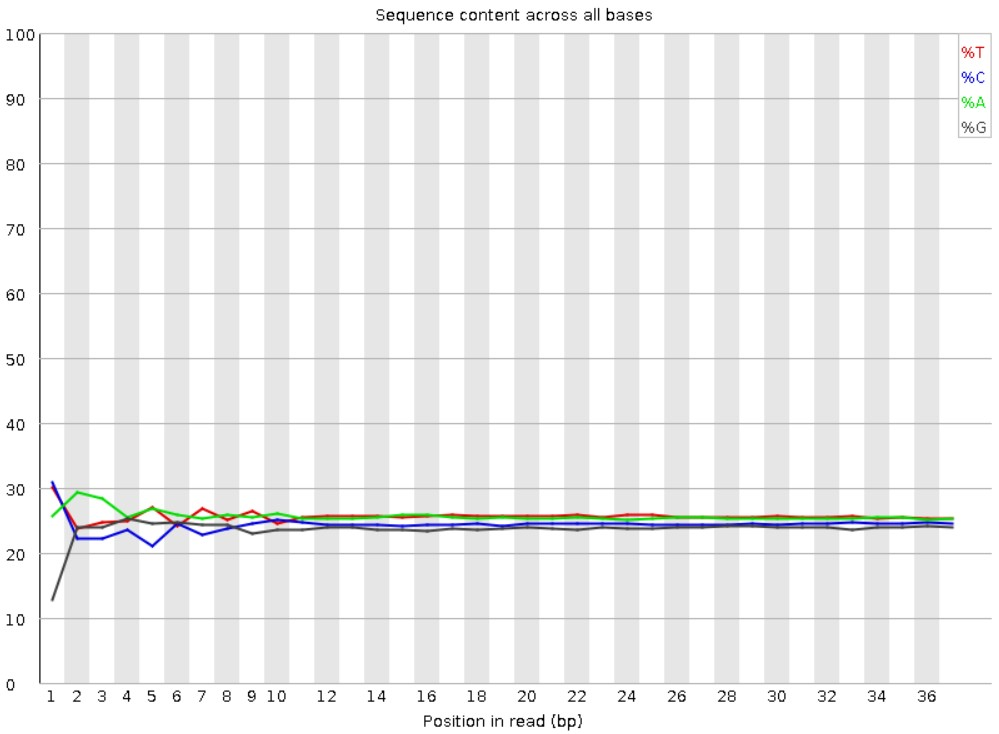

Explication :

Le Per base sequence content trace la proportion à chaque position de chacune des 4 bases.

Dans une librairie aléatoire, on s'attendrait à ce qu'il y ait peu ou pas de différence entre les différentes bases d'une séquence, donc les lignes de ce graphique devraient être parallèles les unes aux autres. En particulier, les lignes de A et T et de C et G doivent être presque parfaitement chevauchantes.

Si vous voyez des biais forts qui changent d'une base à l'autre, cela indique généralement une séquence surreprésentée qui contamine votre librairie. 

<div class="alert alert-block alert-warning">
Ce module émet un avertissement si la différence entre A et T, ou G et C est supérieure à 10 % à n'importe quelle position.
</div>

<div class="alert alert-block alert-danger">
Ce module échouera si la différence entre A et T, ou G et C est supérieure à 20 % à n'importe quelle position.
</div>

<img src="..." alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAFlUlEQVR42s2XCUzTVxzHybIs0IgC
LYqyQ9RtmhjCNKKbikajYVc22NThNjYjeC0yWBESxAV1Ckw8QEUF5ChnS4FyFETucwWU+7ClHKKi
ImLI4nCz9bv3/pS7ra1HtM1Lm/b/fp/ve+93PQMABq9y6D/Bz+ANNvethWxPw3Xs3wx/YAb9Tn6j
/700AeZc1qccrhGPw2UNkk8Fx9voIceX9Tcz6Hf62/B/PPrsCxNgzjW043iyGjheRkOWQRzFt2IH
/Nl4DDFyHjJ6siDoSoZ/YwB2VuyEffpGzA5iK+izdA6d+8wCyHa+SYyEsj2N/jU/aaL0vbIf0sF2
tA92oOVBG+ruN6CqrwZldypR0FuMnBuXkX49C5GyaGwq3ASLU2ZKOpfaoLb0EmDibmLC8TQq5/iw
/vlIaA1xjxiyQTmaH7Sitr8ekr5qlN6pQP6tImTfyIXoeiYEnSmIlSfiooyHc20R8G84htUZq0Ft
UFvUpk4ChldO4H6sRzvKXdEw0ISmgRZc7a/DXwRccrscebcKIb5xCWndGeB3CsGTJyBCGoPQtnCc
ajlLjugk/qgPxO+1h7Eqyw7UFrWpbiemCKBbRlW7lrmgcaAZV/prUXm3CsW3y3D5VgGyenKQ2p2O
pM5k8NoTEC6Nxtm2MJxsPoPAxhM4XB+AA1cPwbvmADyqvPFLpQdsM1aodoIVqlUAdRp6bgv5HzBb
XHFXgqLbpci9mY/MnmykdIuQ2CFATHs8wqRRONN6ASeaTyOg8TgO1fnDl4C9anzhLvHCnkp3uJTv
gXOJC7YUOWN+0nww/jTJMSevvsHs+DRlSOsZFPaW4NLNPOLpYgi70pBAwFHtcbhwLRKnW8/jeHMI
OecgHKw7iv1XD2Jf9X78KtmHyNZoiOQi/FiyHZsJ+Ov87/DZZUesEq8H+4SxkjLUCmDinISPY74j
cm4Oe3RyVyriO/iIksUS8EWEtJ5DUFMwjhIH86s7Ap8rfvCs9oGbxBO7KtwQ3hKBrgdd6H94D3yp
gIAdsD7nc6wWb8DyzDWYy58HyhifJ8ZWT5NMoLGCJ48jsZ2COHkSCSkezl+LQHBLKI40BGJLsRPW
5qzDskxbLE5bDBuRDWwzV5DV2SGwNhCdAx0Yed172AdeWyyWpa/ColQbzE1+H7MTLcEOmKagrAkC
aAqlWWwZf6kqlMY8+gDZ3jXZazEz0Rym8TPUDg+yetl9Kca/HikeIUUmgEXizAnPml2YDsoaSduM
AJrHaSrdWvw9AYcR8LBHu0m4eJtvqRGsDS4k8DlJFlPnxM0AZVHmmABSTGg+31GxW+XRAfi51AWz
tKxaI/zxELNytXDVoCzKHBNAKhotKrsr9zIe7Vq+G5wEs9EJi1I+hFDKx7zkuTrAk7XCGQGERZlT
BLiSuN1Ltn2BcMEEeGF3PoaI8dzObFgJ3nsuuHoBqiNwLNgMu+x1ow9SByrsyoNC+ZiBPFb8h5Lr
hWrhqTKhTnD1R6BywuWZn0zYejq2FTuj/k7tKEz5RPlccLVOOBKG7DATtZO+yXNATW81npD3ZHha
ux5wTWE4kohoktA0cWPOelT3SkZFDMNT9ICbwCJplvpEND4Vm8ZqNrJBJWJIT7h5Ioek5a+wRLRU
cyoeX4y0GaMiaEjqCn9X8A62le0ADXGLYLbmYjS+HJtGTdf5TLUNa5E1Kc8+8K09iPkJVk8vx+Mb
Em1H8bTBTjDFF3lfMlmVNipLREt0a0gmt2TPIsKKZEv3Ki5TU2gZt8+1168lm9yU6noc1MO3FDkx
YNojhpH+YW2Gnf5Nqbq2nHHMWPVbbZNuA6firQghpZt2TRHSSGwn/eScYPNnb8s1XUxoDFtGWpD6
sAgrxSvhSi4juypJ31f6ExwLSNsl/BicAOMXczF5ba5mr83l9GWN/wE1f784zfWjGwAAAABJRU5E
rkJg" alt="Drawing" style="width: 50px;"/> pour du RNA-seq (sequence bias on random primed libraries)

<img src="..." alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAFlUlEQVR42s2XCUzTVxzHybIs0IgC
LYqyQ9RtmhjCNKKbikajYVc22NThNjYjeC0yWBESxAV1Ckw8QEUF5ChnS4FyFETucwWU+7ClHKKi
ImLI4nCz9bv3/pS7ra1HtM1Lm/b/fp/ve+93PQMABq9y6D/Bz+ANNvethWxPw3Xs3wx/YAb9Tn6j
/700AeZc1qccrhGPw2UNkk8Fx9voIceX9Tcz6Hf62/B/PPrsCxNgzjW043iyGjheRkOWQRzFt2IH
/Nl4DDFyHjJ6siDoSoZ/YwB2VuyEffpGzA5iK+izdA6d+8wCyHa+SYyEsj2N/jU/aaL0vbIf0sF2
tA92oOVBG+ruN6CqrwZldypR0FuMnBuXkX49C5GyaGwq3ASLU2ZKOpfaoLb0EmDibmLC8TQq5/iw
/vlIaA1xjxiyQTmaH7Sitr8ekr5qlN6pQP6tImTfyIXoeiYEnSmIlSfiooyHc20R8G84htUZq0Ft
UFvUpk4ChldO4H6sRzvKXdEw0ISmgRZc7a/DXwRccrscebcKIb5xCWndGeB3CsGTJyBCGoPQtnCc
ajlLjugk/qgPxO+1h7Eqyw7UFrWpbiemCKBbRlW7lrmgcaAZV/prUXm3CsW3y3D5VgGyenKQ2p2O
pM5k8NoTEC6Nxtm2MJxsPoPAxhM4XB+AA1cPwbvmADyqvPFLpQdsM1aodoIVqlUAdRp6bgv5HzBb
XHFXgqLbpci9mY/MnmykdIuQ2CFATHs8wqRRONN6ASeaTyOg8TgO1fnDl4C9anzhLvHCnkp3uJTv
gXOJC7YUOWN+0nww/jTJMSevvsHs+DRlSOsZFPaW4NLNPOLpYgi70pBAwFHtcbhwLRKnW8/jeHMI
OecgHKw7iv1XD2Jf9X78KtmHyNZoiOQi/FiyHZsJ+Ov87/DZZUesEq8H+4SxkjLUCmDinISPY74j
cm4Oe3RyVyriO/iIksUS8EWEtJ5DUFMwjhIH86s7Ap8rfvCs9oGbxBO7KtwQ3hKBrgdd6H94D3yp
gIAdsD7nc6wWb8DyzDWYy58HyhifJ8ZWT5NMoLGCJ48jsZ2COHkSCSkezl+LQHBLKI40BGJLsRPW
5qzDskxbLE5bDBuRDWwzV5DV2SGwNhCdAx0Yed172AdeWyyWpa/ColQbzE1+H7MTLcEOmKagrAkC
aAqlWWwZf6kqlMY8+gDZ3jXZazEz0Rym8TPUDg+yetl9Kca/HikeIUUmgEXizAnPml2YDsoaSduM
AJrHaSrdWvw9AYcR8LBHu0m4eJtvqRGsDS4k8DlJFlPnxM0AZVHmmABSTGg+31GxW+XRAfi51AWz
tKxaI/zxELNytXDVoCzKHBNAKhotKrsr9zIe7Vq+G5wEs9EJi1I+hFDKx7zkuTrAk7XCGQGERZlT
BLiSuN1Ltn2BcMEEeGF3PoaI8dzObFgJ3nsuuHoBqiNwLNgMu+x1ow9SByrsyoNC+ZiBPFb8h5Lr
hWrhqTKhTnD1R6BywuWZn0zYejq2FTuj/k7tKEz5RPlccLVOOBKG7DATtZO+yXNATW81npD3ZHha
ux5wTWE4kohoktA0cWPOelT3SkZFDMNT9ICbwCJplvpEND4Vm8ZqNrJBJWJIT7h5Ioek5a+wRLRU
cyoeX4y0GaMiaEjqCn9X8A62le0ADXGLYLbmYjS+HJtGTdf5TLUNa5E1Kc8+8K09iPkJVk8vx+Mb
Em1H8bTBTjDFF3lfMlmVNipLREt0a0gmt2TPIsKKZEv3Ki5TU2gZt8+1168lm9yU6noc1MO3FDkx
YNojhpH+YW2Gnf5Nqbq2nHHMWPVbbZNuA6firQghpZt2TRHSSGwn/eScYPNnb8s1XUxoDFtGWpD6
sAgrxSvhSi4juypJ31f6ExwLSNsl/BicAOMXczF5ba5mr83l9GWN/wE1f784zfWjGwAAAABJRU5E
rkJg" alt="Drawing" style="width: 50px;"/> pour du séquençage Bisulfite (C non méthylés deviennent des T)

## _Per Sequence GC Content_

<img src="...
RU5ErkJg" alt="Drawing" style="width: 800px;"/>

Explication :

Ce module mesure le pourcentage de GC moyen de chaque lecture du fichier et le compare à une distribution normale modélisée de ce %GC. 

Dans une librairie aléatoire, on s'attendrait à voir une distribution normale, où le pic central correspond au pourcentage de GC du génome attendu. Comme le génome de référence n'est pas connu par fastQC, le pourcentage en GC est calculé à partir des données observées et utilisé pour construire une distribution de référence. 

Si la courbe rouge (distribution réelle) présente une forme inhabituelle, cela pourrait indiquer une librairie contaminée par exemple. Une distribution normale qui serait légèrement décalée indique un certain biais systématique. Si c'est le cas, cela ne sera pas signalé comme une erreur par fastQC puisqu'il ne sait pas quelle devrait être la valeur du %GC de votre génome.

<div class="alert alert-block alert-warning">
Un avertissement est émis si la somme des écarts par rapport à la distribution normale représente plus de 15 % des lectures.
</div>

<div class="alert alert-block alert-danger">
Ce module indiquera un échec si la somme des écarts par rapport à la distribution normale représente plus de 30 % des lectures.
</div>

<img src="...
PVEAAAAASUVORK5C" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAFlUlEQVR42s2XCUzTVxzHybIs0IgC
LYqyQ9RtmhjCNKKbikajYVc22NThNjYjeC0yWBESxAV1Ckw8QEUF5ChnS4FyFETucwWU+7ClHKKi
ImLI4nCz9bv3/pS7ra1HtM1Lm/b/fp/ve+93PQMABq9y6D/Bz+ANNvethWxPw3Xs3wx/YAb9Tn6j
/700AeZc1qccrhGPw2UNkk8Fx9voIceX9Tcz6Hf62/B/PPrsCxNgzjW043iyGjheRkOWQRzFt2IH
/Nl4DDFyHjJ6siDoSoZ/YwB2VuyEffpGzA5iK+izdA6d+8wCyHa+SYyEsj2N/jU/aaL0vbIf0sF2
tA92oOVBG+ruN6CqrwZldypR0FuMnBuXkX49C5GyaGwq3ASLU2ZKOpfaoLb0EmDibmLC8TQq5/iw
/vlIaA1xjxiyQTmaH7Sitr8ekr5qlN6pQP6tImTfyIXoeiYEnSmIlSfiooyHc20R8G84htUZq0Ft
UFvUpk4ChldO4H6sRzvKXdEw0ISmgRZc7a/DXwRccrscebcKIb5xCWndGeB3CsGTJyBCGoPQtnCc
ajlLjugk/qgPxO+1h7Eqyw7UFrWpbiemCKBbRlW7lrmgcaAZV/prUXm3CsW3y3D5VgGyenKQ2p2O
pM5k8NoTEC6Nxtm2MJxsPoPAxhM4XB+AA1cPwbvmADyqvPFLpQdsM1aodoIVqlUAdRp6bgv5HzBb
XHFXgqLbpci9mY/MnmykdIuQ2CFATHs8wqRRONN6ASeaTyOg8TgO1fnDl4C9anzhLvHCnkp3uJTv
gXOJC7YUOWN+0nww/jTJMSevvsHs+DRlSOsZFPaW4NLNPOLpYgi70pBAwFHtcbhwLRKnW8/jeHMI
OecgHKw7iv1XD2Jf9X78KtmHyNZoiOQi/FiyHZsJ+Ov87/DZZUesEq8H+4SxkjLUCmDinISPY74j
cm4Oe3RyVyriO/iIksUS8EWEtJ5DUFMwjhIH86s7Ap8rfvCs9oGbxBO7KtwQ3hKBrgdd6H94D3yp
gIAdsD7nc6wWb8DyzDWYy58HyhifJ8ZWT5NMoLGCJ48jsZ2COHkSCSkezl+LQHBLKI40BGJLsRPW
5qzDskxbLE5bDBuRDWwzV5DV2SGwNhCdAx0Yed172AdeWyyWpa/ColQbzE1+H7MTLcEOmKagrAkC
aAqlWWwZf6kqlMY8+gDZ3jXZazEz0Rym8TPUDg+yetl9Kca/HikeIUUmgEXizAnPml2YDsoaSduM
AJrHaSrdWvw9AYcR8LBHu0m4eJtvqRGsDS4k8DlJFlPnxM0AZVHmmABSTGg+31GxW+XRAfi51AWz
tKxaI/zxELNytXDVoCzKHBNAKhotKrsr9zIe7Vq+G5wEs9EJi1I+hFDKx7zkuTrAk7XCGQGERZlT
BLiSuN1Ltn2BcMEEeGF3PoaI8dzObFgJ3nsuuHoBqiNwLNgMu+x1ow9SByrsyoNC+ZiBPFb8h5Lr
hWrhqTKhTnD1R6BywuWZn0zYejq2FTuj/k7tKEz5RPlccLVOOBKG7DATtZO+yXNATW81npD3ZHha
ux5wTWE4kohoktA0cWPOelT3SkZFDMNT9ICbwCJplvpEND4Vm8ZqNrJBJWJIT7h5Ioek5a+wRLRU
cyoeX4y0GaMiaEjqCn9X8A62le0ADXGLYLbmYjS+HJtGTdf5TLUNa5E1Kc8+8K09iPkJVk8vx+Mb
Em1H8bTBTjDFF3lfMlmVNipLREt0a0gmt2TPIsKKZEv3Ki5TU2gZt8+1168lm9yU6noc1MO3FDkx
YNojhpH+YW2Gnf5Nqbq2nHHMWPVbbZNuA6firQghpZt2TRHSSGwn/eScYPNnb8s1XUxoDFtGWpD6
sAgrxSvhSi4juypJ31f6ExwLSNsl/BicAOMXczF5ba5mr83l9GWN/wE1f784zfWjGwAAAABJRU5E
rkJg" alt="Drawing" style="width: 50px;"/>

<img src="...
NQaB9gAAAABJRU5ErkJg" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAEkklEQVR42s2XV2hUaxSF/4nRiaIo
iKA+CDYMdsQnS8CAFREVsV4VUR9sWMECVuzYsETsGnvvivVaImhyU+Hq9VUfzKtKkptk5nz3rPkz
42RyJskE5Xpgw8yZ8++1Zu+1yzGA+T8t8UPGJP1lTGquMenZxvwh02fd02+/jECOMSNdoEwX6Ktr
gQJjSv425rtMn3VPv+kZPfvTCLj/MM11WphnTNnnlJRA6fDhsGkTHDsG16/D2bOwfj3OtGmUDhjA
Z78/oGd1RmcbTOBPY5JdRxmuo/IvyclBZ/lyeP8ePn6EoiLIyYE3b+D5c3j4EG7fhitXICMDZ8QI
iv3+oM7Kh3wlRCDfmFbuwawiY0orOnWCmzfhwwcoLITsbMjKgmfP4MEDuHULLl+2kTh+PESAvXth
7Voq+/RBPuRLPutFoOqfZ/1jzL8KK3l5UFAA797B69fw9Cncv29JXboEmZk2HYcOwZ49sG0bbNwI
a9aAGzWnd2/kSz69IlGDgEIm1s6UKZCfD2/fwqtX8OQJ3LsHN27AxYtw5gwcPQoHDsDu3bB1K2zY
AKtXw7JlsHAhzJ0LM2fipKaGI5FRK4EqwZVXtGtnc/viBTx+DHfvWsFduACnT8ORI7B/P+zaBVu2
hETIqlUWeMECmDMHZsyASZNg3DgYNYrK1q2R71hhViMg5X4xJsjOnfDoEdy5A9euwfnzcOqUTUNu
rgXevBnWrYOVK2HJEli0yGpDaZk4EcaOhZFuNaanw6BB0KsXxT6fhFnoSUC1q/Jxhg61ir56Fc6d
g5Mn4fBhq/jKSggE7GcBL14M8+bZUEsfwSCUl8OJEzBkCAwcCP37h8Dp1g2nZUuEEd0nov995ief
LxASVKyiX76Eigoil4jouY4doUcPmyIRC18isW8fdO8OXbpA27bgguP388ltWMKqTsC2168lXbtW
V/T27bBihRWdQKMvERI5kY0G16XvSllSkoWIsm+uCSvctkME1MfVShkzxipapSRFz54NzZtbR1J7
LIlwSmLBVZrJyTXAZY4lEAjNjjABDRP1c6ZO/aHoCROgSZMfh+OR8AJv3NgTPGzCEmaEgCaahgrT
p8PSpaAe0KhRzcMicfCgNwmBKx11gMuEJcyaBAQ8axa0aeN9WGFVbmPDHk6HNOHzJU4gkgKVYN++
iYNHC1PirYNEjRREROi2TM/QxwPXd6/qkJDjkPAUYbgMv3kdUt7VjOKVmpcmRELd0sOfZxlGGpGi
4BU2db2ysprgioxXdZSW2qEU6yclJU4jimrFwXi5C5OIBvcqUYGrjGNTOHgwTufO8VtxtWFUGwml
w6vJiIQmZCx4ixa2p7glXrUlFdY5jstrKyOP9hqx2Jx36ADz54fGdEV9xnH0QhKso5api2Ramu2q
7qISdENfr4UkdiVrEIlWrex4Vim6Y9xxR3JCK1nsUlpeX2BX4dp8Qo1IE9XVQ2W/fokvpZ5ruSvM
YLxQaycYPRp27Ij0BWfyZIqbNm34Wh7vxUQ1/L1ZM5z27aFnT0LTUwNs/HicYcMoce9pqfkpLya/
zavZb/Ny+qvsPyB3ge/Rlc06AAAAAElFTkSuQmCC" alt="Drawing" style="width: 50px;"/> Contamination de dimer d'adaptateur

## _Per Base N Content_ 

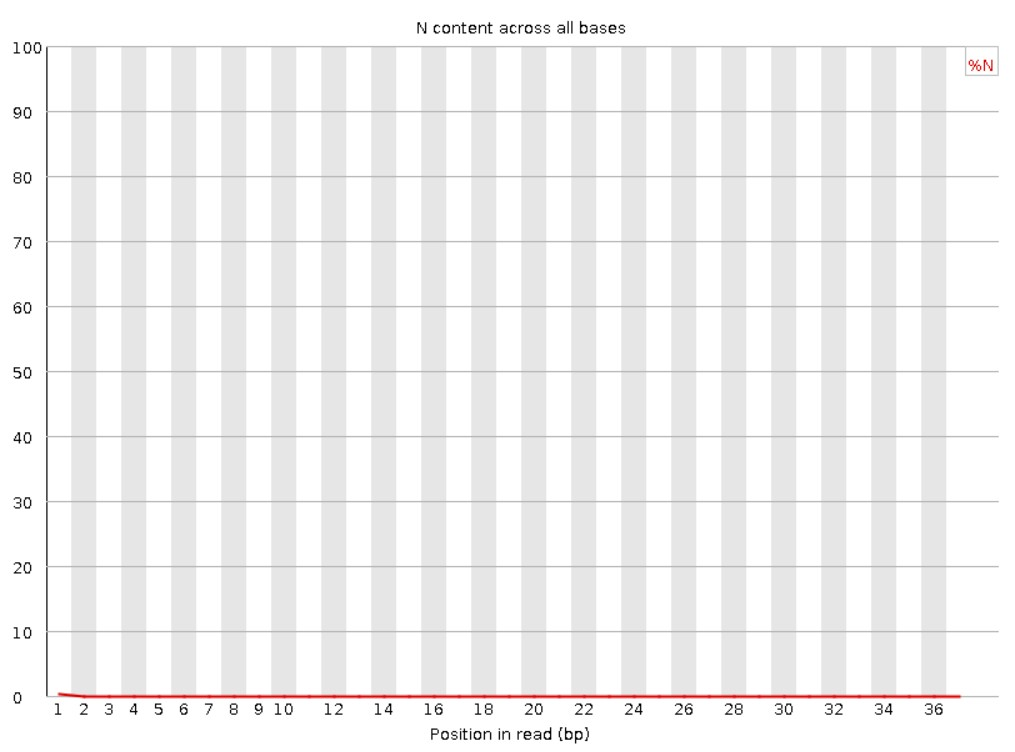

Explication :

Si un séquenceur n'est pas en mesure de lire une base avec suffisamment de confiance, il substituera la base par un N plutôt que d'ajouter une base fausse. Ici nous avons donc la représentation du pourcentage de base remplacée par des N pour chaque position.

Il n'est pas inhabituel de voir une très faible proportion de N apparaître dans une séquence, en particulier vers la fin d'une séquence (donc du séquençage). Cependant, si cette proportion dépasse quelques pourcents, cela suggère que le séquenceur n'a pas été en mesure d'interpréter un grand nombre de base.

<div class="alert alert-block alert-warning">
Ce module émet un avertissement si une position montre un contenu en N supérieur à 5 %.
</div>

<div class="alert alert-block alert-danger">
Ce module signalera une erreur si une position montre un contenu en N supérieur à 20 %.
</div>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAAyAAAAJYCAIAAAAVFBUnAAAjRUlEQVR42u3di3eUdWLH4flb1rVr
V7e17Flbu3rs7tnaVutl6xFFdBVFVw9SXAVZdBXbCqLIbSVcBINKFESjCEFYN4pcpIoUI0pACQsk
AeW0i67WGyLpiwPpONd33nnnnUnm+Z6cPWxM8iTzG+DjO8mY6jMzMzOzWJdyE5iZmZkJLDMzMzOB
ZWZmZiawzMzMzExgmZmZmQksMzMzM4FlZmZmZgLLzMzMTGCZmZmZCSwzMzMzE1hmZmZmAsvMzMxM
YJmZmZkJLDMzMzMTWGZmZmYCy8zMzExgmZmZmZnAMjMzMxNYZmZmZgLLzMzMzASWmWX9tk+lSr4m
3o9fjXdJ/uaq9u1mZgLLzAZ2YGWVgcASWGYmsMwshsDKjIO8oZD3zQq9JrNCivzfMO9S6M3CfPyy
uLzBVOTGCf/25b6y5FdtZgLLzAZAYGXlQpFrM3l/kbc5irxLWa8s6yMXerMw7xIZDfn20T7zIslr
ZgLLzOo9sIr8dV7o6k7kmIgQWHmLMORn1RfH43qRA6v4Byn3szUzgWVmAy+wcq9mhYmSMLWUylm5
GZT1vmUVTJEHBEM+RFjJFaySaJEbx0OEZgLLzAZ2YPXle7iw0P+t8ApWySiJ9kmWvIIV+TXxPkQY
5ksu/rmZmcAyswETWH2lHnrLewEpye/BKnQxKUxg5b5voWtpIdFyg6wIGuazNTOBZWaDKrD6Qv8U
Yck6Kfddct+xyOdQ/GcM+6I+RNgX+gpW8VupOOqnCM0ElpmZmZkJLDMzMzOBZWZmZiawzMzMzExg
mZmZmSUfWMV/rKb4K83MzMysdGCFfCoaMzMzM8sTWIWuVOWNrUJBZmZmZmZhr2AJLDMzMzOBZWZm
ZjYoAqvNzMzMrC73StxLLrAiX9A6EHWR05JIJBKJRGJDicWTKN6PFvNPEQosIpFIJBKJAivm58ES
WEQikUgkEgVWzN+iLrCIRCKRSCQKLIFFJBKJRCJRYAksdyAikUgkEomVBdaU71yafsl8TeYb5/7T
rDcQWEQikUgkEon/n0T9tZT5i6w3ziowgUUkEolEIpFYIrByS0tguQMRiUQikUiM7QpWbl1l/qOs
a10Ci0gkEolEIjF/EmXFU6HA6v+nAotIJBKJRCKxRGBlhlTxxwSzLmUJLCKRSCQSicRQgZXZVVmB
VeiRRIFFJBKJRCKRmCeJ8naVwHIHIhKJRCKRGENg9ZX6sUGBRSQSiUQikRj2IcLIE1hEIpFIJBKJ
AssdiEgkEolEosASWEQikUgkEgWWwCISiUQikSiwBJY7EJFIJBKJRIHlOIlEIpFIJAosgUUkEolE
IlFgCSx3ICKRSCQSiaGTKN4JLCKRSCQSicTkRIFFJBKJRCKRKLAcJ5FIJBKJRIHlOIlEIpFIJAos
gUUkEolEIpEosIhEIpFIJBIFluMkEolEIpEosAQWkUgkEolEosAiEolEIpFIFFiOk0gkEolEosAS
WEQikUgkEokCi0gkEolEIlFgOU4ikUgkEokCy41LJBKJRCJRYAksIpFIJBKJRIHlOIlEIpFIJAos
x0kkEolEIlFgCSwikUgkEolEgUUkEolEIpEosBwnkUgkEolEgSWwiEQikUgkEgUWkUgkEolEosBy
nEQikUgkEgdRYKVOrOQrBRaRSCQSiURi6cDqb6PMnMr7SoFFJBKJRCKRWDqwsvopN7BCxpPAIhKJ
RCKRSBRYRCKRSCQSiTV6iFBgEYlEIpFIJJYdWJlpFTmw2szMzMwaY2EDy0OERCKRSCQSick9ROin
CIlEIpFIJBKjP0ToebCIRCKRSCQSYwusyiewiEQikUgkEgUWkUgkEolEosBynEQikUgkEgWW4yQS
iUQikSiwBBaRSCQSiUSiwCISiUQikUgUWI6TSCQSiUSiwBJYRCKRSCQSiQKLSCQSiUQiUWA5TiKR
SCQSiQJLYBGJRCKRSCQKLCKRSCQSiUSB5TiJRCKRSCQKLDcukUgkEolEgSWwiEQikUgkEgWW4yQS
iUQikSiwHCeRSCQSiUSBJbCIRCKRSCQSBRaRSCQSiUSiwHKcRCKRSCQSBZbAIhKJRCKRSBRYRCKR
SCQSiQLLcRKJRCKRSBRYAotIJBKJRCJRYBGJRCKRSCQKLMdJJBKJRCJRYLlxiUQikUgkCiyBRSQS
iUQikSiwHCeRSCQSiUSB5TiJRCKRSCQKLIFFJBKJRCKRKLCIRCKRSCQSBZbjJBKJRCKRKLAEFpFI
JBKJRKLAIhKJRCKRSBRYjpNIJBKJRKLAElhEIpFIJBKJAotIJBKJRCJRYDlOIpFIJBKJAstxEolE
IpFIFFgCi0gkEolEIlFgOU4ikUgkEokCy3ESiUQikUhsoMBKnVjJVwosIpFIJBKJxNKB1d9GmTmV
95UCi0gkEolEIrG8wMrqqrLiSWARiUQikUgkhr2CJbCIRCKRSCQSyw6svnzfbiWwiEQikUgkEmv8
EGGbmZmZWWOsdGAVunDlChaRSCQSiURita5g+SlCIpFIJBKJxHi+B6vP82ARiUQikUgkVhJYlU9g
EYlEIpFIJAosIpFIJBKJRIHlOIlEIpFIJAosx0kkEolEIlFgCSwikUgkEolEgUUkEolEIpEosBwn
kUgkEolEgSWwiEQikUgkEgUWkUgkEolEosBynEQikUgkEgWWwCISiUQikUgUWEQikUgkEokCy3ES
iUQikUgUWG5cIpFIJBKJAktgEYlEIpFIJAosx0kkEolEIlFgOU4ikUgkEokCS2ARiUQikUgkCiwi
kUgkEolEgeU4iUQikUgkCiyBRSQSiUQikSiwiEQikUgkEgWW4yQSiUQikSiwBBaRSCQSiUSiwCIS
iUQikUgUWI6TSCQSiUSiwHLjEolEIpFIFFgCi0gkEolEIlFgOU4ikUgkEokCy3ESiUQikUgUWAKL
SCQSiUQiUWARiUQikUgkCizHSSQSiUQiUWAJLCKRSCQSiUSBRSQSiUQikSiwHCeRSCQSiUSBJbCI
RCKRSCQSBRaRSCQSiUSiwHKcRCKRSCQSBZbjJBKJRCKRKLAEFpFIJBKJRKLAcpxEIpFIJBIFluMk
EolEIpHYKIGV+vZyXy+wiEQikUgkEqNfwervpMxfhIkngUUkEolEIpGYKh5JhX4tsIhEIpFIJBIF
FpFIJBKJRGKNAiurkAQWkUgkEolEYo0Dq83MzMysMRY2sHITyhUsIpFIJBKJxIquYBUJLD9FSCQS
iUQikRhPYPV5HiwikUgkEonECr8Hq8IJLCKRSCQSiUSBRSQSiUQikSiwHCeRSCQSiUSB5TiJRCKR
SCQKLIFFJBKJRCKRKLCIRCKRSCQSBZbjJBKJRCKRKLAEFpFIJBKJRKLAIhKJRCKRSBRYjpNIJBKJ
RKLAElhEIpFIJBKJAotIJBKJRCJRYDlOIpFIJBKJAsuNSyQSiUQiUWAJLCKRSCQSiUSB5TiJRCKR
SCQKLMdJJBKJRCJRYAksIpFIJBKJRIFFJBKJRCKRKLAcJ5FIJBKJRIElsIhEIpFIJBIFFpFIJBKJ
RKLAcpxEIpFIJBIFlsAiEolEIpFIFFhEIpFIJBKJAstxEolEIpFIFFhuXCKRSCQSiQJLYBGJRCKR
SCQKLMdJJBKJRCJRYDlOIpFIJBKJAktgEYlEIpFIJAosIpFIJBKJRIHlOIlEIpFIJAosgUUkEolE
IpEosIhEIpFIJBIFluMkEolEIpEosAQWkUgkEolEosAiEolEIpFIFFiOk0gkEolEosBynEQikUgk
EgWWwCISiUQikUgUWI6TSCQSiUSiwHKcRCKRSCQSGyiwUidW8pUCi0gkEolEIrF0YGW2Uf+vM38R
Jp4EFpFIJBKJRGKqeBvlrS6BRSQSiUQikRg2sHIfDRRYRCKRSCQSidV6iFBgEYlEIpFIJNYmsNrM
zMzMGmOuYBGJRCKRSCTW3xUsP0VIJBKJRCKRWHZg9XkeLCKRSCQSicTYA6vyCSwikUgkEolEgUUk
EolEIpEosBwnkUgkEolEgeU4iUQikUgkCiyBRSQSiUQikSiwiEQikUgkEgWW4yQSiUQikSiwBBaR
SCQSiUSiwCISiUQikUgUWI6TSCQSiUSiwBJYRCKRSCQSiQKLSCQSiUQiUWA5TiKRSCQSiQLLjUsk
EolEIlFgCSwikUgkEolEgeU4iUQikUgkCizHSSQSiUQiUWAJLCKRSCQSiUSBRSQSiUQikSiwHCeR
SCQSiUSBJbCIRCKRSCQSBRaRSCQSiUSiwHKcRCKRSCQSBZbAIhKJRCKRSBRYRCKRSCQSiQLLcRKJ
RCKRSBRYblwikUgkEokCS2ARiUQikUgkCizHSSQSiUQiUWA5TiKRSCQSiQJLYBGJRCKRSCQKLCKR
SCQSiUSB5TiJRCKRSCQKLIFFJBKJRCKRKLCIRCKRSCQSBZbjJBKJRCKRKLAEFpFIJBKJRKLAIhKJ
RCKRSBRYjpNIJBKJRKLAcpxEIpFIJBIFlsAiEolEIpFIFFiOk0gkEolEosBynEQikUgkEhslsFLf
Xu7rBRaRSCQSiURi2YFVJJhCNpbAIhKJRCKRSAwbWCHjSWARiUQikUgk5n+IUGARiUQikUgkxnwF
K/ORQYFFJBKJRCKReKDynyKMHFhtZmZmZo2x5ALLFSwikUgkEonEsA8R+ilCIpFIJBKJxCiBlfcp
rzwPFpFIJBKJROIBz+ROJBKJRCKRKLAcJ5FIJBKJRIElsIhEIpFIJBIFFpFIJBKJRKLAcpxEIpFI
JBIFlsAiEolEIpFIFFhEIpFIJBKJAstxEolEIpFIFFiOk0gkEolEosASWEQikUgkEokCi0gkEolE
IlFgOU4ikUgkEokCS2ARiUQikUgkCiwikUgkEolEgeU4iUQikUgkCiyBRSQSiUQikSiwiEQikUgk
EgWW4yQSiUQikSiw3LhEIpFIJBIFlsAiEolEIpFIFFiOk0gkEolEosBynEQikUgkEgWWwCISiUQi
kUgUWEQikUgkEokCy3ESiUQikUgUWAKLSCQSiUQiUWARiUQikUgkCizHSSQSiUQiUWAJLCKRSCQS
iUSBRSQSiUQikSiwHCeRSCQSiUSB5cYlEolEIpEosAQWkUgkEolEosBynEQikUgkEgWW4yQSiUQi
kSiwBBaRSCQSiUSiwCISiUQikUgUWI6TSCQSiUSiwBJYRCKRSCQSiQKLSCQSiUQiUWA5TiKRSCQS
iQJLYBGJRCKRSCQKLCKRSCQSicTkAisrklInJrCIRCKRSCQSowRWVkv1/zpkYwksIpFIJBKJxLCB
FTKeBBaRSCQSiURiKjePBBaRSCQSiURiPIGV+WigwCISiUQikUisl8BqMzMzM2uMlQ6sVM5cwSIS
iUQikUiM4XuwikSVnyIkEolEIpFIjCew+jwPFpFIJBKJRGLlgVXJBBaRSCQSiUSiwCISiUQikUgU
WI6TSCQSiUSiwHKcRCKRSCQSBZbAIhKJRCKRSBRYRCKRSCQSiQLLcRKJRCKRSBRYAotIJBKJRCJR
YBGJRCKRSCQKLMdJJBKJRCJRYAksIpFIJBKJRIFFJBKJRCKRKLAcJ5FIJBKJRIHlxiUSiUQikSiw
BBaRSCQSiUSiwHKcRCKRSCQSBZbjJBKJRCKRKLAEFpFIJBKJRKLAIhKJRCKRSBRYjpNIJBKJRKLA
ElhEIpFIJBKJAotIJBKJRCJRYDlOIpFIJBKJAktgEYlEIpFIJAosIpFIJBKJRIHlOIlEIpFIJAos
Ny6RSCQSiUSBJbCIRCKRSCQSBZbjJBKJRCKRKLAcJ5FIJBKJRIElsIhEIpFIJBIFFpFIJBKJRKLA
cpxEIpFIJBIFlsAiEolEIpFIFFhEIpFIJBKJAstxEolEIpFIFFgCi0gkEolEIlFgEYlEIpFIJAos
x0kkEolEIlFgOU4ikUgkEokCS2ARiUQikUgkCizHSSQSiUQiUWA5TiKRSCQSiY0SWKmMZTVT7isF
FpFIJBKJRGKowMosqiKvFFhEIpFIJBKJ5QVWVleVFU8Ci0gkEolEIjGVN5IEFpFIJBKJRGJsgZX1
UKDAIhKJRCKRSIzhClYlDxG2mZmZmTXGSgdW7k8OuoJFJBKJRCKRWOkVrOLf5O6nCIlEIpFIJBKj
BJbnwSISiUQikUis1vdgRZ7AIhKJRCKRSBRYRCKRSCQSiQLLcRKJRCKRSBRYjpNIJBKJRKLAElhE
IpFIJBKJAotIJBKJRCJRYDlOIpFIJBKJAktgEYlEIpFIJAosIpFIJBKJRIHlOIlEIpFIJAosgUUk
EolEIpEosIhEIpFIJBIFluMkEolEIpEosNy4RCKRSCQSBZbAIhKJRCKRSBRYjpNIJBKJRKLAcpxE
IpFIJBIFlsAiEolEIpFIFFhEIpFIJBKJAstxEolEIpFIFFgCi0gkEolEIlFgEYlEIpFIJAosx0kk
EolEIlFgCSwikUgkEolEgUUkEolEIpEosBwnkUgkEolEgeXGJRKJRCKRKLAEFpFIJBKJRKLAcpxE
IpFIJBIFluMkEolEIpEosAQWkUgkEolEosAiEolEIpFIFFiOk0gkEolEosASWEQikUgkEokCi0gk
EolEIlFgOU4ikUgkEokCS2ARiUQikUgkCiwikUgkEolEgeU4iUQikUgkCizHSSQSiUQiUWAJLCKR
SCQSiUSB5TiJRCKRSCQKLMdJJBKJRCKxgQIrdWIlXymwiEQikUgkEksHVmYb9f868xdh4klgEYlE
IpFIJIYNrJDxJLCIRCKRSCQSU8U7SWARiUQikUgkxhBYhaJKYBGJRCKRSCSWHVh5v8O9rHhqMzMz
M2uMhf0erNyEcgWLSCQSiUQiMfoVrLxt5KcIiUQikUgkEiMGVipnWVe2PA8WkUgkEolEYpTvwap8
AotIJBKJRCJRYBGJRCKRSCQKLMdJJBKJRCJRYDlOIpFIJBKJAktgEYlEIpFIJAosIpFIJBKJRIHl
OIlEIpFIJAosgUUkEolEIpEosIhEIpFIJBIFluMkEolEIpEosAQWkUgkEolEosAiEolEIpFIFFiO
k0gkEolEosBy4xKJRCKRSBRYAotIJBKJRCJRYDlOIpFIJBKJAstxEolEIpFIFFgCi0gkEolEIlFg
EYlEIpFIJAosx0kkEolEIlFgCSwikUgkEolEgUUkEolEIpEosBwnkUgkEolEgSWwiEQikUgkEgUW
kUgkEolEosBynEQikUgkEgWWG5dIJBKJRKLAElhEIpFIJBKJAstxEolEIpFIFFiOk0gkEolEosAS
WEQikUgkEokCi0gkEolEIlFgOU4ikUgkEokCS2ARiUQikUgkCiwikUgkEolEgeU4iUQikUgkCiyB
RSQSiUQikSiwiEQikUgkEgWW4yQSiUQikSiwHCeRSCQSiUSBJbCIRCKRSCQSBZbjJBKJRCKRKLAc
J5FIJBKJxMYKrNxCSp2YwCISiUQikUiMIbD6/2/IxhJYRCKRSCQSianiV6oy/6/AIhKJRCKRSIzz
CpbAIhKJRCKRSBRYRCKRSCQSiYMisNrMzMzMGmOuYBGJRCKRSCTW3xUsP0VIJBKJRCKRGE9g9Xke
LCKRSCQSicQKA6vCCSwikUgkEolEgUUkEolEIpEosBwnkUgkEolEgeU4iUQikUgkCiyBRSQSiUQi
kSiwiEQikUgkEgWW4yQSiUQikSiwBBaRSCQSiUSiwCISiUQikUgUWI6TSCQSiUSiwBJYRCKRSCQS
iQKLSCQSiUQiUWA5TiKRSCQSiQLLjUskEolEIlFgCSwikUgkEolEgeU4iUQikUgkCizHSSQSiUQi
UWAJLCKRSCQSiUSBRSQSiUQikSiwHCeRSCQSiUSBJbCIRCKRSCQSBRaRSCQSiUSiwHKcRCKR2Fji
kS8Pf3bo4w+7PzjYubdnc2fX2q2dKzd2LGl/5YGWRReM3758vVuVKLAEFpFIJDao2Luve8+OXe9u
2bZ9/ZaO1Rs2t7ZvWty2bl7rc7fOXHTJHUuvm9Q6ZvrS6ycvvmJi88Xj5/39mNln3Tjj9Gse+LPL
p3zn0iIv95906fOjZxzcvsc5EgWWG5dIJBIHm7h9+fpFF4xfdXvT6gnzlo+evmzE5Jahdz1y3ti5
54yaNeTaqd8bVryTirwE7zvrh9cGH6f5/LHBx3z62slBUQXKqvFzArG/wAKxZ3OncyQKLMdJJBKJ
g0E8uH1PUFRTThpavJOCEprxV9fMPuvG+eeOab54fMvwiUtHTj521Wrk5EWX3PHcbbPWzWvd1LJq
c2t7x5qN29dveW/L23t27Ort7in+hXz8wR9fmvTYtNOuTCtBgXWt3eociQLLcRKJROJAFXs2dy4b
Mfn4daaTL1904fh1U5/sWNLe2fZqUDk9b+w42Ln3o+6Dnx36+Mjhr6r6NX7+4ScbZi6bOWRE+pNp
Pn9s58qN+3t6nSNRYDlOIpFIHDBi0E8tl/4mXTPTT7vqpUmPffLBoZp/jV9++vnmhStnn3lD+hNr
OvumdfNae7t7nCNRYDlOIpFIrF9xf09v58qNzeePTRfMzCEjNs5a9vmHn9TV13jk8FcdS9rn/2R0
+pOcdcZ17dOf2Ld7j3MkCizHSSQSifUl9nb3rJvX2nT2TelqmX3mDZsXrjz86Rd1+zUePfL1ppZV
888dc/wy2+lXr763ee/OLvccosBynEQikVh7cd/uPb+f1jLrjOvSpTL/J6M7lrYfOfzVQPkaN7e2
N188Pv3JP3jq8BV3zOnatsM9hyiwHCeRSCTWRtyzc9fqe5unn3718bQ6d8ymllVHvz46EL/GjjUb
F18x8cTPM142+6wbt7Vvcs8hCizHSSQSicmJXdt2rJjQ9OCpw4//UN7F4ze3tg+Cr3H7ujeWjpw8
5aRvrmadduX2DVvcc4gCy3ESiURi1cWO321sOvum/mfvbBk+sWPNxkH2NW5r/89ZP7w2+OqmnXZV
fzi65xAFluMkEonEqoibFrdNPeWbp1w/aejSkZO3r98yWG/V3n3dT/1yyrH/0s53h74080n3HKLA
cpxEIpEYv7h3Z9fS648/ZehDZ17f8btXG+FWXTN5UfoJ6J/91czenh73HKLAcpxEIpEYm7j5md//
9oyR6YfM1s1vbahbddPiVVP//Irga3/00jv3vbfbPYcosBwnkUgkViru6/pD65jp6QtXi/7l1+9t
ebsBb9Vj35L1o2NPQjHn70a9+8Y29xyiwHKcRCKRGF18c9X62T/+5bH/jOApw9qnP7G/d3/D3qq7
OjrTT0k6/fSrt65a555DFFiOk0gkEsveV18cXjGhKf3tRwv+6dYdm950q3bv3tvyi3/75lmyLn/r
qZfcc4gCy3ESiURiGXt/W9eCc285VhInX7763kcyv7m7wW/V/b37V/5mbvoB05fvezzCU6q6rxIF
FpFIJDac+PWRIxtmLgu6KgiIeT8d/fba192quVv/8LPppwF75ob7v/z0c/ccosBynEQikVhw/72r
59ELxx9/5qdJj/Xs7XarFtq+196ZOWTEsaewP3/snw78j/sqsbqBlToxgUUkEokDSDz69dHXF6x4
8JsnI5h7zqju1zvdqiXFQ3vff/hnx77t/aG/vv5Axy731XoTd2/b+eLUx5svuj343+DXAziw+tuo
ksYSWEQikZiw+FH3wScuvzv9fUWr75jX/5iXW7Wk+MWf/nfJlf9+7L9a+P3hO9o2ua/WVty76w//
tfKVFx94/Mlr/iP9tG2ZL8FrgtcH/zR4m+AtB2RgVdJJAotIJBKTFDuWtE8/7argr5/Zf3ND19qt
btVyxa+PHFlz58Pp/3bQqw89476apHjk8FcH3uraunjN06Omzv3pzekfeu1/mfYXv1hw3q3NF92+
8Pzbgl9/q7dOGhq8ffBewfu+v60r+DgCy12WSCQ2qNi7r3vPjl3vbtm2ff2WjtUbNre2b1rctm5e
67O3zVx0yR1Pj3pw9b3NeV82zFyW9+WlSY/N/8m/pv++eX70jM8//MQ5RhbfaG67/7vH/nZfccus
I18e9rujWuLRo3/cvf+dZ9e9eM8jj/18wtRTrsjMpge+N+yRC8YtH/fQxkUrdr7+1oH9GU/btn//
ztc6gtcH/zR4m+AtM98x+DjBRws+ZvCRg48fKA0UWPtee6fQnxHpl0J/sjx989Rof/S0jZv9xLB7
Vo1rIhKJxATEVWObAnH5zdNWT5i3fPT0ZSMmtwy965Hzxs49Z9SsIddO/fbfBzG+PPj94Z1tr0qB
ysWutVun/+DYZZKmv73x5fsW+90Ro/jC+Dktl9316IXjZ/zl1Zn33iBqF5x7S9vY2WtnP/X2y6/1
dod9PpHgLYO3D94reN/gI6TjuP8lUB696PaWy+5+Yfzccr/G9Mubq9bXXWC1FVjzqElV+sPFixcv
XgbEy/0nXzb1B1dO+9GImWff8NufjWr651vmXjLu4SvvDP73oX8YPX/YhOZR95b1snDkxJk/vv7J
SXPaLKY9s6DlgVOHu69W9WXakGvm/HzsolumPDVj4fPPPBfLwQUfZ+n0BcHHDD5y8PEr/ySD318h
6eQCq9C6X9u+cdayCC8vjGt68oqJQWh7R+/oHb1jvb/jsHtevHthx5L2zrZXu9Zu7Xljx8HOvR91
H/zs0McRvkfEarL3Xty88B9/tfa+x93J43zHX8954rK7NjW1fnLwUAKHGCiBFYiBG609gmip/NOI
+acIzczMzCzm58EyMzMzMy1lZmZmJrDMzMzMBNZxKdIjj9EetUxlLJnPNvXtJfw1JiNGeMfct6z2
w9D1IFZyh3erFvrgjSBW9Z4z6G/VQn8eNoJYvXtOI9yqhW7AGP7jgfUcWJF/sLHCb9iPliyV3yzJ
5GDkGyfCO+beXys5l0rEqv69FctdaAB9jVU9x7xfTg3FatyqRT549f7SqoevMZlzzPzgNRSreqsW
6o/q3XNq+zUm83dHoTtt9L+ak0mryKFTYUNEDruaBFYyHyHajVPozlfuv7xW9bdlPYjV/sOu+NeY
vDhYc6fRAmvQJ517jntO5L/j6jqwYrlRKnmEMQKU2IOSNXk0M8KNU25g1dX1pITFaHehSq4nJfwQ
YWJP6ZLkH69FPnjCf51U++e4s44vgZ8cT/I6RJLXWkr+RZOYmMA9J+tWTeYBu8TuObk3YAMFVsJ1
ldhlob44LrbFe+kl3jKrn8CqSXwkLCYckUl+P0Rif03WvK5qItbk3weSLI8kr3zUqq5qIiZ5q1b1
u76q9LtjYHyTe2JuLPfUOg+sSsT+4xhAgZX890UO+sCqtpjwg5KF7iRJdkAC95x6uFWTvxJZk2uf
yTydZN6rOwmLg+McGzSwKv/Orb7yv80o4cfsKsydGP9FpBp0PaRAYn/oxHgXqudbNa67ULmtk7yY
cF1V9Z5TD7dqVe85YWo1MTHJ3/hVvefUya1a7XtO3huwIQIrlr8PEvhsa/IQYeVfWkP9FGHCd2xX
sGK8PRP7KcLkr3YkQ5f8GpO/VRvh50+r/a86Cd9zBuuPDpSkB2FgVRLmtX0erMgFnWSANsLzYNXk
elLygdU3iJ4Hq8iRJSlW+6pA8Q8+WG/Vat9X6+EZm5K5Eul5sBL7d9cB8zxYZmZmZg0ygWVmZmYm
sMzMzMwElpmZmZnAMjMzMzOBZWZmZiawzMzMzASWmZmZmQksMzMzM4FlZmZmJrDMzMzMTGCZWaE/
Dir7z6jl/S/sVvLJJPZVh/la6uSzNTOBZWYDL7BiiYaBVRuxBJbGMjOBZWZlB1buZa3ca13pX2S+
styPUChxir9Z1ucQRil+ra6sdxdYZiawzCxKYGXlS5F/GuYXeS8OFamckG9W6NfFXxkmsMJ/ShrL
zASWmeUJrLyXdkpGRvjAilBOFQZW7huXfCRUYJmZwDKzOAOr5CuLPHJX6BclL4zFElhF6jDrlQLL
zASWmdU4sCKUUD1cwSryBgLLzASWmdVjYEX+Zqy+xB8iLPkNZALLzASWmdUgsPrK+SnCzGop+VOE
8QZW8c+zr/DjicUDK/zPPwosMxNYZmZRWrMv3DermZnAMjMzgWVmAsvMzMxMYJmZmZkJLDMzMzOL
uP8DhhFxBdS/6pAAAAAASUVORK5C" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAEkklEQVR42s2XV2hUaxSF/4nRiaIo
iKA+CDYMdsQnS8CAFREVsV4VUR9sWMECVuzYsETsGnvvivVaImhyU+Hq9VUfzKtKkptk5nz3rPkz
42RyJskE5Xpgw8yZ8++1Zu+1yzGA+T8t8UPGJP1lTGquMenZxvwh02fd02+/jECOMSNdoEwX6Ktr
gQJjSv425rtMn3VPv+kZPfvTCLj/MM11WphnTNnnlJRA6fDhsGkTHDsG16/D2bOwfj3OtGmUDhjA
Z78/oGd1RmcbTOBPY5JdRxmuo/IvyclBZ/lyeP8ePn6EoiLIyYE3b+D5c3j4EG7fhitXICMDZ8QI
iv3+oM7Kh3wlRCDfmFbuwawiY0orOnWCmzfhwwcoLITsbMjKgmfP4MEDuHULLl+2kTh+PESAvXth
7Voq+/RBPuRLPutFoOqfZ/1jzL8KK3l5UFAA797B69fw9Cncv29JXboEmZk2HYcOwZ49sG0bbNwI
a9aAGzWnd2/kSz69IlGDgEIm1s6UKZCfD2/fwqtX8OQJ3LsHN27AxYtw5gwcPQoHDsDu3bB1K2zY
AKtXw7JlsHAhzJ0LM2fipKaGI5FRK4EqwZVXtGtnc/viBTx+DHfvWsFduACnT8ORI7B/P+zaBVu2
hETIqlUWeMECmDMHZsyASZNg3DgYNYrK1q2R71hhViMg5X4xJsjOnfDoEdy5A9euwfnzcOqUTUNu
rgXevBnWrYOVK2HJEli0yGpDaZk4EcaOhZFuNaanw6BB0KsXxT6fhFnoSUC1q/Jxhg61ir56Fc6d
g5Mn4fBhq/jKSggE7GcBL14M8+bZUEsfwSCUl8OJEzBkCAwcCP37h8Dp1g2nZUuEEd0nov995ief
LxASVKyiX76Eigoil4jouY4doUcPmyIRC18isW8fdO8OXbpA27bgguP388ltWMKqTsC2168lXbtW
V/T27bBihRWdQKMvERI5kY0G16XvSllSkoWIsm+uCSvctkME1MfVShkzxipapSRFz54NzZtbR1J7
LIlwSmLBVZrJyTXAZY4lEAjNjjABDRP1c6ZO/aHoCROgSZMfh+OR8AJv3NgTPGzCEmaEgCaahgrT
p8PSpaAe0KhRzcMicfCgNwmBKx11gMuEJcyaBAQ8axa0aeN9WGFVbmPDHk6HNOHzJU4gkgKVYN++
iYNHC1PirYNEjRREROi2TM/QxwPXd6/qkJDjkPAUYbgMv3kdUt7VjOKVmpcmRELd0sOfZxlGGpGi
4BU2db2ysprgioxXdZSW2qEU6yclJU4jimrFwXi5C5OIBvcqUYGrjGNTOHgwTufO8VtxtWFUGwml
w6vJiIQmZCx4ixa2p7glXrUlFdY5jstrKyOP9hqx2Jx36ADz54fGdEV9xnH0QhKso5api2Ramu2q
7qISdENfr4UkdiVrEIlWrex4Vim6Y9xxR3JCK1nsUlpeX2BX4dp8Qo1IE9XVQ2W/fokvpZ5ruSvM
YLxQaycYPRp27Ij0BWfyZIqbNm34Wh7vxUQ1/L1ZM5z27aFnT0LTUwNs/HicYcMoce9pqfkpLya/
zavZb/Ny+qvsPyB3ge/Rlc06AAAAAElFTkSuQmCC" alt="Drawing" style="width: 50px;"/>

## _Sequence Length Distribution_

<img src="..." alt="Drawing" style="width: 800px;"/>

Explication :

Certains séquenceurs à haut débit génèrent des reads de longueur uniforme, mais d'autres peuvent contenir des lectures de longueurs très variées. Même dans les librairie de longueur uniforme, certains pipelines vont tronquer les séquences pour enlever les bases de mauvaise qualité à partir de leur extrémité. Ce module génère un graphique montrant la distribution des tailles de reads dans le fichier analysé. 

Dans de nombreux cas, cela produira un graphique simple montrant un pic à une seule taille, mais pour les fichiers FastQ de longueur variable, cela montrera les quantités relatives de chaque taille différente de reads.

<div class="alert alert-block alert-warning">
Ce module émet un avertissement si toutes les lectures ne sont pas de la même taille.
</div>

<div class="alert alert-block alert-danger">
Ce module signalera une erreur si au moins une séquence est de taille 0.
</div>

<img src="...
KIoaqf4/IT91stBythAAAAAASUVORK5C" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAFlUlEQVR42s2XCUzTVxzHybIs0IgC
LYqyQ9RtmhjCNKKbikajYVc22NThNjYjeC0yWBESxAV1Ckw8QEUF5ChnS4FyFETucwWU+7ClHKKi
ImLI4nCz9bv3/pS7ra1HtM1Lm/b/fp/ve+93PQMABq9y6D/Bz+ANNvethWxPw3Xs3wx/YAb9Tn6j
/700AeZc1qccrhGPw2UNkk8Fx9voIceX9Tcz6Hf62/B/PPrsCxNgzjW043iyGjheRkOWQRzFt2IH
/Nl4DDFyHjJ6siDoSoZ/YwB2VuyEffpGzA5iK+izdA6d+8wCyHa+SYyEsj2N/jU/aaL0vbIf0sF2
tA92oOVBG+ruN6CqrwZldypR0FuMnBuXkX49C5GyaGwq3ASLU2ZKOpfaoLb0EmDibmLC8TQq5/iw
/vlIaA1xjxiyQTmaH7Sitr8ekr5qlN6pQP6tImTfyIXoeiYEnSmIlSfiooyHc20R8G84htUZq0Ft
UFvUpk4ChldO4H6sRzvKXdEw0ISmgRZc7a/DXwRccrscebcKIb5xCWndGeB3CsGTJyBCGoPQtnCc
ajlLjugk/qgPxO+1h7Eqyw7UFrWpbiemCKBbRlW7lrmgcaAZV/prUXm3CsW3y3D5VgGyenKQ2p2O
pM5k8NoTEC6Nxtm2MJxsPoPAxhM4XB+AA1cPwbvmADyqvPFLpQdsM1aodoIVqlUAdRp6bgv5HzBb
XHFXgqLbpci9mY/MnmykdIuQ2CFATHs8wqRRONN6ASeaTyOg8TgO1fnDl4C9anzhLvHCnkp3uJTv
gXOJC7YUOWN+0nww/jTJMSevvsHs+DRlSOsZFPaW4NLNPOLpYgi70pBAwFHtcbhwLRKnW8/jeHMI
OecgHKw7iv1XD2Jf9X78KtmHyNZoiOQi/FiyHZsJ+Ov87/DZZUesEq8H+4SxkjLUCmDinISPY74j
cm4Oe3RyVyriO/iIksUS8EWEtJ5DUFMwjhIH86s7Ap8rfvCs9oGbxBO7KtwQ3hKBrgdd6H94D3yp
gIAdsD7nc6wWb8DyzDWYy58HyhifJ8ZWT5NMoLGCJ48jsZ2COHkSCSkezl+LQHBLKI40BGJLsRPW
5qzDskxbLE5bDBuRDWwzV5DV2SGwNhCdAx0Yed172AdeWyyWpa/ColQbzE1+H7MTLcEOmKagrAkC
aAqlWWwZf6kqlMY8+gDZ3jXZazEz0Rym8TPUDg+yetl9Kca/HikeIUUmgEXizAnPml2YDsoaSduM
AJrHaSrdWvw9AYcR8LBHu0m4eJtvqRGsDS4k8DlJFlPnxM0AZVHmmABSTGg+31GxW+XRAfi51AWz
tKxaI/zxELNytXDVoCzKHBNAKhotKrsr9zIe7Vq+G5wEs9EJi1I+hFDKx7zkuTrAk7XCGQGERZlT
BLiSuN1Ltn2BcMEEeGF3PoaI8dzObFgJ3nsuuHoBqiNwLNgMu+x1ow9SByrsyoNC+ZiBPFb8h5Lr
hWrhqTKhTnD1R6BywuWZn0zYejq2FTuj/k7tKEz5RPlccLVOOBKG7DATtZO+yXNATW81npD3ZHha
ux5wTWE4kohoktA0cWPOelT3SkZFDMNT9ICbwCJplvpEND4Vm8ZqNrJBJWJIT7h5Ioek5a+wRLRU
cyoeX4y0GaMiaEjqCn9X8A62le0ADXGLYLbmYjS+HJtGTdf5TLUNa5E1Kc8+8K09iPkJVk8vx+Mb
Em1H8bTBTjDFF3lfMlmVNipLREt0a0gmt2TPIsKKZEv3Ki5TU2gZt8+1168lm9yU6noc1MO3FDkx
YNojhpH+YW2Gnf5Nqbq2nHHMWPVbbZNuA6firQghpZt2TRHSSGwn/eScYPNnb8s1XUxoDFtGWpD6
sAgrxSvhSi4juypJ31f6ExwLSNsl/BicAOMXczF5ba5mr83l9GWN/wE1f784zfWjGwAAAABJRU5E
rkJg" alt="Drawing" style="width: 50px;"/> pour du séquençage Roche 454

## _Duplicate Sequences_

<img src="...
AAAAAElFTkSuQmCC" alt="Drawing" style="width: 800px;"/>

Explication :

Dans une librairie aléatoire, la plupart des séquences n'apparaîtront qu'une seule fois. Un faible niveau de duplication peut indiquer un niveau de couverture très élevé de la séquence cible, mais un niveau élevé de duplication est plus susceptible d'indiquer un biais d'enrichissement (par exemple, une sur-amplification par PCR).

Ce module compte le degré de duplication pour chaque séquence du fichier et crée un graphique montrant le pourcentage de lectures à chaque niveau de duplication.

<div class="alert alert-block alert-warning">
Ce module émet un avertissement si le taux de séquence non-unique est supérieur à 20%.
</div>

<div class="alert alert-block alert-danger">
Ce module signalera une erreur si le taux de séquence non-unique est supérieur à 50%.
</div>

<img src="...
IopdAAAAAElFTkSuQmCC" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAFlUlEQVR42s2XCUzTVxzHybIs0IgC
LYqyQ9RtmhjCNKKbikajYVc22NThNjYjeC0yWBESxAV1Ckw8QEUF5ChnS4FyFETucwWU+7ClHKKi
ImLI4nCz9bv3/pS7ra1HtM1Lm/b/fp/ve+93PQMABq9y6D/Bz+ANNvethWxPw3Xs3wx/YAb9Tn6j
/700AeZc1qccrhGPw2UNkk8Fx9voIceX9Tcz6Hf62/B/PPrsCxNgzjW043iyGjheRkOWQRzFt2IH
/Nl4DDFyHjJ6siDoSoZ/YwB2VuyEffpGzA5iK+izdA6d+8wCyHa+SYyEsj2N/jU/aaL0vbIf0sF2
tA92oOVBG+ruN6CqrwZldypR0FuMnBuXkX49C5GyaGwq3ASLU2ZKOpfaoLb0EmDibmLC8TQq5/iw
/vlIaA1xjxiyQTmaH7Sitr8ekr5qlN6pQP6tImTfyIXoeiYEnSmIlSfiooyHc20R8G84htUZq0Ft
UFvUpk4ChldO4H6sRzvKXdEw0ISmgRZc7a/DXwRccrscebcKIb5xCWndGeB3CsGTJyBCGoPQtnCc
ajlLjugk/qgPxO+1h7Eqyw7UFrWpbiemCKBbRlW7lrmgcaAZV/prUXm3CsW3y3D5VgGyenKQ2p2O
pM5k8NoTEC6Nxtm2MJxsPoPAxhM4XB+AA1cPwbvmADyqvPFLpQdsM1aodoIVqlUAdRp6bgv5HzBb
XHFXgqLbpci9mY/MnmykdIuQ2CFATHs8wqRRONN6ASeaTyOg8TgO1fnDl4C9anzhLvHCnkp3uJTv
gXOJC7YUOWN+0nww/jTJMSevvsHs+DRlSOsZFPaW4NLNPOLpYgi70pBAwFHtcbhwLRKnW8/jeHMI
OecgHKw7iv1XD2Jf9X78KtmHyNZoiOQi/FiyHZsJ+Ov87/DZZUesEq8H+4SxkjLUCmDinISPY74j
cm4Oe3RyVyriO/iIksUS8EWEtJ5DUFMwjhIH86s7Ap8rfvCs9oGbxBO7KtwQ3hKBrgdd6H94D3yp
gIAdsD7nc6wWb8DyzDWYy58HyhifJ8ZWT5NMoLGCJ48jsZ2COHkSCSkezl+LQHBLKI40BGJLsRPW
5qzDskxbLE5bDBuRDWwzV5DV2SGwNhCdAx0Yed172AdeWyyWpa/ColQbzE1+H7MTLcEOmKagrAkC
aAqlWWwZf6kqlMY8+gDZ3jXZazEz0Rym8TPUDg+yetl9Kca/HikeIUUmgEXizAnPml2YDsoaSduM
AJrHaSrdWvw9AYcR8LBHu0m4eJtvqRGsDS4k8DlJFlPnxM0AZVHmmABSTGg+31GxW+XRAfi51AWz
tKxaI/zxELNytXDVoCzKHBNAKhotKrsr9zIe7Vq+G5wEs9EJi1I+hFDKx7zkuTrAk7XCGQGERZlT
BLiSuN1Ltn2BcMEEeGF3PoaI8dzObFgJ3nsuuHoBqiNwLNgMu+x1ow9SByrsyoNC+ZiBPFb8h5Lr
hWrhqTKhTnD1R6BywuWZn0zYejq2FTuj/k7tKEz5RPlccLVOOBKG7DATtZO+yXNATW81npD3ZHha
ux5wTWE4kohoktA0cWPOelT3SkZFDMNT9ICbwCJplvpEND4Vm8ZqNrJBJWJIT7h5Ioek5a+wRLRU
cyoeX4y0GaMiaEjqCn9X8A62le0ADXGLYLbmYjS+HJtGTdf5TLUNa5E1Kc8+8K09iPkJVk8vx+Mb
Em1H8bTBTjDFF3lfMlmVNipLREt0a0gmt2TPIsKKZEv3Ki5TU2gZt8+1168lm9yU6noc1MO3FDkx
YNojhpH+YW2Gnf5Nqbq2nHHMWPVbbZNuA6firQghpZt2TRHSSGwn/eScYPNnb8s1XUxoDFtGWpD6
sAgrxSvhSi4juypJ31f6ExwLSNsl/BicAOMXczF5ba5mr83l9GWN/wE1f784zfWjGwAAAABJRU5E
rkJg" alt="Drawing" style="width: 50px;"/> pour du RNA-seq ou autre séquençage ciblé

<img src="...
QmCC" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAFlUlEQVR42s2XCUzTVxzHybIs0IgC
LYqyQ9RtmhjCNKKbikajYVc22NThNjYjeC0yWBESxAV1Ckw8QEUF5ChnS4FyFETucwWU+7ClHKKi
ImLI4nCz9bv3/pS7ra1HtM1Lm/b/fp/ve+93PQMABq9y6D/Bz+ANNvethWxPw3Xs3wx/YAb9Tn6j
/700AeZc1qccrhGPw2UNkk8Fx9voIceX9Tcz6Hf62/B/PPrsCxNgzjW043iyGjheRkOWQRzFt2IH
/Nl4DDFyHjJ6siDoSoZ/YwB2VuyEffpGzA5iK+izdA6d+8wCyHa+SYyEsj2N/jU/aaL0vbIf0sF2
tA92oOVBG+ruN6CqrwZldypR0FuMnBuXkX49C5GyaGwq3ASLU2ZKOpfaoLb0EmDibmLC8TQq5/iw
/vlIaA1xjxiyQTmaH7Sitr8ekr5qlN6pQP6tImTfyIXoeiYEnSmIlSfiooyHc20R8G84htUZq0Ft
UFvUpk4ChldO4H6sRzvKXdEw0ISmgRZc7a/DXwRccrscebcKIb5xCWndGeB3CsGTJyBCGoPQtnCc
ajlLjugk/qgPxO+1h7Eqyw7UFrWpbiemCKBbRlW7lrmgcaAZV/prUXm3CsW3y3D5VgGyenKQ2p2O
pM5k8NoTEC6Nxtm2MJxsPoPAxhM4XB+AA1cPwbvmADyqvPFLpQdsM1aodoIVqlUAdRp6bgv5HzBb
XHFXgqLbpci9mY/MnmykdIuQ2CFATHs8wqRRONN6ASeaTyOg8TgO1fnDl4C9anzhLvHCnkp3uJTv
gXOJC7YUOWN+0nww/jTJMSevvsHs+DRlSOsZFPaW4NLNPOLpYgi70pBAwFHtcbhwLRKnW8/jeHMI
OecgHKw7iv1XD2Jf9X78KtmHyNZoiOQi/FiyHZsJ+Ov87/DZZUesEq8H+4SxkjLUCmDinISPY74j
cm4Oe3RyVyriO/iIksUS8EWEtJ5DUFMwjhIH86s7Ap8rfvCs9oGbxBO7KtwQ3hKBrgdd6H94D3yp
gIAdsD7nc6wWb8DyzDWYy58HyhifJ8ZWT5NMoLGCJ48jsZ2COHkSCSkezl+LQHBLKI40BGJLsRPW
5qzDskxbLE5bDBuRDWwzV5DV2SGwNhCdAx0Yed172AdeWyyWpa/ColQbzE1+H7MTLcEOmKagrAkC
aAqlWWwZf6kqlMY8+gDZ3jXZazEz0Rym8TPUDg+yetl9Kca/HikeIUUmgEXizAnPml2YDsoaSduM
AJrHaSrdWvw9AYcR8LBHu0m4eJtvqRGsDS4k8DlJFlPnxM0AZVHmmABSTGg+31GxW+XRAfi51AWz
tKxaI/zxELNytXDVoCzKHBNAKhotKrsr9zIe7Vq+G5wEs9EJi1I+hFDKx7zkuTrAk7XCGQGERZlT
BLiSuN1Ltn2BcMEEeGF3PoaI8dzObFgJ3nsuuHoBqiNwLNgMu+x1ow9SByrsyoNC+ZiBPFb8h5Lr
hWrhqTKhTnD1R6BywuWZn0zYejq2FTuj/k7tKEz5RPlccLVOOBKG7DATtZO+yXNATW81npD3ZHha
ux5wTWE4kohoktA0cWPOelT3SkZFDMNT9ICbwCJplvpEND4Vm8ZqNrJBJWJIT7h5Ioek5a+wRLRU
cyoeX4y0GaMiaEjqCn9X8A62le0ADXGLYLbmYjS+HJtGTdf5TLUNa5E1Kc8+8K09iPkJVk8vx+Mb
Em1H8bTBTjDFF3lfMlmVNipLREt0a0gmt2TPIsKKZEv3Ki5TU2gZt8+1168lm9yU6noc1MO3FDkx
YNojhpH+YW2Gnf5Nqbq2nHHMWPVbbZNuA6firQghpZt2TRHSSGwn/eScYPNnb8s1XUxoDFtGWpD6
sAgrxSvhSi4juypJ31f6ExwLSNsl/BicAOMXczF5ba5mr83l9GWN/wE1f784zfWjGwAAAABJRU5E
rkJg" alt="Drawing" style="width: 50px;"/>

## _Overrepresented Sequences_

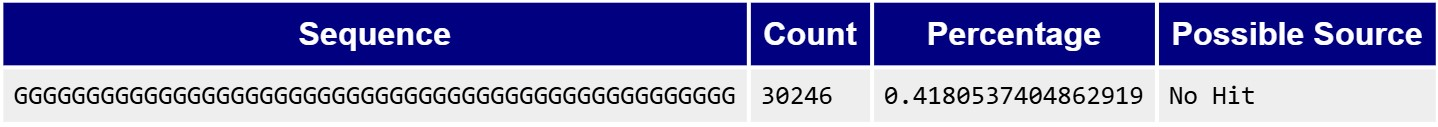

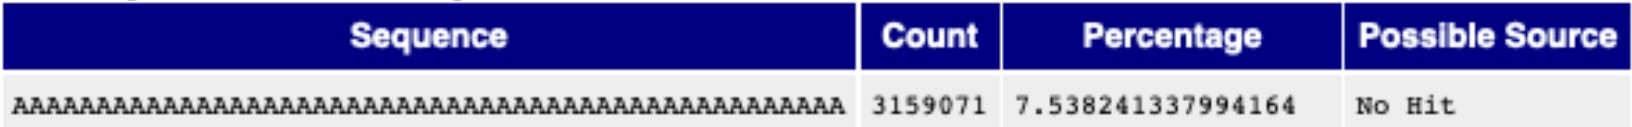

Explication :

Une librairie normale contient un ensemble diversifié de séquences, sans qu'aucune séquence individuelle ne soit sur-représentée face aux autres. 

Trouver une séquence sur-représentée signifie soit qu'elle est très significative sur le plan biologique, soit que la librairie est contaminée, ou n'est pas aussi diversifiée que vous l'aviez prévu. 

Attention, ce module répertorie toutes les séquences qui représentent plus de 0,1 % du total mais pour économiser de la mémoire, seules les séquences qui apparaissent dans les 200 000 premiers reads sont suivies jusqu'à la fin du fichier. Il est donc possible qu'une séquence soit sur-représentée mais qu'elle n'apparaîsse pas au début du fichier pour une raison quelconque et puisse donc être manquée par ce module.

<div class="alert alert-block alert-warning">
Ce module émet un avertissement si n'importe quelle séquence est présente à plus de 0,1%.
</div>

<div class="alert alert-block alert-danger">
Ce module signalera une erreur si n'importe quelle séquence est présente à plus de 1%.
</div>

## _Adapter Content_

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAAyAAAAJYCAIAAAAVFBUnAAAjyUlEQVR42u3dwXEjxxmGYaTgFJSC
UlAKvtpn+WbroBQk25JVUpVlpaAzA3AATsFXpzHe8hbh2Znuv3um/wEGwPPVlmtFkdiHZBP7agDS
l8nMzMzMUnfxITAzMzMTWGZmZmYCy8zMzExgmZmZmZnAMjMzMxNYZmZmZgLLzMzMzASWmZmZmcAy
MzMzE1hmZmZmJrDMzMzMBJaZmZmZwDIzMzMTWGZmZmYmsMzMzMwElpmZmZnAMjMzMzOBZWZmZiaw
zMzMzASWmZmZmQksMzvb/c775i9pvn7wb3cAfBbMTGCZ2VPVVe03AsvMBJaZ2S0C6zJb8YXz24lf
c/GS4j8WX2JmJrDM7AEa61owPZev1h22yKP4FTrbrv+KmpmZwDKzs8fW1sBavEnxFgSWmQksM3v1
uqo9KndZLQis2uOGtYQq3rjAMjOBZWbPEFhB2RRbKgisrS+Mr36ZmQksM3vIutoRWFPrOVj9T8zy
EKGZCSwze87AmioPEQYvib+LcKo8bli85a0/lMvMTGCZmYxzL2dmAsvMTGCZmcAyMzMzM4FlZmZm
JrDMzMzMHjqwgh/013yhmZmZmbUDq/+HzZiZmZnZMrBqV6qKsVULMjMzMzPrvYIlsMzMzMwElpmZ
mdlTBNabmZnZQ+2fZnt3u8DKvaD1n9TllikbGxsb23PY4r8mzWrLCazO7yIUWGxsbGxsAssEVvLP
wRJYbGxsbGwCywRW8lPUBRYbGxsbm8AygSWw2NjY2NgElpnAcgfExsbGxnZMYH3z2W8//Pr4m+tL
RsAjb37FFP8x98/Ker8+IgNJ871IeROB5YucjY2NjU1gCSyBJbDY2NjY2F4ysBatM//NtSrWeVF7
zUWOFAMiCKzarRXfKqif9TtbfJ3g/SqG1/rfzj+w6w/a+s2DV2u+FwLLFzkbGxsb28MHVq0J4tcM
XtgZWPGf1f8mna9T+7Piiur5KPUDOt8LgeWLnI2NjY3tGa5gxUFQu5LUfBSseQUrMPdEzNZHIfcF
VvOP6G+pzvdCYPkiZ2NjY2N76cCqPbCYGFjrh/mCTqq9TvMNey7y9bzvwWv2vxcCyxc5GxsbG9vr
BlbzGszuwJoqT66Kk2jTtaiadh1AzWd07buC1fNeCCxf5GxsbGxsDxBYPU+xSg+s5nPMa4EVXzqK
H7jcHVg9t9YTWFtfQWD5ImdjY2Nje+DAauZX4kOEU/3bDDsDq3lTna/T+dhi7SXBla3gGyFrH/n+
b2kUWL7I2djY2NhOEVh2353z510JLHdAbGxsbGwCS2AJLF/kbGxsbGwCyx5zAssdEBsbGxubwDKB
5Q6IjY2NjU1gmcASWGxsbGxsAssElsBiY2NjY2MTWCaw3AGxsbGxsQksE1i+yNnY2NjYBJYJLIHF
xsbGxiawzASWOyA2NjY2NoFlAssXORsbGxvbaQPr88+++fDr42+uLxkBj7/59dfghy54j+Z/yuLP
iv9x/rb9/uYrxx+NHR9AgeUOiI2NjY1NYBUw46HQDKxi5RT/cWtgrf8IgSWw2NjY2NgE1jILFi+M
rwAVX7PnAtU6Zfr/0KYkqJCtgVVrptobBoEV89bFuX4H5y9fv1rwVgLLHRAbGxsb24kCq/b3evya
wQubV196/tBYsiOwis7Yv+lKUucfUSytno9w/AoCyx0QGxsbG9vprmD1XK3peSZT8KhZHG09iTb4
HKyRwOopmGYeNT9ucUs1X1NguQNiY2NjY3uSwKplTfPhtp68CLKs+VhecImu9nT18StYwQXCno9b
XH61iBx5hpbAcgfExsbGxna6wOp58njtGs+mx7/GHyIM2itoxP4LRbWbaj63bN8VrFrYCSx3QGxs
bGxsdwisnqdYZQVW523ePbDia1T7HkNsXkLb/RHo/5ZGgeUOiI2NjY3tdoHVzK/chwib3w+Y/hDh
1PcsqM6nkfU8ANpz6at4Zav4DgbfNrjph3IJLHdAbGxsbGxpgWWPu+N+3pXAcgfExsbGxiawBJbA
8kXOxsbGxiaw7DEnsNwBsbGxsbEJLBNY7oDY2NjY2ASWCSyBxcbGxsYmsExgCSw2NjY2NjaBZQLL
HRAbGxsbm8AygeWLnI2NjY1NYJnAElhsbGxsbALLTGC5A2JjY2NjE1gmsHyRs7GxsbGdNrB+8/Xn
H359/M31JSPg8Te//hr80AXv0fxPWfxZ8T/O37bpb35Im+/pjo9DyocuIbAu72u+UGCxsbGxsQms
QwNrjhkPhWZgFSun+I8Ca1tgXdtonlPFFwosNjY2NrZXC6zFhZz5b+IrQMXX7LlAtU6Z/j+0KQkq
ZGtgxc3UH521m1qEZvwOzl9ebLvaWx0VWIt+WgdWZzwJLDY2Nja2lwqs2t/r8WsGL2xefen5Q2PJ
jsAqOmP/poc4O/+IYmn1fITjVxBY7oDY2NjY2E53BSv+S7345sUH2rY+xBZfW9oaWPFzsHYHVudD
dc08an7c4pZqvubdHiIUWGxsbGxsAis3sGpZE/RH5x8aZ1l840Gp1B527HmUrfkONrMs/rjF5VeL
yJFnaG1+kvvIFaw3MzOzh9q9AqvnyeO1azybHv8af4gwaK+gEfsvFNVuqvncsn1XsPqzLy2wPETI
xsbGxuYKVpxQWy8m7Qusztu8e2DFj3I2+6YfULv+NP4crMMDy3cRsrGxsbEJrDiwmvmV+xBh8/sB
0x8i7HwWVOfTyHoeAO259FW8slV8B4NvG2w+ynn4Q4R+DhYbGxsb22sGlj3ujvt5V5kPEe6ewGJj
Y2NjE1gmsAQWGxsbG5vAMhNY7oDY2NjY2ASWCSxf5GxsbGxsAssElsBiY2NjYxNYZgLLHRAbGxsb
m8AygeWLnI2NjY1NYJnAElhsbGxsbALLTGC5A2JjY2NjE1gmsNwBsbGxsbEJLBNYAouNjY2N7XkC
69//+vrDr9o/dm7fWwU3tfj1xMnyWO+mwHIHxMbGxsa2IbCuf7vfPbAetDxG3sf1Z0FgCSw2NjY2
tmcOrPVf/OvXXJdQ7a3WrxAkxY5bKMZK/2vGL9n3wjie1q8Zv9XiY75+k+YnruddDswCyx0QGxsb
G9u2wFr8zV386zz4q73nreLXaQbWJtuZX9i88tdzU0FgHWcWWO6A2NjY2Ni2PQdrfWlk02Wt+K2a
JdEZWPGrNUnNIux88/h2Ov/tOnD7WycIrOBT0LwC1zQLLHdAbGxsbGybA2v913zwWFhwxaX4oGFc
FZ0PEca3EBRS8zXjZAwedgxeuOnZ+vFbbQ2sHe9y8b0QWO6A2NjY2NiGAmv92FOcPpuu9zQfT9wU
WP0XaXquJ+2LyMC/4+pXZ/dsvYIVfwqaV7DWE1jugNjY2NjYhgJryn4O1l0Cq/mQZfzCwecw7Xuk
ctr4HKx+VZCAnoPlDoiNjY2N7ajAal7aaV4Eiq+O3P0hwtqjac2Lc8ELe66E9VwO7P+GxKn1hPfm
p6D5LZ++i9AdEBsbGxvbUGC95h79Z2vd64dmCSx3QGxsbGxsAktgCSx3QGxsbGxsAsvOPYHlDoiN
jY2NTWCZwHIHxMbGxsYmsExgCSw2NjY2NoFlAktgsbGxsbGxCSwTWO6A2NjY2NgElgksX+RsbGxs
bALLBJbAYmNjY2MTWGYCyx0QGxsbG5vAMoHli5yNjY2N7bSB9cWvvyx+BZj43y5uUI4ILIHFxsbG
xvbSgdUZRgJLYAksd0BsbGxsbBsCa/2P61Sap1ituq6vI0cElsBiY2NjYxNYn9TS4srW+t/GfeYi
lsASWGxsbGxsnoO1fA5WLZvikBJYAktgsbGxsbEJrKn49PYgm2ovKWaZIhFYAouNjY2NzUOEvYE1
lZ5rtb4YprEElsBiY2NjYxNYUzGqgscNe657mcASWGxsbGxsAitKqP6cElgCS2CxsbGxsb1oYI1M
PwksgcXGxsbGxpYZWC5QCSyBxcbGxsbGlhlY6kpgCSw2NjY2NrZDHiI0gVUNrMv7mi8UWGxsbGxs
AssEVjuwrm00z6niCwUWGxsbG5vAMoG1LbAWXbUpngQWGxsbG5vAMoHVewVLYLGxsbGxCSyzzYE1
lZ5uJbDY2NjY2ASWWcIVrGngIcI3MzOzh5rAsgMDq3bhyhUsNjY2NjZXsMyOuoLluwjZ2NjY2J4+
sH794pfFrwAT/9v1DSqSFw2syc/BYmNjY2MTWP8rofHAWreaxnrdwBqfwGJjY2Nje4LAWv/jOpLm
KbaurnVRCSyBJbDY2NjY2ARWoZYWyRVElZwSWAKLjY2NjU1gfXKZanG9qnhZqzO/Js/EElgCi42N
jY1NYAUPFDYDa331q3Y7JrAEFhsbGxvbKz5E2BlY0+z5WMFNCSyBJbDY2NjY2ATWVIyq+EHA4sUw
DxEKLIHFxsbGxiawplpj1R4EjMus+P2GJrAEFhsbGxvbSwTWyMSTwBJYbGxsbGxsmYHl6pTAElhs
bGxsbGyZgaWuBJbAYmNjY2NjO+QhQhNYAouNjY2NjU1gmcByB8TGxsbGJrBMYPkiZ2NjY2MTWCaw
BBYbGxsbm8AyE1jugNjY2NjYMgLLbN8EljsgNjY2NjY2tttNYLGxsbGxsbGxCSwHgo2NjY2NjU1g
ORBsbGxsbGxsAktgsbGxsbGxsQksgeVAsLGxsbGxsQksB4KNjY2NjY1NYAksNjY2NjY2NoElsBxW
NjY2NjY2NoHlQLCxsbGxsbEJLIHFxsbGxsbGJrAEFhsbGxsbGxubwHIg2NjY2NjY2ASWA8HGxsbG
xsYmsAQWGxsbGxsbG5vAciDY2NjY2NjYBJYDwcbGxsbGxiawBBYbGxsbGxubwBJYDgQbGxsbGxub
wHIg2NjY2NjY2ASWwGJjY2NjY2MTWALLYWVjY2NjY2MTWA4EGxsbGxsbm8ASWGxsbGxsbGwCS2Cx
sbGxsbGxsQksB4KNjY2NjY1NYDkQbGxsbGxsbALr8unWLxdYbGxsbGxsbAJr/xWsayfNf9MTTwKL
jY2NjY2NTWBd4kiq/V5gsbGxsbGxsQksgeWwsrGxsbGxsd0psBaFJLDY2NjY2NjYBNadA+vNzMzM
7DXWG1jrhHIFi42NjY2Njc0VrKErWEFg+S5CNjY2NjY2NoGVE1iTn4PFxsbGxsbGJrAGn4M1enMC
i42NjY2NjU1gCSw2NjY2NjY2NoHlQLCxsbGxsbEJLAeCjY2NjY2NTWAJLDY2NjY2NjaBJbAcCDY2
NjY2NjaB5UCwsbGxsbGxCSyBxcbGxsbGxiawBJbDysbGxsbGxiawHAg2NjY2NjY2gSWw2NjY2NjY
2ASWwGJjY2NjY2NjE1gOBBsbGxsbG5vAciDY2NjY2NjYBJbAYmNjY2NjY2MTWA4EGxsbGxsbm8By
INjY2NjY2NgElsBiY2NjY2NjE1gCy4FgY2NjY2NjE1gOBBsbGxsbG5vAElhsbGxsbGxsAktgOaxs
bGxsbGxsAsuBYGNjY2NjYxNYAouNjY2NjY1NYAksNjY2NjY2NjaB5UCwsbGxsbGxCSwHgo2NjY2N
jU1gCSw2NjY2NjY2NoHlQLCxsbGxsbEJLAeCjY2NjY2NTWAJLDY2NjY2NjaBJbAcCDY2NjY2NjaB
5UCwsbGxsbGxCSyBxcbGxsbGxiawBJbDysbGxsbGxiawHAg2NjY2NjY2gSWw2NjY2NjY2ASWwGJj
Y2NjY2NjE1gOBBsbGxsbG5vAciDY2NjY2NjYBJbAYmNjY2NjY2MTWA4EGxsbGxsbm8ByINjY2NjY
2NheJ7Au72u+UGCxsbGxsbGxCax2YM3b6Pr7+W964klgsbGxsbGxsQmsS9xGxeoSWGxsbGxsbGwC
qzew1o8GCiw2NjY2NjY2gXXUQ4QCi42NjY2NjU1g3Sew3szMzMxeY65g+a8BNjY2NjY2tvNdwfJd
hGxsbGxsbGwCa3NgTX4OFhsbGxsbGxtbemAl3JzAYmNjY2NjYxNYAouNjY2NjY2NTWA5EGxsbGxs
bGwCy4FgY2NjY2NjE1gCi42NjY2NjU1gCSwHgo2NjY2NjU1gORBsbGxsbGxsAktgsbGxsbGxsQks
geWwsrGxsbGxsQksB4KNjY2NjY1NYAksNjY2NjY2NoElsNjY2NjY2NjYBJYDwcbGxsbGxiawHAg2
NjY2NjY2gSWw2NjY2NjY2NgElgPBxsbGxsbGJrAcCDY2NjY2NjaBJbDY2NjY2NjYBJbAciDY2NjY
2NjYBJYDwcbGxsbGxiawBBYbGxsbGxubwBJYDisbGxsbGxubwHIg2NjY2NjY2ASWwGJjY2NjY2MT
WAKLjY2NjY2NjU1gORBsbGxsbGxsAsuBYGNjY2NjYxNYAouNjY2NjY2NTWA5EGxsbGxsbGwCy4Fg
Y2NjY2NjE1gCi42NjY2NjU1gCSwHgo2NjY2NjU1gORBsbGxsbGxsAktgsbGxsbGxsQksgeWwsrGx
sbGxsQksB4KNjY2NjY1NYAksNjY2NjY2NoElsNjY2NjY2NjYBJYDwcbGxsbGxiawHAg2NjY2NjY2
gSWw2NjY2NjY2NgElgPBxsbGxsbGJrAcCDY2NjY2NrYXCazLp1u/XGCxsbGxsbGxCazNgRUEU2dj
CSw2NjY2NjY2gdUbWJ3xJLDY2NjY2NjYBFb5IUKBxcbGxsbGxiawkq9gzR8ZFFhsbGxsbGxsAmtn
YBU7aWtgvZmZmZm9xm4XWK5gsbGxsbGxsbmC1fsQoe8iZGNjY2NjYxNYewKr+COv/BwsNjY2NjY2
NoGV8Bys/TcnsNjY2NjY2NgElsBiY2NjY2NjYxNYDgQbGxsbGxubwHIg2NjY2NjY2ASWwGJjY2Nj
Y2MTWALLgWBjY2NjY2MTWA4EGxsbGxsbm8ASWGxsbGxsbGwCS2A5rGxsbGxsbGwCy4FgY2NjY2Nj
E1gCi42NjY2NjU1gCSw2NjY2NjY2NoHlQLCxsbGxsbEJLAeCjY2NjY2NTWAJLDY2NjY2NjY2geVA
sLGxsbGxsQksB4KNjY2NjY1NYAksNjY2NjY2NoElsBwINjY2NjY2NoHlQLCxsbGxsbEJLIHFxsbG
xsbGJrAElsPKxsbGxsbGJrAcCDY2NjY2NjaBJbDY2NjY2NjYBJbAYmNjY2NjY2MTWA4EGxsbGxsb
m8ByINjY2NjY2NgElsBiY2NjY2NjYxNYDgQbGxsbGxubwHIg2NjY2NjY2ASWwGJjY2NjY2MTWALL
gWBjY2NjY2MTWA4EGxsbGxsbm8ASWGxsbGxsbGwCS2A5rGxsbGxsbGwCy4FgY2NjY2NjE1gCi42N
jY2NjU1gCSw2NjY2NjY2NoHlQLCxsbGxsbEJLAeCjY2NjY2NTWAJLDY2NjY2NjY2geVAsLGxsbGx
sQksB4KNjY2NjY3t1QJrEUmX9wksNjY2NjY2NoG1J7AWLXX9fWdjCSw2NjY2NjY2gdUbWJ3xJLDY
2NjY2NjYBNZlnUcCi42NjY2NjY0tJ7DmjwYKLDY2NjY2NjaBdZbAejMzMzN7jbUD67KaK1hsbGxs
bGxsrmAlPAcriCrfRcjGxsbGxsYmsHICa/JzsNjY2NjY2NgE1nhgDd2cwGJjY2NjY2MTWAKLjY2N
jY2NjU1gORBsbGxsbGxsAsuBYGNjY2NjYxNYAouNjY2NjY1NYAksB4KNjY2NjY1NYDkQbGxsbGxs
bAJLYLGxsbGxsbEJLIHlsLKxsbGxsbEJLAeCjY2NjY2NTWAJLDY2NjY2NjaBJbDY2NjY2NjY2ASW
A8HGxsbGxsYmsBwINjY2NjY2NoElsNjY2NjY2NjYBJYDwcbGxsbGxiawHAg2NjY2NjY2gSWw2NjY
2NjY2ASWwHIg2NjY2NjY2ASWA8HGxsbGxsYmsAQWGxsbGxsbm8ASWA4rGxsbGxsbm8ByINjY2NjY
2NgElsBiY2NjY2NjE1gCi42NjY2NjY1NYDkQbGxsbGxsbALLgWBjY2NjY2MTWAKLjY2NjY2NjU1g
ORBsbGxsbGxsAsuBYGNjY2NjYxNYAouNjY2NjY1NYAksB4KNjY2NjY1NYDkQbGxsbGxsbAJLYLGx
sbGxsbEJLIHlsLKxsbGxsbEJLAeCjY2NjY2NTWAJLDY2NjY2NjaBJbDY2NjY2NjY2ASWA8HGxsbG
xsYmsBwINjY2NjY2NoElsNjY2NjY2NjYBJYDwcbGxsbGxiawHAg2NjY2Nja2Fwmsy2yLZlq/UGCx
sbGxsbGxCayuwJoXVfBCgcXGxsbGxsYmsLYF1qKrNsWTwGJjY2NjY2MTWJdiJAksNjY2NjY2NoGV
FliLhwIFFhsbGxsbG5vASriCNfIQ4ZuZmZnZa6wdWOvvHHQFi42NjY2Njc0VrNErWPGT3H0XIRsb
GxsbG5vA2hNYfg4WGxsbGxsbG9tRz8Haf3MCi42NjY2NjU1gCSw2NjY2NjY2NoHlQLCxsbGxsbEJ
LAeCjY2NjY2NTWAJLDY2NjY2NjaBJbAcCDY2NjY2NjaB5UCwsbGxsbGxCSyBxcbGxsbGxiawBJbD
ysbGxsbGxiawHAg2NjY2NjY2gSWw2NjY2NjY2ASWwGJjY2NjY2NjE1gOBBsbGxsbG5vAciDY2NjY
2NjYBJbAYmNjY2NjY2MTWA4EGxsbGxsbm8ByINjY2NjY2NgElsBiY2NjY2NjE1gCy4FgY2NjY2Nj
E1gOBBsbGxsbG5vAElhsbGxsbGxsAktgOaxsbGxsbGxsAsuBYGNjY2NjYxNYAouNjY2NjY1NYAks
NjY2NjY2NjaB5UCwsbGxsbGxCSwHgo2NjY2NjU1gCSw2NjY2NjY2NoHlQLCxsbGxsbEJLAeCjY2N
jY2NTWAJLDY2NjY2NjaBJbAcCDY2NjY2NjaB5UCwsbGxsbGxCSyBxcbGxsbGxiawBJbDysbGxsbG
xiawHAg2NjY2NjY2gSWw2NjY2NjY2ASWwGJjY2NjY2NjE1gOBBsbGxsbG5vAciDY2NjY2NjYBJbA
YmNjY2NjY2MTWA4EGxsbGxsbm8ByINjY2NjY2NheJ7Au72u+UGCxsbGxsbGxCax2YM3b6Pr7+W96
4klgsbGxsbGxsQms3sDqjCeBxcbGxsbGxiawLnEnCSw2NjY2NjY2gZUQWLWoElhsbGxsbGxsAmtz
YBWf4b4pnt7MzMzMXmO9z8FaJ5QrWGxsbGxsbGyuYO2/glVsI99FyMbGxsbGxiawdgbWZbXFlS0/
B4uNjY2NjY1NYO15DlbCzQksNjY2NjY2NoElsNjY2NjY2NjYBJYDwcbGxsbGxiawHAg2NjY2NjY2
gSWw2NjY2NjY2ASWwHIg2NjY2NjY2ASWA8HGxsbGxsYmsAQWGxsbGxsbm8ASWA4rGxsbGxsbm8By
INjY2NjY2NgElsBiY2NjY2NjE1gCi42NjY2NjY1NYDkQbGxsbGxsbALLgWBjY2NjY2MTWAKLjY2N
jY2NjU1gORBsbGxsbGxsAsuBYGNjY2NjYxNYAouNjY2NjY1NYAksB4KNjY2NjY1NYDkQbGxsbGxs
bAJLYLGxsbGxsbEJLIHlsLKxsbGxsbEJLAeCjY2NjY2NTWAJLDY2NjY2NjaBJbDY2NjY2NjY2ASW
A8HGxsbGxsYmsBwINjY2NjY2NoElsNjY2NjY2NjYBJYDwcbGxsbGxiawHAg2NjY2NjY2gSWw2NjY
2NjY2ASWwHIg2NjY2NjY2ASWA8HGxsbGxsYmsAQWGxsbGxsbm8ASWA4rGxsbGxsbm8ByINjY2NjY
2NgElsBiY2NjY2NjE1gCi42NjY2NjY1NYDkQbGxsbGxsbALLgWBjY2NjY2MTWAKLjY2NjY2NjU1g
ORBsbGxsbGxsAsuBYGNjY2NjY3upwFoX0uV9AouNjY2NjY1NYCUE1vUfOxtLYLGxsbGxsbEJrEt8
pWr+jwKLjY2NjY2NTWBlXsESWGxsbGxsbGwCS2A5rGxsbGxsbGxPEVhvZmZmZq8xV7D81wAbGxsb
Gxvb+a5g+S5CNjY2NjY2NoGVE1iTn4PFxsbGxsbGJrAGA2v05gQWGxsbGxsbm8ASWGxsbGxsbGxs
AsuBYGNjY2NjYxNYDgQbGxsbGxubwBJYbGxsbGxsbAJLYDkQbGxsbGxsbALLgWBjY2NjY2MTWAKL
jY2NjY2NTWAJLIeVjY2NjY2NTWA5EGxsbGxsbGwCS2CxsbGxsbGxCSyBxcbGxsbGxsYmsBwINjY2
NjY2NoHlQLCxsbGxsbEJLIHFxsbGxsbGxiawHAg2NjY2NjY2geVAsLGxsbGxsQksgcXGxsbGxsYm
sASWA8HGxsbGxsYmsBwINjY2NjY2NoElsNjY2NjY2NgElsByWNnY2NjY2NgElgPBxsbGxsbGJrAE
FhsbGxsbG5vAElhsbGxsbGxsbALLgWBjY2NjY2MTWA4EGxsbGxsbm8ASWGxsbGxsbGxsAsuBYGNj
Y2NjYxNYDgQbGxsbGxubwBJYbGxsbGxsbAJLYDkQbGxsbGxsbALLgWBjY2NjY2MTWAKLjY2NjY2N
TWAJLIeVjY2NjY2NTWA5EGxsbGxsbGwCS2CxsbGxsbGxCSyBxcbGxsbGxsYmsBwINjY2NjY2NoHl
QLCxsbGxsbEJLIHFxsbGxsbGxiawHAg2NjY2NjY2geVAsLGxsbGxsb1OYF3eJ7DY2NjY2NjYBFZC
YF3baKSxBBYbGxsbGxubwLoU20hgsbGxsbGxsQksgeVAsLGxsbGxsb1wYP343d///NXfun796fvm
rx++/PHn3/38w5c/tV+540/8/62xsbGxsbGxPaPt46+f/vrzIwXWW8e+/eP3v37xi19++eWXX375
5de9fn37p+/ehne7wOrZh2b8y1ffZ/364Q8//uP3f//wv27Nrbk1t+bW3Jpbc2udv+5wBWvwJzWY
mZmZvfiSfw6WmZmZmWkpMzMzM4FlZmZmJrAKf2reo5CJD2teZjvbO3v5dKf9uJ3NlnVr6zcfudni
WyX+bJRE2+BntvZW6bYdN3izj9vZbCO3VnzD3FsbOR6H2gY/obU3TLdtvcFbftzOZpsOfmbUYwdW
7nc+HvE0/8TmOOjjf7aazP0sZN3a+mty5GYPDazBT+5t3tOsiEk8q7kft/G/QY/7LOy+teKHKPfW
Uj5ia9vW27zle7qjOeL39Gwft92f2Rt8Fo7+3r5bB1b6xYkj/mrPTcCTB9bZbjbxs7D+D6nE/yze
fZdxg/8gy7Ul3trIXyqx7Wy3tvtmj/4sjHxR3CZixiPy6MBKzI7zB1bivXf6ezr4WUj5C+KZr2Ad
dJu5VXTChy9P/mBo1mch8evnBlc7jvi/T0i8EpP4UNd0wEOEZ7u18aw/6ApW1hfF+F94nV9fWZ+L
9IfgsxIk5X4p5S79oFvLvQdO+QtCYD1JXZ3wus502LW63E/BqXLtEQMr9/lh6aFwts/CyT+nuSmZ
+GlNuUh8xN/ED1FXR1wuevrP6eBfEMGlU4F1VA+lC3MD6yDbCQMr3XY9Ia8TWFn3PuPCQwPrINsJ
P6fptt1fFIkPXwYHdeTR/MT/Nkg8b8HHbfdzA25gO+HnNN2W8hfEcwbWQU/nmpKe/XPaR+KOiJgj
PqHn+bg91l/GWe9p+lOP07+37syBlfhZOMkT8Jvf8Td+a7nNkVhXI18LwdMud3wtNF//hJ/TxM/C
EeftoEsh0zN9F+EJr50cVDBPHFjTWb8z9EG/i/CcKTm9xkOEpw36lO/DOujWzvkfLePZkXjneQNb
+nt60I+zuePpff7ASr9K9Cg/ByvxWtFpS9fPwTrJVaJH+TlYJ/ycpj9B+L7vaXC0cm9tGvjWy/mt
7f5aqL3hyAWn4G1Tbi3dln5riX+/3/09PXtgmZmZmT3xBJaZmZmZwDIzMzMTWGZmZmYCy8zMzMwE
lpmZmZnAMjMzMxNYZmZmZiawzMzMzASWmZmZmcAyMzMzM4FlZrW7g6T/H8P1b/ZhbvZe97wvJ9Ga
mcAys8cLrJRoeKzaSAksjWVmAsvMNgdW8P9Cv2iR+Qu33kItceJXWxh6/pT4Wt2mNxdYZiawzGxP
YC3yJfi3Pb8pXhwKKqfz1Wq/j1/YE1j9JI1lZgLLzAqBVby004yM/sDaUU6DgbV+5eYjoQLLzASW
mWUGVvOFwSN3td80L4ylBFZQh4sXCiwzE1hmdufA2lFCZ7iCFbyCwDIzgWVmZwys3U/Gmm7+EGHz
CWQCy8wElpndIbCmLd9FOK+W5ncR5gZW7JzqjyfGgdX//Y8Cy8wElpnZntac+p6sZmYCy8zMBJaZ
CSwzMzMzgWVmZmYmsMzMzMxs5/4LfFyJP1uFu2AAAAAASUVORK5C" alt="Drawing" style="width: 800px;"/>

Explication :

Le module "Adapter content" sert à détecter la présence de séquences d'adaptateurs dans vos reads. Les séquences d'adaptateurs sont des fragments d'ADN ajoutés aux lectures pour faciliter le processus de séquençage, mais elles ne devraient pas être présentes dans les lectures finales.

FastQC recherche donc des séquences spécifiques d'adaptateurs définies dans une configuration.

Le graphique montre le pourcentage cumulé de reads qui contiennent ces séquences d'adaptateurs à chaque position.

Ce graphique vous aide à déterminer si vous devez effectuer une suppression des adaptateurs (trimming) avant de poursuivre l'analyse de votre séquençage.

<div class="alert alert-block alert-warning">
Ce module émet un avertissement si n'importe quelle séquence est présente dans plus de 5% des reads.
</div>

<div class="alert alert-block alert-danger">
Ce module signalera une erreur si n'importe quelle séquence est présente dans plus de 10% des reads.
</div>

<img src="...
AAAAAElFTkSuQmCC" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAEpklEQVR42s1XfUyUdRz/URrktNpa
W/aHW1LLNdN0+U9WSzdfcq31/uLrWvZP+Y/2T+mc54GplSCOt4CBgqicpICGwokvSYkc3B3nQJxm
BSo0K6fsiJe759Pn+zzccRx3xyGwvO07fvye5/f9fH7f90cBUP+nDP+QSd1XZ1LT6hPU/FqzWi4i
a9mTZ2NGwLZZvUag/Dqzul2XoDzOROVu3KI6RGQte/JM3pF3R41AbaJ6pT5RNdgT1L+tyXGezpJF
gM0MNGYDV34ALhUAtZugWZeh0/IiWpNiPfKunJGzd03glEmNo6L0erPqbkse59WqvwD+bgJuXQL+
cgF/2oAbPwPXTgJ/HAOulgKXLYArHdqRxWjfGeuVs6JDdA2LgMOkHrGbVbVri+rsyZ9K5YeBfy4C
NxsIXEvgaqC1Cvi9nM9KCFwENNMSjTk6ATiSgfMb0XtgJkSH6BKdURHQb84DzVtVl5gVN+0UJ9B+
Hrh+lsAnjBsL+K8Ev3KQbtgLXMgkcBJQt5Xgm4Fz6wFaTds/A6JLdIayxCACYjJhrVV+RGAHgWsI
/BPQYgV+O0rQQ1xXAJ4uwNvNv5TeTuBiHoFNwC9fAWfXAWfWACc/BayroBVOMyxB3REJ6AFHv/Xk
TuZN6dvrpwlWSeAjfQG3j0C7DRKaB/6frF2pBF4LnP4cqFpN4JXA8Q+AH98CypagN+dRiO7gwBxA
QCK3bYfywv4NzcxbXi0jcDGBC4GmPMPMDSmGv4MJ1G8n8CdA5XLg2PsEfpPAzMbD84Hil4B9z6E9
KcYrGCEJSO5K+mhlC/oimr5tpm+bcgmcATh3EoTEbAnG/4EEvL1AzUYCvwccfQMoXUzgeQSeCxS9
oIOj4BloWQ9DMALrRP/tWUBavovx6PkdGNHOZON25zZQ+RLAMpumfYegPQEEuLby5haCWeYYoPtn
AoXPAvlPAbmPAwRHZixavlUewRpIQMorq5h7z9NGgXGl9UX0Nj2SYZnFw+OBdGVI8Rwj+Hw/Wcue
73kEuZOiIFi+sq0TkDoupRTlNJ9jR18qmQyfZk8crGgEBDSKXrald/gISDOReo7KpQTexFT6kv58
l7d+ILSiERAQESzB9BOQjiZNBdYVRipVsAZk3B9eyQgJCJZgDiYgwFUfM2gei6xktAn4XVDCFCx6
fmglo+0CfxCyZEY0/VgFoS8N7+yKie4WAtZ1iz3AbYisR5KG/kLEIhEVgawJLDLxA0X2hjqXGRem
EAWUYm9adH7Ui9PlA4bIOtK7GezCRS9D2xMfvhQPaEbRWKCjpT8GZB3OAlmT2JRYU8pXGFNSuGYU
2I67U4cgUPrq4G4oe8Hv7Z4CnPiMLXoderKjaMeBA0lEV+Q8BLjb+gnIWvb8Jmd8FROnmlW15mt4
C+KjG0iCR7KIJKRty8AiIms/OY5+Vk5CNvYURwY0tuRhjWTBQ+mQ7vDJ93H65AMbu2gDO6p9F4fS
2cMfSkOO5QzMkNYQU+c/SeDX+W3AmeECpyZnKrTjH6I95cG7H8vDfZhIDnekTYCW9wSnnOnsmOye
FWxg5W9DK10I997pzPOY0fkwuWc+ze6Zj9Oxkv8AsrpUzUM9ceYAAAAASUVORK5C" alt="Drawing" style="width: 50px;"/>

<img src="...
AAAAAElFTkSuQmCC" alt="Drawing" style="width: 600px;"/>

<img src="data:image/jpeg;base64,iVBORw0KGgoAAAANSUhEUgAAACAAAAAgCAYAAABzenr0AAAEkklEQVR42s2XV2hUaxSF/4nRiaIo
iKA+CDYMdsQnS8CAFREVsV4VUR9sWMECVuzYsETsGnvvivVaImhyU+Hq9VUfzKtKkptk5nz3rPkz
42RyJskE5Xpgw8yZ8++1Zu+1yzGA+T8t8UPGJP1lTGquMenZxvwh02fd02+/jECOMSNdoEwX6Ktr
gQJjSv425rtMn3VPv+kZPfvTCLj/MM11WphnTNnnlJRA6fDhsGkTHDsG16/D2bOwfj3OtGmUDhjA
Z78/oGd1RmcbTOBPY5JdRxmuo/IvyclBZ/lyeP8ePn6EoiLIyYE3b+D5c3j4EG7fhitXICMDZ8QI
iv3+oM7Kh3wlRCDfmFbuwawiY0orOnWCmzfhwwcoLITsbMjKgmfP4MEDuHULLl+2kTh+PESAvXth
7Voq+/RBPuRLPutFoOqfZ/1jzL8KK3l5UFAA797B69fw9Cncv29JXboEmZk2HYcOwZ49sG0bbNwI
a9aAGzWnd2/kSz69IlGDgEIm1s6UKZCfD2/fwqtX8OQJ3LsHN27AxYtw5gwcPQoHDsDu3bB1K2zY
AKtXw7JlsHAhzJ0LM2fipKaGI5FRK4EqwZVXtGtnc/viBTx+DHfvWsFduACnT8ORI7B/P+zaBVu2
hETIqlUWeMECmDMHZsyASZNg3DgYNYrK1q2R71hhViMg5X4xJsjOnfDoEdy5A9euwfnzcOqUTUNu
rgXevBnWrYOVK2HJEli0yGpDaZk4EcaOhZFuNaanw6BB0KsXxT6fhFnoSUC1q/Jxhg61ir56Fc6d
g5Mn4fBhq/jKSggE7GcBL14M8+bZUEsfwSCUl8OJEzBkCAwcCP37h8Dp1g2nZUuEEd0nov995ief
LxASVKyiX76Eigoil4jouY4doUcPmyIRC18isW8fdO8OXbpA27bgguP388ltWMKqTsC2168lXbtW
V/T27bBihRWdQKMvERI5kY0G16XvSllSkoWIsm+uCSvctkME1MfVShkzxipapSRFz54NzZtbR1J7
LIlwSmLBVZrJyTXAZY4lEAjNjjABDRP1c6ZO/aHoCROgSZMfh+OR8AJv3NgTPGzCEmaEgCaahgrT
p8PSpaAe0KhRzcMicfCgNwmBKx11gMuEJcyaBAQ8axa0aeN9WGFVbmPDHk6HNOHzJU4gkgKVYN++
iYNHC1PirYNEjRREROi2TM/QxwPXd6/qkJDjkPAUYbgMv3kdUt7VjOKVmpcmRELd0sOfZxlGGpGi
4BU2db2ysprgioxXdZSW2qEU6yclJU4jimrFwXi5C5OIBvcqUYGrjGNTOHgwTufO8VtxtWFUGwml
w6vJiIQmZCx4ixa2p7glXrUlFdY5jstrKyOP9hqx2Jx36ADz54fGdEV9xnH0QhKso5api2Ramu2q
7qISdENfr4UkdiVrEIlWrex4Vim6Y9xxR3JCK1nsUlpeX2BX4dp8Qo1IE9XVQ2W/fokvpZ5ruSvM
YLxQaycYPRp27Ij0BWfyZIqbNm34Wh7vxUQ1/L1ZM5z27aFnT0LTUwNs/HicYcMoce9pqfkpLya/
zavZb/Ny+qvsPyB3ge/Rlc06AAAAAElFTkSuQmCC" alt="Drawing" style="width: 50px;"/>

# Pour résumer

FASTQC est un outil de contrôle pour vérifier la qualité des données de séquençage. Les scores qu'il donne ne sont pas à prendre au pied de la lettre. Ils doivent être remis dans le contexte du séquenceur et de la librairie réalisée.

Une partie de la mauvaise qualité pourra être enlevée lors de l'étape de trimming.

Vous trouverez des exemples de mauvais QC avec des explications et des solutions (quand elles existent) sur le site : https://sequencing.qcfail.com/software/fastqc/

# Falco vs. FastQC
Falco est une réimplémentaion plus rapide de FastQC (en C++) et propose presque les mêmes graphiques. Ainsi, pour mieux partager les ressources communes, gagner en temps et consommer moins, plutôt utiliser Falco.

Voici une comparaison de la figure la plus divergente entre Falco et FastQC (les autres figures sont quasi-similaires) : 
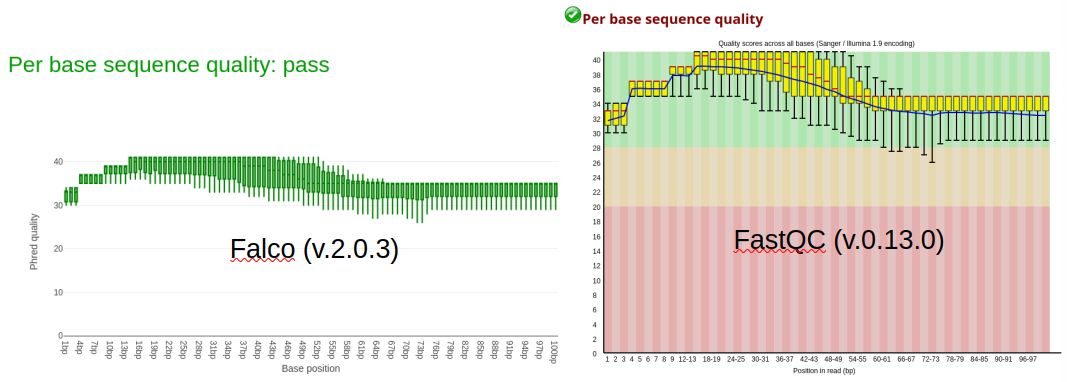
